In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio
import csv
import warnings
warnings.filterwarnings('ignore')
import pywt
import librosa
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split


In [2]:
# Define the LSTM model in PyTorch
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
        
        out, _ = self.lstm(x, (h0, c0))
        out = self.relu(out[:, -1, :])  # Consider only the output of the last time step
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.softmax(out)
        return out


In [3]:
# Define your custom dataset
class SpeechDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [4]:
# Function to calculate evaluation metrics
def calculate_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Convert from one-hot encoding to class labels if needed
    if len(y_true.shape) > 1:
        y_true = np.argmax(y_true, axis=1)
    if len(y_pred.shape) > 1:
        y_pred = np.argmax(y_pred, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1


# Validation function
def validate(model, val_loader, criterion, device):
    model.eval()
    val_loss = 0.0
    y_true = []
    y_pred = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)  # Convert one-hot to class labels
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    accuracy, precision, recall, f1 = calculate_metrics(y_true, y_pred)
    
    return val_loss, accuracy, precision, recall, f1


In [5]:
def plot_graphs(epochs_path,
                num_epochs,
                train_losses,
                val_losses,
                train_accuracies,
                val_accuracies,
                train_precisions,
                val_precisions,
                train_recalls,
                val_recalls,
                train_f1s,
                val_f1s):
    
    
    # Plotting the metrics
    epochs = list(range(num_epochs))

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_losses, label='Training Loss')
    plt.plot(epochs, val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'loss_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_accuracies, label='Training Accuracy')
    plt.plot(epochs, val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'accuracy_plot.png'))
    plt.show()
    plt.close()


    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_precisions, label='Training Precision')
    plt.plot(epochs, val_precisions, label='Validation Precision')
    plt.xlabel('Epochs')
    plt.ylabel('Precision')
    plt.title('Training and Validation Precision')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'precision_plot.png'))
    plt.show()
    plt.close()
    
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, train_recalls, label='Training Recall')
    plt.plot(epochs, val_recalls, label='Validation Recall')
    plt.xlabel('Epochs')
    plt.ylabel('Recall')
    plt.title('Training and Validation Recall')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'recall_plot.png'))
    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))
    
    plt.plot(epochs, train_f1s, label='Training F1-score')
    plt.plot(epochs, val_f1s, label='Validation F1-score')
    plt.xlabel('Epochs')
    plt.ylabel('F1-score')
    plt.title('Training and Validation F1-score')
    plt.legend()
    plt.savefig(os.path.join(epochs_path, 'f1Score_plot.png'))
    plt.show()
    plt.close()

    return "Model Training and Evaluation Successfully completed"

In [6]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def generate_confusion_matrix(model, test_loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = torch.argmax(labels, axis=1).to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())
            
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')        
    print(f"\nAccuracy : {accuracy}\nPrecision : {precision}\nRecall : {recall}\nF1-Score : {f1}")

    conf_matrix = confusion_matrix(y_true, y_pred)
    return conf_matrix

def plot_confusion_matrix(conf_matrix, class_labels,epochs_path):
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted labels')
    plt.ylabel('True labels')
    plt.title('Confusion Matrix')
    plt.xticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)), labels=class_labels)
    plt.savefig(os.path.join(epochs_path, 'Confusion Matrix.png'))
    plt.show()


In [7]:
def train_model():
    
    global mfcc,model
    
    dataset=input("Enter dataset name:\ntess, savee, crema, ravdess\n ")
    mfcc = int(input("Enter N_MFCC:  "))
    
    if dataset=="tess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\tess_dataset.csv"
    
    elif dataset=="savee":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\savee_dataset.csv"
    
    elif dataset=="crema":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\crema_dataset.csv"
    
    elif dataset=="ravdess":
        csv_file=r"C:\Users\Tharunraj_S\Desktop\Major project\Dataset\ravdess_dataset.csv"
    
    
    df = pd.read_csv(csv_file)
    X_mfcc = df['File_Path'].apply(lambda x: extract_mfcc(x,mfcc))
    
    X = [x for x in X_mfcc]
    X = np.array(X)
    ## input split
    X = np.expand_dims(X, -1)
    
    class_labels = df['Emotion_Label'].unique().tolist()
    
    from sklearn.preprocessing import OneHotEncoder
    enc = OneHotEncoder()
    y = enc.fit_transform(df[['Emotion_Label']])
    y = y.toarray()
    
    train_loader, val_loader = Loader(X, y) 
      
    # Determine input size based on wavelet level
    input_size = 1
    hidden_size = 256
    num_layers = 1
        
    # Initialize model
    model = LSTMModel(input_size, hidden_size, num_layers, num_classes)
    print("Training with N_MFCC:", mfcc)
    print(f'Input size : {input_size}\n' 
          f'Hidden Size : {hidden_size}\n' 
          f'Model Name: {model.__class__.__name__}\n' 
          f'\nX Shape : {X.shape}'
          f'\nY Shape : {y.shape}\n')
    
    model_path=model.__class__.__name__
    if not os.path.exists( model_path):
        os.makedirs( model_path)
        
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Reset model parameters
    model.apply(reset_parameters)
    
    # Reset optimizer state
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Initialize variables to store best validation metrics and corresponding model state
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    
    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []
    train_precisions = []
    val_precisions = []
    train_recalls = []
    val_recalls = []
    train_f1s = []
    val_f1s = []
    
    
    num_epochs =int(input("Enter no. of epochs "))
    
    dataset_path = dataset
    dataset_dir = os.path.join(model_path,dataset_path)
    if not os.path.exists(dataset_dir):
        os.makedirs(dataset_dir)
    
    mfcc_level_path = "level "+str(mfcc)+" wavelet"
    mfcc_level_dir = os.path.join(dataset_dir,mfcc_level_path)
    if not os.path.exists(mfcc_level_dir):
        os.makedirs(mfcc_level_dir)
    
    # Create a directory with the name as the number of epochs
    epochs_dir = str(num_epochs)+" Epochs"
    epochs_path = os.path.join(mfcc_level_dir,epochs_dir)
    if not os.path.exists(epochs_path):
        os.makedirs(epochs_path)
        
    with open(os.path.join(epochs_path,'metrics.csv'), mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(['Epoch', 'Training Loss', 'Training Accuracy','Training Precision', 'Training Recall', 'Training F1-Score'
                         , 'Validation Loss', 'Validation Accuracy','Validatio Precision', 'Validatio Recall', 'Validatio F1-Score'])

        for epoch in range(num_epochs):
            model.train()
            running_loss = 0.0

            for inputs, labels in train_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                running_loss += loss.item() * inputs.size(0)

            # Calculate training loss
            train_loss = running_loss / len(train_loader.dataset)
            train_losses.append(train_loss)

            # Calculate training metrics
            y_true_train = []
            y_pred_train = []
            with torch.no_grad():
                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)
                    outputs = model(inputs)
                    _, predicted = torch.max(outputs, 1)
                    y_true_train.extend(labels.cpu().numpy())
                    y_pred_train.extend(predicted.cpu().numpy())

            train_accuracy, train_precision, train_recall, train_f1 = calculate_metrics(y_true_train, y_pred_train)
            train_accuracies.append(train_accuracy)
            train_precisions.append(train_precision)
            train_recalls.append(train_recall)
            train_f1s.append(train_f1)

            # Validate the model
            val_loss, val_accuracy, val_precision, val_recall, val_f1 = validate(model, val_loader, criterion, device)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)
            val_precisions.append(val_precision)
            val_recalls.append(val_recall)
            val_f1s.append(val_f1)

            # Write metrics to CSV
            writer.writerow([epoch+1, train_loss, train_accuracy, train_precision, train_recall, train_f1,
                             val_loss, val_accuracy, val_precision, val_recall, val_f1])


            print(f'Epoch [{epoch+1}/{num_epochs}],\n'
                  f'Training Loss: {train_loss:.4f}, Training Accuracy: {train_accuracy:.4f}, '
                  f'Training Precision:{train_precision:.4f},Training Recall:{train_recall:.4f},Training F1-Score:{train_f1:.4f}\n'
                  f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.4f}, '
                  f'Validation Precision:{val_precision:.4f},Validation Recall:{val_recall:.4f},Validation F1-Score:{val_f1:.4f}'
                  )
            # Save the model
            torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(last).pth'))

            # Save the model if it has the best validation loss so far
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_model_state = model.state_dict()
                torch.save(model.state_dict(), os.path.join(epochs_path, 'LSTM_model_(best).pth'))

    # Load the best model state
    model.load_state_dict(best_model_state)
    conf_matrix = generate_confusion_matrix(model, val_loader, device)
    plot_confusion_matrix(conf_matrix, class_labels,epochs_path)  
    
    return plot_graphs(epochs_path,num_epochs,train_losses,val_losses,train_accuracies,val_accuracies,train_precisions,val_precisions,train_recalls,val_recalls,train_f1s,val_f1s)


def reset_parameters(layer):
    if isinstance(layer, nn.Conv1d) or isinstance(layer, nn.Linear):
        nn.init.xavier_uniform_(layer.weight)
        nn.init.zeros_(layer.bias)

In [8]:
def Loader(X,y):
    
    global num_classes

    
    num_classes = y.shape[1]
    print(f"No. of classes {num_classes}")
    
    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

    train_dataset = SpeechDataset(X_train_tensor, y_train_tensor)
    val_dataset = SpeechDataset(X_test_tensor, y_test_tensor)


    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader= DataLoader(val_dataset, batch_size=64, shuffle=True)

    return train_loader, val_loader

In [9]:
def extract_mfcc(filename, mfcc):
    
    y, sr = librosa.load(filename, duration=3, offset=0.5)
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=mfcc).T, axis=0)
    
    return mfcc

In [10]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# SAVEE

# N_MFCC 16


# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  16
No. of classes 6
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (480, 16, 1)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7840, Training Accuracy: 0.3438, Training Precision:0.1743,Training Recall:0.3438,Training F1-Score:0.2291
Validation Loss: 1.7662, Validation Accuracy: 0.4167, Validation Precision:0.2742,Validation Recall:0.4167,Validation F1-Score:0.3239
Epoch [2/500],
Training Loss: 1.7540, Training Accuracy: 0.3307, Training Precision:0.1675,Training Recall:0.3307,Training F1-Score:0.2202
Validation Loss: 1.6767, Validation Accuracy: 0.4375, Validation Precision:0.2773,Validation Recall:0.4375,Validation F1-Score:0.3357
Epoch [3/500],
Training Loss: 1.7053, Training Accuracy: 0.3359, Training Precision:0.1853,Training Recall:0.3359,Training F1-Score:0.2279
Validation Loss: 1.6625, Validation Accuracy: 0.3854, Validation Precision:0.

Epoch [31/500],
Training Loss: 1.5954, Training Accuracy: 0.4557, Training Precision:0.3365,Training Recall:0.4557,Training F1-Score:0.3765
Validation Loss: 1.5804, Validation Accuracy: 0.4479, Validation Precision:0.3643,Validation Recall:0.4479,Validation F1-Score:0.3784
Epoch [32/500],
Training Loss: 1.5899, Training Accuracy: 0.4583, Training Precision:0.3438,Training Recall:0.4583,Training F1-Score:0.3780
Validation Loss: 1.6033, Validation Accuracy: 0.4271, Validation Precision:0.2931,Validation Recall:0.4271,Validation F1-Score:0.3458
Epoch [33/500],
Training Loss: 1.5815, Training Accuracy: 0.4714, Training Precision:0.3496,Training Recall:0.4714,Training F1-Score:0.3979
Validation Loss: 1.5907, Validation Accuracy: 0.4271, Validation Precision:0.3219,Validation Recall:0.4271,Validation F1-Score:0.3655
Epoch [34/500],
Training Loss: 1.5742, Training Accuracy: 0.4766, Training Precision:0.3526,Training Recall:0.4766,Training F1-Score:0.3955
Validation Loss: 1.5888, Validation Ac

Epoch [61/500],
Training Loss: 1.4438, Training Accuracy: 0.6094, Training Precision:0.6562,Training Recall:0.6094,Training F1-Score:0.5558
Validation Loss: 1.5555, Validation Accuracy: 0.4792, Validation Precision:0.3802,Validation Recall:0.4792,Validation F1-Score:0.4062
Epoch [62/500],
Training Loss: 1.4581, Training Accuracy: 0.6068, Training Precision:0.6185,Training Recall:0.6068,Training F1-Score:0.5662
Validation Loss: 1.5452, Validation Accuracy: 0.4896, Validation Precision:0.5504,Validation Recall:0.4896,Validation F1-Score:0.4580
Epoch [63/500],
Training Loss: 1.4552, Training Accuracy: 0.6042, Training Precision:0.6022,Training Recall:0.6042,Training F1-Score:0.5576
Validation Loss: 1.5430, Validation Accuracy: 0.5000, Validation Precision:0.4389,Validation Recall:0.5000,Validation F1-Score:0.4556
Epoch [64/500],
Training Loss: 1.4468, Training Accuracy: 0.6406, Training Precision:0.6486,Training Recall:0.6406,Training F1-Score:0.5966
Validation Loss: 1.5286, Validation Ac

Epoch [91/500],
Training Loss: 1.2762, Training Accuracy: 0.7734, Training Precision:0.7738,Training Recall:0.7734,Training F1-Score:0.7570
Validation Loss: 1.5307, Validation Accuracy: 0.5000, Validation Precision:0.5268,Validation Recall:0.5000,Validation F1-Score:0.4821
Epoch [92/500],
Training Loss: 1.2731, Training Accuracy: 0.7760, Training Precision:0.7773,Training Recall:0.7760,Training F1-Score:0.7596
Validation Loss: 1.5444, Validation Accuracy: 0.4792, Validation Precision:0.4681,Validation Recall:0.4792,Validation F1-Score:0.4484
Epoch [93/500],
Training Loss: 1.2689, Training Accuracy: 0.7786, Training Precision:0.7859,Training Recall:0.7786,Training F1-Score:0.7617
Validation Loss: 1.5435, Validation Accuracy: 0.4896, Validation Precision:0.5203,Validation Recall:0.4896,Validation F1-Score:0.4841
Epoch [94/500],
Training Loss: 1.2677, Training Accuracy: 0.7786, Training Precision:0.8011,Training Recall:0.7786,Training F1-Score:0.7614
Validation Loss: 1.5332, Validation Ac

Epoch [121/500],
Training Loss: 1.2558, Training Accuracy: 0.7943, Training Precision:0.8042,Training Recall:0.7943,Training F1-Score:0.7810
Validation Loss: 1.5223, Validation Accuracy: 0.5208, Validation Precision:0.5148,Validation Recall:0.5208,Validation F1-Score:0.5003
Epoch [122/500],
Training Loss: 1.2545, Training Accuracy: 0.7943, Training Precision:0.8072,Training Recall:0.7943,Training F1-Score:0.7796
Validation Loss: 1.5354, Validation Accuracy: 0.5000, Validation Precision:0.5123,Validation Recall:0.5000,Validation F1-Score:0.4870
Epoch [123/500],
Training Loss: 1.2505, Training Accuracy: 0.7943, Training Precision:0.8047,Training Recall:0.7943,Training F1-Score:0.7799
Validation Loss: 1.5137, Validation Accuracy: 0.5312, Validation Precision:0.5461,Validation Recall:0.5312,Validation F1-Score:0.5132
Epoch [124/500],
Training Loss: 1.2521, Training Accuracy: 0.7969, Training Precision:0.8024,Training Recall:0.7969,Training F1-Score:0.7828
Validation Loss: 1.5232, Validatio

...

Epoch [361/500],
Training Loss: 1.1445, Training Accuracy: 0.8984, Training Precision:0.9049,Training Recall:0.8984,Training F1-Score:0.8977
Validation Loss: 1.4834, Validation Accuracy: 0.5625, Validation Precision:0.5593,Validation Recall:0.5625,Validation F1-Score:0.5562
Epoch [362/500],
Training Loss: 1.1435, Training Accuracy: 0.8984, Training Precision:0.9053,Training Recall:0.8984,Training F1-Score:0.8977
Validation Loss: 1.4760, Validation Accuracy: 0.5729, Validation Precision:0.5635,Validation Recall:0.5729,Validation F1-Score:0.5628
Epoch [363/500],
Training Loss: 1.1434, Training Accuracy: 0.8984, Training Precision:0.9046,Training Recall:0.8984,Training F1-Score:0.8976
Validation Loss: 1.4781, Validation Accuracy: 0.5521, Validation Precision:0.5438,Validation Recall:0.5521,Validation F1-Score:0.5435
Epoch [364/500],
Training Loss: 1.1438, Training Accuracy: 0.8984, Training Precision:0.9044,Training Recall:0.8984,Training F1-Score:0.8977
Validation Loss: 1.4792, Validatio

Epoch [391/500],
Training Loss: 1.1397, Training Accuracy: 0.9010, Training Precision:0.9092,Training Recall:0.9010,Training F1-Score:0.9006
Validation Loss: 1.4907, Validation Accuracy: 0.5312, Validation Precision:0.5271,Validation Recall:0.5312,Validation F1-Score:0.5248
Epoch [392/500],
Training Loss: 1.1395, Training Accuracy: 0.9010, Training Precision:0.9060,Training Recall:0.9010,Training F1-Score:0.9001
Validation Loss: 1.4922, Validation Accuracy: 0.5312, Validation Precision:0.5271,Validation Recall:0.5312,Validation F1-Score:0.5248
Epoch [393/500],
Training Loss: 1.1395, Training Accuracy: 0.9010, Training Precision:0.9049,Training Recall:0.9010,Training F1-Score:0.9001
Validation Loss: 1.4922, Validation Accuracy: 0.5312, Validation Precision:0.5271,Validation Recall:0.5312,Validation F1-Score:0.5248
Epoch [394/500],
Training Loss: 1.1395, Training Accuracy: 0.9010, Training Precision:0.9098,Training Recall:0.9010,Training F1-Score:0.9009
Validation Loss: 1.4908, Validatio

Epoch [421/500],
Training Loss: 1.1392, Training Accuracy: 0.9010, Training Precision:0.9082,Training Recall:0.9010,Training F1-Score:0.9007
Validation Loss: 1.5116, Validation Accuracy: 0.5208, Validation Precision:0.5317,Validation Recall:0.5208,Validation F1-Score:0.5217
Epoch [422/500],
Training Loss: 1.1392, Training Accuracy: 0.9010, Training Precision:0.9073,Training Recall:0.9010,Training F1-Score:0.9004
Validation Loss: 1.5129, Validation Accuracy: 0.5208, Validation Precision:0.5317,Validation Recall:0.5208,Validation F1-Score:0.5217
Epoch [423/500],
Training Loss: 1.1393, Training Accuracy: 0.9010, Training Precision:0.9081,Training Recall:0.9010,Training F1-Score:0.9005
Validation Loss: 1.5035, Validation Accuracy: 0.5208, Validation Precision:0.5207,Validation Recall:0.5208,Validation F1-Score:0.5167
Epoch [424/500],
Training Loss: 1.1391, Training Accuracy: 0.9010, Training Precision:0.9042,Training Recall:0.9010,Training F1-Score:0.8999
Validation Loss: 1.5110, Validatio

Epoch [451/500],
Training Loss: 1.1391, Training Accuracy: 0.9010, Training Precision:0.9078,Training Recall:0.9010,Training F1-Score:0.9005
Validation Loss: 1.5010, Validation Accuracy: 0.5208, Validation Precision:0.5219,Validation Recall:0.5208,Validation F1-Score:0.5170
Epoch [452/500],
Training Loss: 1.1391, Training Accuracy: 0.9010, Training Precision:0.9041,Training Recall:0.9010,Training F1-Score:0.8999
Validation Loss: 1.5030, Validation Accuracy: 0.5208, Validation Precision:0.5219,Validation Recall:0.5208,Validation F1-Score:0.5170
Epoch [453/500],
Training Loss: 1.1391, Training Accuracy: 0.9010, Training Precision:0.9075,Training Recall:0.9010,Training F1-Score:0.9004
Validation Loss: 1.4971, Validation Accuracy: 0.5208, Validation Precision:0.5219,Validation Recall:0.5208,Validation F1-Score:0.5170
Epoch [454/500],
Training Loss: 1.1391, Training Accuracy: 0.9010, Training Precision:0.9088,Training Recall:0.9010,Training F1-Score:0.9008
Validation Loss: 1.4947, Validatio

Epoch [481/500],
Training Loss: 1.1389, Training Accuracy: 0.9010, Training Precision:0.9081,Training Recall:0.9010,Training F1-Score:0.9005
Validation Loss: 1.4933, Validation Accuracy: 0.5312, Validation Precision:0.5271,Validation Recall:0.5312,Validation F1-Score:0.5248
Epoch [482/500],
Training Loss: 1.1389, Training Accuracy: 0.9010, Training Precision:0.9064,Training Recall:0.9010,Training F1-Score:0.9002
Validation Loss: 1.4942, Validation Accuracy: 0.5312, Validation Precision:0.5271,Validation Recall:0.5312,Validation F1-Score:0.5248
Epoch [483/500],
Training Loss: 1.1389, Training Accuracy: 0.9010, Training Precision:0.9073,Training Recall:0.9010,Training F1-Score:0.9004
Validation Loss: 1.4925, Validation Accuracy: 0.5417, Validation Precision:0.5324,Validation Recall:0.5417,Validation F1-Score:0.5326
Epoch [484/500],
Training Loss: 1.1389, Training Accuracy: 0.9010, Training Precision:0.9098,Training Recall:0.9010,Training F1-Score:0.9008
Validation Loss: 1.4925, Validatio

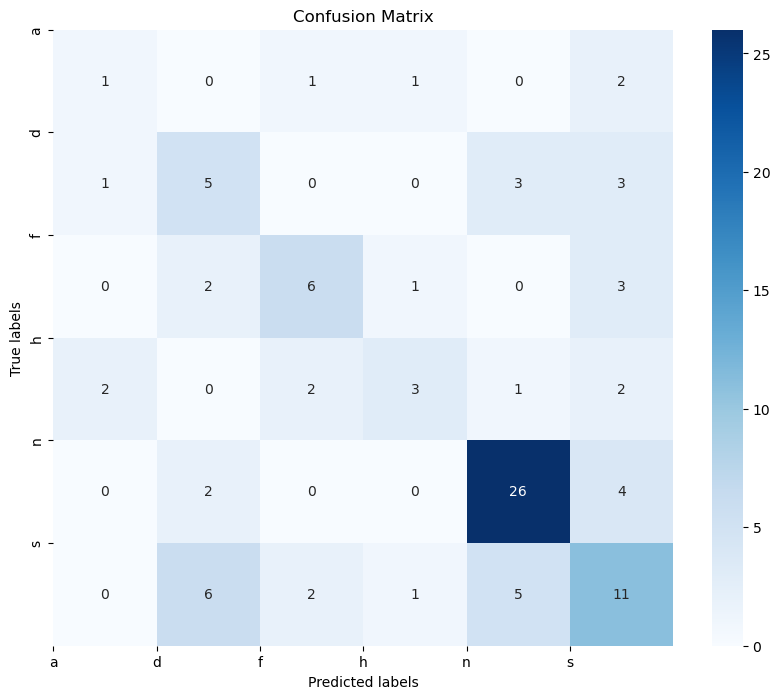

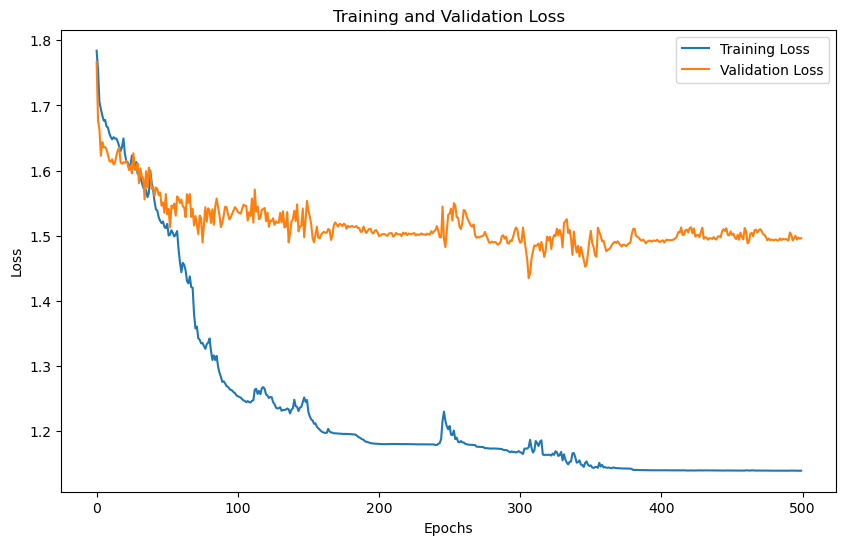

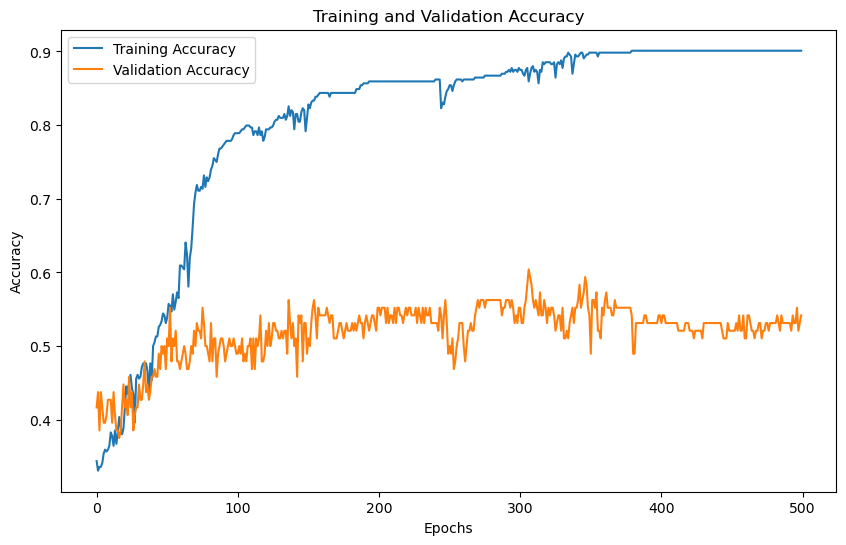

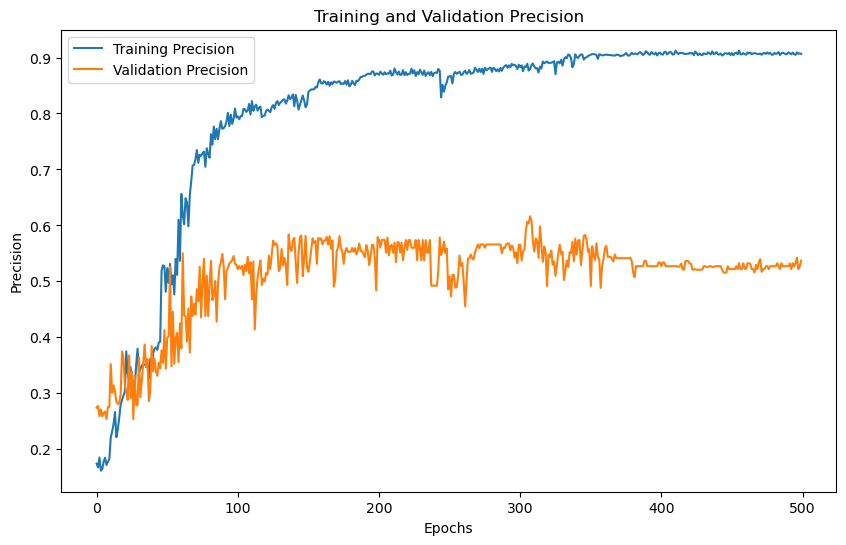

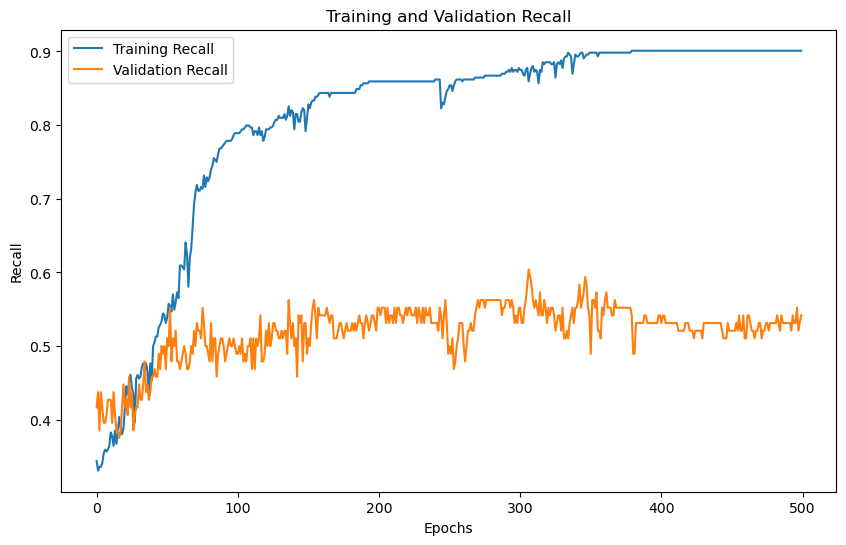

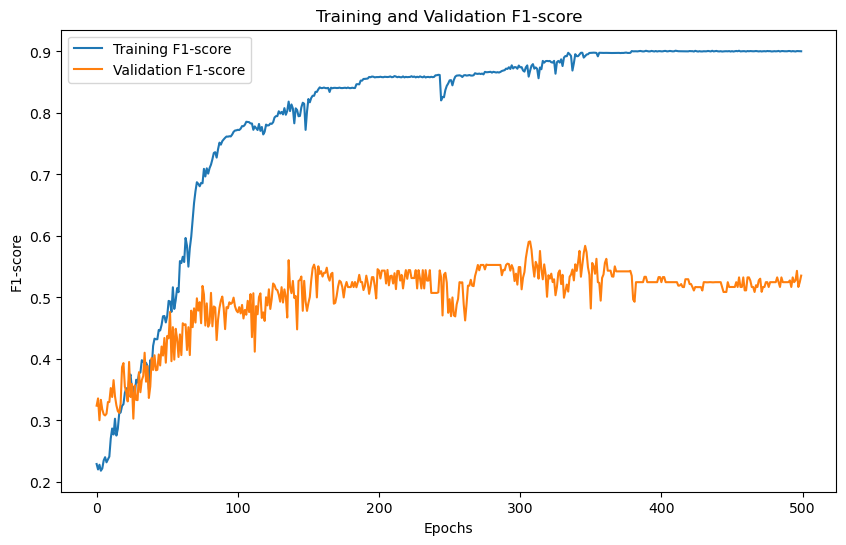

'Model Training and Evaluation Successfully completed'

In [17]:
train_model()

# N_MFCC= 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  24
No. of classes 6
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (480, 24, 1)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7875, Training Accuracy: 0.3542, Training Precision:0.2236,Training Recall:0.3542,Training F1-Score:0.2610
Validation Loss: 1.7803, Validation Accuracy: 0.4062, Validation Precision:0.2652,Validation Recall:0.4062,Validation F1-Score:0.3102
Epoch [2/500],
Training Loss: 1.7725, Training Accuracy: 0.3542, Training Precision:0.3097,Training Recall:0.3542,Training F1-Score:0.2819
Validation Loss: 1.7430, Validation Accuracy: 0.3854, Validation Precision:0.2325,Validation Recall:0.3854,Validation F1-Score:0.2620
Epoch [3/500],
Training Loss: 1.7155, Training Accuracy: 0.3594, Training Precision:0.2500,Training Recall:0.3594,Training F1-Score:0.2659
Validation Loss: 1.6344, Validation Accuracy: 0.4062, Validation Precision:0.

Epoch [31/500],
Training Loss: 1.5324, Training Accuracy: 0.5443, Training Precision:0.4909,Training Recall:0.5443,Training F1-Score:0.4982
Validation Loss: 1.5451, Validation Accuracy: 0.4792, Validation Precision:0.4878,Validation Recall:0.4792,Validation F1-Score:0.4388
Epoch [32/500],
Training Loss: 1.5262, Training Accuracy: 0.5286, Training Precision:0.4809,Training Recall:0.5286,Training F1-Score:0.4903
Validation Loss: 1.5563, Validation Accuracy: 0.4583, Validation Precision:0.4167,Validation Recall:0.4583,Validation F1-Score:0.4266
Epoch [33/500],
Training Loss: 1.5186, Training Accuracy: 0.5391, Training Precision:0.4979,Training Recall:0.5391,Training F1-Score:0.4979
Validation Loss: 1.5511, Validation Accuracy: 0.4688, Validation Precision:0.4447,Validation Recall:0.4688,Validation F1-Score:0.4293
Epoch [34/500],
Training Loss: 1.5151, Training Accuracy: 0.5469, Training Precision:0.4941,Training Recall:0.5469,Training F1-Score:0.5051
Validation Loss: 1.5668, Validation Ac

Epoch [61/500],
Training Loss: 1.4060, Training Accuracy: 0.6562, Training Precision:0.5874,Training Recall:0.6562,Training F1-Score:0.6073
Validation Loss: 1.5161, Validation Accuracy: 0.5312, Validation Precision:0.5109,Validation Recall:0.5312,Validation F1-Score:0.4906
Epoch [62/500],
Training Loss: 1.3997, Training Accuracy: 0.6510, Training Precision:0.5792,Training Recall:0.6510,Training F1-Score:0.6010
Validation Loss: 1.5245, Validation Accuracy: 0.5104, Validation Precision:0.5016,Validation Recall:0.5104,Validation F1-Score:0.4761
Epoch [63/500],
Training Loss: 1.3995, Training Accuracy: 0.6536, Training Precision:0.5876,Training Recall:0.6536,Training F1-Score:0.6050
Validation Loss: 1.5268, Validation Accuracy: 0.5104, Validation Precision:0.4851,Validation Recall:0.5104,Validation F1-Score:0.4718
Epoch [64/500],
Training Loss: 1.3931, Training Accuracy: 0.6562, Training Precision:0.5836,Training Recall:0.6562,Training F1-Score:0.6090
Validation Loss: 1.5589, Validation Ac

Epoch [91/500],
Training Loss: 1.3569, Training Accuracy: 0.7188, Training Precision:0.7305,Training Recall:0.7188,Training F1-Score:0.7039
Validation Loss: 1.5228, Validation Accuracy: 0.5000, Validation Precision:0.5148,Validation Recall:0.5000,Validation F1-Score:0.4931
Epoch [92/500],
Training Loss: 1.3323, Training Accuracy: 0.7292, Training Precision:0.7426,Training Recall:0.7292,Training F1-Score:0.7180
Validation Loss: 1.5223, Validation Accuracy: 0.5417, Validation Precision:0.5814,Validation Recall:0.5417,Validation F1-Score:0.5291
Epoch [93/500],
Training Loss: 1.3265, Training Accuracy: 0.7266, Training Precision:0.7351,Training Recall:0.7266,Training F1-Score:0.7166
Validation Loss: 1.5062, Validation Accuracy: 0.5521, Validation Precision:0.5765,Validation Recall:0.5521,Validation F1-Score:0.5412
Epoch [94/500],
Training Loss: 1.3309, Training Accuracy: 0.7188, Training Precision:0.7337,Training Recall:0.7188,Training F1-Score:0.7034
Validation Loss: 1.5248, Validation Ac

Epoch [121/500],
Training Loss: 1.3893, Training Accuracy: 0.6432, Training Precision:0.6515,Training Recall:0.6432,Training F1-Score:0.6300
Validation Loss: 1.5961, Validation Accuracy: 0.4375, Validation Precision:0.4857,Validation Recall:0.4375,Validation F1-Score:0.4344
Epoch [122/500],
Training Loss: 1.4425, Training Accuracy: 0.5859, Training Precision:0.6027,Training Recall:0.5859,Training F1-Score:0.5715
Validation Loss: 1.5834, Validation Accuracy: 0.4479, Validation Precision:0.5457,Validation Recall:0.4479,Validation F1-Score:0.4696
Epoch [123/500],
Training Loss: 1.4578, Training Accuracy: 0.6042, Training Precision:0.6112,Training Recall:0.6042,Training F1-Score:0.5721
Validation Loss: 1.5465, Validation Accuracy: 0.4896, Validation Precision:0.5286,Validation Recall:0.4896,Validation F1-Score:0.4660
Epoch [124/500],
Training Loss: 1.4572, Training Accuracy: 0.5964, Training Precision:0.6590,Training Recall:0.5964,Training F1-Score:0.5677
Validation Loss: 1.4941, Validatio

...

Epoch [361/500],
Training Loss: 1.2151, Training Accuracy: 0.8229, Training Precision:0.8263,Training Recall:0.8229,Training F1-Score:0.8232
Validation Loss: 1.5240, Validation Accuracy: 0.5208, Validation Precision:0.5370,Validation Recall:0.5208,Validation F1-Score:0.5176
Epoch [362/500],
Training Loss: 1.2151, Training Accuracy: 0.8229, Training Precision:0.8266,Training Recall:0.8229,Training F1-Score:0.8226
Validation Loss: 1.5260, Validation Accuracy: 0.5104, Validation Precision:0.5333,Validation Recall:0.5104,Validation F1-Score:0.5101
Epoch [363/500],
Training Loss: 1.2151, Training Accuracy: 0.8229, Training Precision:0.8323,Training Recall:0.8229,Training F1-Score:0.8236
Validation Loss: 1.5231, Validation Accuracy: 0.5312, Validation Precision:0.5466,Validation Recall:0.5312,Validation F1-Score:0.5283
Epoch [364/500],
Training Loss: 1.2151, Training Accuracy: 0.8229, Training Precision:0.8259,Training Recall:0.8229,Training F1-Score:0.8230
Validation Loss: 1.5219, Validatio

Epoch [391/500],
Training Loss: 1.2130, Training Accuracy: 0.8255, Training Precision:0.8269,Training Recall:0.8255,Training F1-Score:0.8252
Validation Loss: 1.5226, Validation Accuracy: 0.5208, Validation Precision:0.5370,Validation Recall:0.5208,Validation F1-Score:0.5176
Epoch [392/500],
Training Loss: 1.2127, Training Accuracy: 0.8255, Training Precision:0.8296,Training Recall:0.8255,Training F1-Score:0.8260
Validation Loss: 1.5157, Validation Accuracy: 0.5312, Validation Precision:0.5466,Validation Recall:0.5312,Validation F1-Score:0.5283
Epoch [393/500],
Training Loss: 1.2127, Training Accuracy: 0.8255, Training Precision:0.8326,Training Recall:0.8255,Training F1-Score:0.8259
Validation Loss: 1.5190, Validation Accuracy: 0.5312, Validation Precision:0.5534,Validation Recall:0.5312,Validation F1-Score:0.5312
Epoch [394/500],
Training Loss: 1.2127, Training Accuracy: 0.8255, Training Precision:0.8287,Training Recall:0.8255,Training F1-Score:0.8258
Validation Loss: 1.5207, Validatio

Epoch [421/500],
Training Loss: 1.2125, Training Accuracy: 0.8255, Training Precision:0.8290,Training Recall:0.8255,Training F1-Score:0.8259
Validation Loss: 1.5201, Validation Accuracy: 0.5312, Validation Precision:0.5466,Validation Recall:0.5312,Validation F1-Score:0.5283
Epoch [422/500],
Training Loss: 1.2126, Training Accuracy: 0.8255, Training Precision:0.8310,Training Recall:0.8255,Training F1-Score:0.8255
Validation Loss: 1.5171, Validation Accuracy: 0.5312, Validation Precision:0.5466,Validation Recall:0.5312,Validation F1-Score:0.5283
Epoch [423/500],
Training Loss: 1.2125, Training Accuracy: 0.8255, Training Precision:0.8306,Training Recall:0.8255,Training F1-Score:0.8264
Validation Loss: 1.5210, Validation Accuracy: 0.5208, Validation Precision:0.5499,Validation Recall:0.5208,Validation F1-Score:0.5236
Epoch [424/500],
Training Loss: 1.2127, Training Accuracy: 0.8255, Training Precision:0.8286,Training Recall:0.8255,Training F1-Score:0.8252
Validation Loss: 1.5214, Validatio

Epoch [451/500],
Training Loss: 1.2124, Training Accuracy: 0.8255, Training Precision:0.8311,Training Recall:0.8255,Training F1-Score:0.8263
Validation Loss: 1.5255, Validation Accuracy: 0.5104, Validation Precision:0.5333,Validation Recall:0.5104,Validation F1-Score:0.5101
Epoch [452/500],
Training Loss: 1.2126, Training Accuracy: 0.8255, Training Precision:0.8301,Training Recall:0.8255,Training F1-Score:0.8257
Validation Loss: 1.5230, Validation Accuracy: 0.5104, Validation Precision:0.5263,Validation Recall:0.5104,Validation F1-Score:0.5072
Epoch [453/500],
Training Loss: 1.2126, Training Accuracy: 0.8255, Training Precision:0.8285,Training Recall:0.8255,Training F1-Score:0.8257
Validation Loss: 1.5211, Validation Accuracy: 0.5104, Validation Precision:0.5333,Validation Recall:0.5104,Validation F1-Score:0.5101
Epoch [454/500],
Training Loss: 1.2125, Training Accuracy: 0.8255, Training Precision:0.8301,Training Recall:0.8255,Training F1-Score:0.8257
Validation Loss: 1.5227, Validatio

Epoch [481/500],
Training Loss: 1.2124, Training Accuracy: 0.8255, Training Precision:0.8296,Training Recall:0.8255,Training F1-Score:0.8258
Validation Loss: 1.5204, Validation Accuracy: 0.5208, Validation Precision:0.5499,Validation Recall:0.5208,Validation F1-Score:0.5236
Epoch [482/500],
Training Loss: 1.2125, Training Accuracy: 0.8255, Training Precision:0.8317,Training Recall:0.8255,Training F1-Score:0.8264
Validation Loss: 1.5140, Validation Accuracy: 0.5208, Validation Precision:0.5357,Validation Recall:0.5208,Validation F1-Score:0.5178
Epoch [483/500],
Training Loss: 1.2126, Training Accuracy: 0.8255, Training Precision:0.8328,Training Recall:0.8255,Training F1-Score:0.8255
Validation Loss: 1.5201, Validation Accuracy: 0.5208, Validation Precision:0.5427,Validation Recall:0.5208,Validation F1-Score:0.5206
Epoch [484/500],
Training Loss: 1.2124, Training Accuracy: 0.8255, Training Precision:0.8279,Training Recall:0.8255,Training F1-Score:0.8253
Validation Loss: 1.5202, Validatio

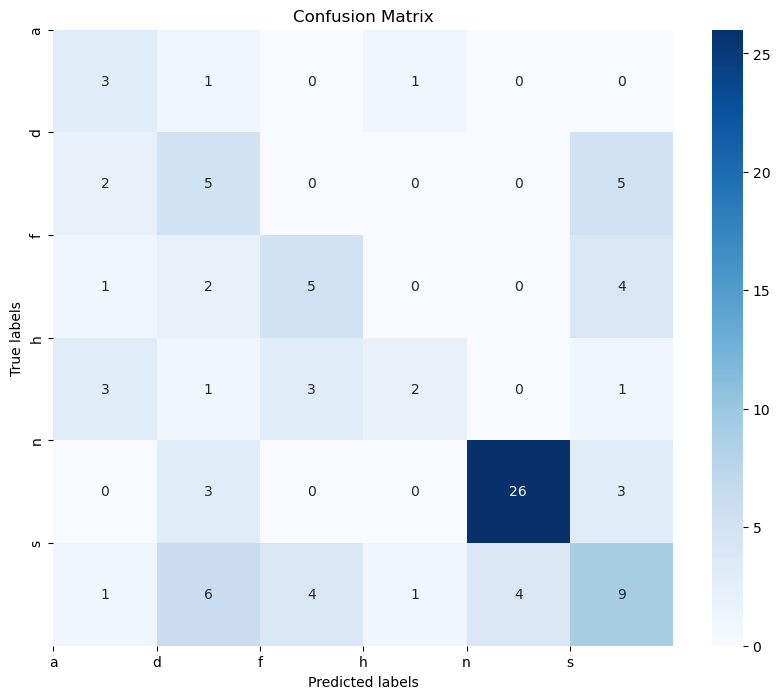

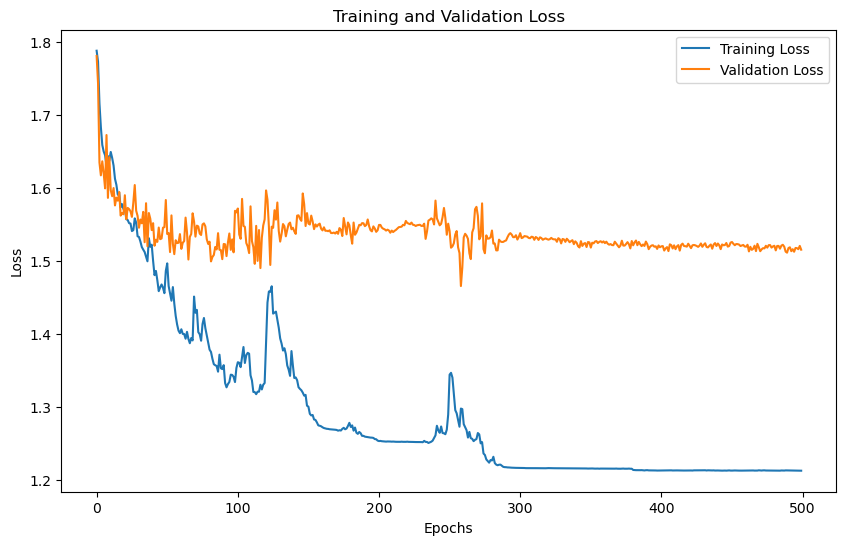

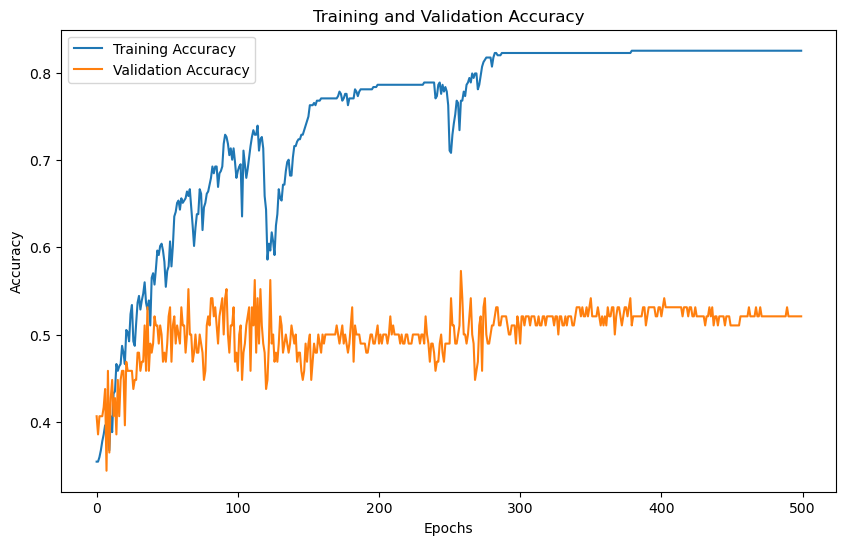

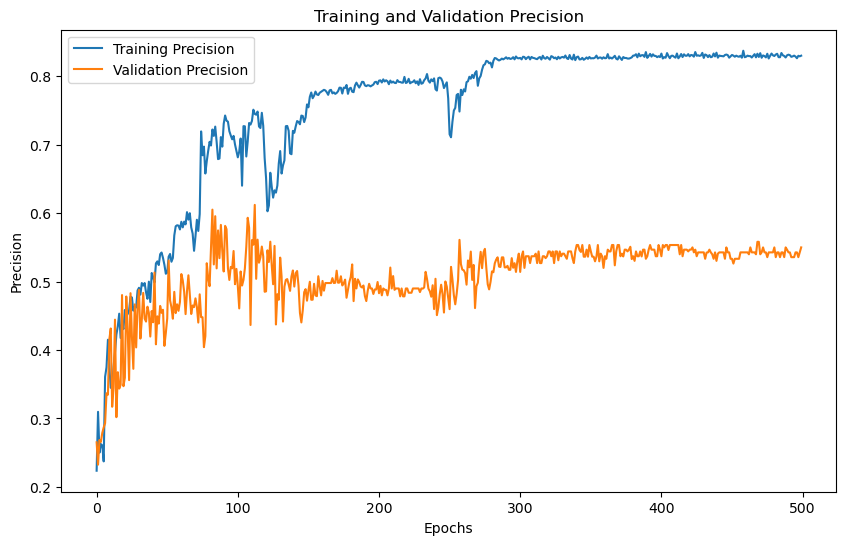

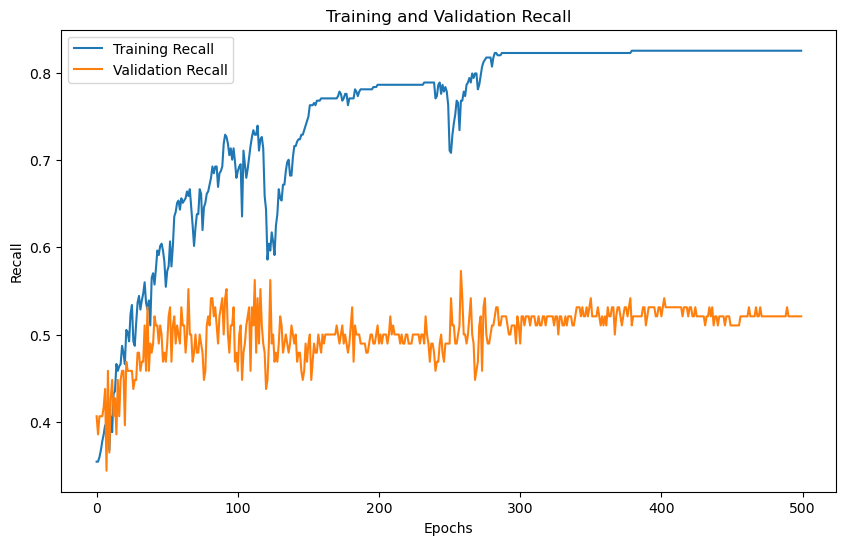

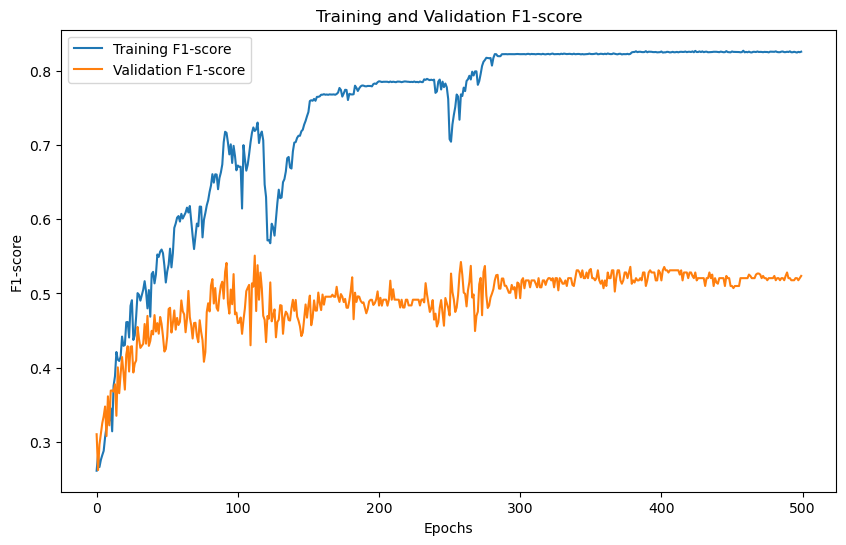

'Model Training and Evaluation Successfully completed'

In [18]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  32
No. of classes 6
Training with N_MFCC: 32
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (480, 32, 1)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7869, Training Accuracy: 0.3776, Training Precision:0.3605,Training Recall:0.3776,Training F1-Score:0.2942
Validation Loss: 1.7809, Validation Accuracy: 0.3438, Validation Precision:0.2656,Validation Recall:0.3438,Validation F1-Score:0.2978
Epoch [2/500],
Training Loss: 1.7676, Training Accuracy: 0.3802, Training Precision:0.3094,Training Recall:0.3802,Training F1-Score:0.3269
Validation Loss: 1.7585, Validation Accuracy: 0.3646, Validation Precision:0.3694,Validation Recall:0.3646,Validation F1-Score:0.3481
Epoch [3/500],
Training Loss: 1.7263, Training Accuracy: 0.3932, Training Precision:0.3762,Training Recall:0.3932,Training F1-Score:0.3055
Validation Loss: 1.6756, Validation Accuracy: 0.3958, Validation Precision:0.

Epoch [31/500],
Training Loss: 1.5391, Training Accuracy: 0.5417, Training Precision:0.5075,Training Recall:0.5417,Training F1-Score:0.4962
Validation Loss: 1.5495, Validation Accuracy: 0.4688, Validation Precision:0.4646,Validation Recall:0.4688,Validation F1-Score:0.4193
Epoch [32/500],
Training Loss: 1.5113, Training Accuracy: 0.5078, Training Precision:0.4651,Training Recall:0.5078,Training F1-Score:0.4605
Validation Loss: 1.5485, Validation Accuracy: 0.4896, Validation Precision:0.4476,Validation Recall:0.4896,Validation F1-Score:0.4349
Epoch [33/500],
Training Loss: 1.5466, Training Accuracy: 0.5104, Training Precision:0.4693,Training Recall:0.5104,Training F1-Score:0.4690
Validation Loss: 1.5700, Validation Accuracy: 0.4583, Validation Precision:0.4373,Validation Recall:0.4583,Validation F1-Score:0.4207
Epoch [34/500],
Training Loss: 1.5504, Training Accuracy: 0.5443, Training Precision:0.5067,Training Recall:0.5443,Training F1-Score:0.4968
Validation Loss: 1.5471, Validation Ac

Epoch [61/500],
Training Loss: 1.4874, Training Accuracy: 0.5911, Training Precision:0.5175,Training Recall:0.5911,Training F1-Score:0.5428
Validation Loss: 1.5324, Validation Accuracy: 0.4896, Validation Precision:0.4412,Validation Recall:0.4896,Validation F1-Score:0.4353
Epoch [62/500],
Training Loss: 1.4716, Training Accuracy: 0.6094, Training Precision:0.5490,Training Recall:0.6094,Training F1-Score:0.5610
Validation Loss: 1.5246, Validation Accuracy: 0.5104, Validation Precision:0.4563,Validation Recall:0.5104,Validation F1-Score:0.4563
Epoch [63/500],
Training Loss: 1.4769, Training Accuracy: 0.5885, Training Precision:0.5292,Training Recall:0.5885,Training F1-Score:0.5415
Validation Loss: 1.5313, Validation Accuracy: 0.5208, Validation Precision:0.5151,Validation Recall:0.5208,Validation F1-Score:0.4827
Epoch [64/500],
Training Loss: 1.4770, Training Accuracy: 0.5339, Training Precision:0.4936,Training Recall:0.5339,Training F1-Score:0.4892
Validation Loss: 1.5126, Validation Ac

Epoch [91/500],
Training Loss: 1.3800, Training Accuracy: 0.6458, Training Precision:0.5910,Training Recall:0.6458,Training F1-Score:0.5994
Validation Loss: 1.4740, Validation Accuracy: 0.5625, Validation Precision:0.5270,Validation Recall:0.5625,Validation F1-Score:0.5169
Epoch [92/500],
Training Loss: 1.3926, Training Accuracy: 0.6693, Training Precision:0.5940,Training Recall:0.6693,Training F1-Score:0.6218
Validation Loss: 1.5070, Validation Accuracy: 0.5104, Validation Precision:0.4994,Validation Recall:0.5104,Validation F1-Score:0.4762
Epoch [93/500],
Training Loss: 1.3828, Training Accuracy: 0.6641, Training Precision:0.5884,Training Recall:0.6641,Training F1-Score:0.6159
Validation Loss: 1.4878, Validation Accuracy: 0.5521, Validation Precision:0.4992,Validation Recall:0.5521,Validation F1-Score:0.5097
Epoch [94/500],
Training Loss: 1.3872, Training Accuracy: 0.6719, Training Precision:0.5894,Training Recall:0.6719,Training F1-Score:0.6248
Validation Loss: 1.4908, Validation Ac

Epoch [121/500],
Training Loss: 1.3339, Training Accuracy: 0.7083, Training Precision:0.6228,Training Recall:0.7083,Training F1-Score:0.6589
Validation Loss: 1.4902, Validation Accuracy: 0.5521, Validation Precision:0.4893,Validation Recall:0.5521,Validation F1-Score:0.5142
Epoch [122/500],
Training Loss: 1.3263, Training Accuracy: 0.7240, Training Precision:0.6379,Training Recall:0.7240,Training F1-Score:0.6742
Validation Loss: 1.4709, Validation Accuracy: 0.5729, Validation Precision:0.5071,Validation Recall:0.5729,Validation F1-Score:0.5338
Epoch [123/500],
Training Loss: 1.3424, Training Accuracy: 0.7161, Training Precision:0.6314,Training Recall:0.7161,Training F1-Score:0.6666
Validation Loss: 1.4723, Validation Accuracy: 0.5729, Validation Precision:0.5412,Validation Recall:0.5729,Validation F1-Score:0.5387
Epoch [124/500],
Training Loss: 1.3302, Training Accuracy: 0.7188, Training Precision:0.6387,Training Recall:0.7188,Training F1-Score:0.6697
Validation Loss: 1.4798, Validatio

...

Epoch [361/500],
Training Loss: 1.2659, Training Accuracy: 0.7786, Training Precision:0.7905,Training Recall:0.7786,Training F1-Score:0.7659
Validation Loss: 1.5515, Validation Accuracy: 0.4792, Validation Precision:0.4877,Validation Recall:0.4792,Validation F1-Score:0.4605
Epoch [362/500],
Training Loss: 1.2659, Training Accuracy: 0.7812, Training Precision:0.7940,Training Recall:0.7812,Training F1-Score:0.7686
Validation Loss: 1.5594, Validation Accuracy: 0.4688, Validation Precision:0.4792,Validation Recall:0.4688,Validation F1-Score:0.4552
Epoch [363/500],
Training Loss: 1.2620, Training Accuracy: 0.7812, Training Precision:0.7941,Training Recall:0.7812,Training F1-Score:0.7686
Validation Loss: 1.5497, Validation Accuracy: 0.4896, Validation Precision:0.4934,Validation Recall:0.4896,Validation F1-Score:0.4776
Epoch [364/500],
Training Loss: 1.2614, Training Accuracy: 0.7812, Training Precision:0.7925,Training Recall:0.7812,Training F1-Score:0.7683
Validation Loss: 1.5450, Validatio

Epoch [391/500],
Training Loss: 1.2905, Training Accuracy: 0.7656, Training Precision:0.7774,Training Recall:0.7656,Training F1-Score:0.7527
Validation Loss: 1.4506, Validation Accuracy: 0.5833, Validation Precision:0.5884,Validation Recall:0.5833,Validation F1-Score:0.5679
Epoch [392/500],
Training Loss: 1.2863, Training Accuracy: 0.7656, Training Precision:0.7617,Training Recall:0.7656,Training F1-Score:0.7552
Validation Loss: 1.4989, Validation Accuracy: 0.5521, Validation Precision:0.5695,Validation Recall:0.5521,Validation F1-Score:0.5445
Epoch [393/500],
Training Loss: 1.2821, Training Accuracy: 0.7734, Training Precision:0.7895,Training Recall:0.7734,Training F1-Score:0.7588
Validation Loss: 1.5335, Validation Accuracy: 0.4896, Validation Precision:0.5542,Validation Recall:0.4896,Validation F1-Score:0.4760
Epoch [394/500],
Training Loss: 1.2833, Training Accuracy: 0.7786, Training Precision:0.7908,Training Recall:0.7786,Training F1-Score:0.7646
Validation Loss: 1.5037, Validatio

Epoch [421/500],
Training Loss: 1.2727, Training Accuracy: 0.7760, Training Precision:0.7780,Training Recall:0.7760,Training F1-Score:0.7647
Validation Loss: 1.4900, Validation Accuracy: 0.5625, Validation Precision:0.6097,Validation Recall:0.5625,Validation F1-Score:0.5539
Epoch [422/500],
Training Loss: 1.2652, Training Accuracy: 0.7708, Training Precision:0.7788,Training Recall:0.7708,Training F1-Score:0.7580
Validation Loss: 1.5041, Validation Accuracy: 0.5312, Validation Precision:0.6080,Validation Recall:0.5312,Validation F1-Score:0.5293
Epoch [423/500],
Training Loss: 1.2703, Training Accuracy: 0.7891, Training Precision:0.7946,Training Recall:0.7891,Training F1-Score:0.7754
Validation Loss: 1.5214, Validation Accuracy: 0.5000, Validation Precision:0.5581,Validation Recall:0.5000,Validation F1-Score:0.4871
Epoch [424/500],
Training Loss: 1.2594, Training Accuracy: 0.7891, Training Precision:0.7966,Training Recall:0.7891,Training F1-Score:0.7756
Validation Loss: 1.4997, Validatio

Epoch [451/500],
Training Loss: 1.2337, Training Accuracy: 0.8073, Training Precision:0.8223,Training Recall:0.8073,Training F1-Score:0.7947
Validation Loss: 1.5034, Validation Accuracy: 0.5312, Validation Precision:0.5449,Validation Recall:0.5312,Validation F1-Score:0.5038
Epoch [452/500],
Training Loss: 1.2338, Training Accuracy: 0.8073, Training Precision:0.8213,Training Recall:0.8073,Training F1-Score:0.7945
Validation Loss: 1.5045, Validation Accuracy: 0.5312, Validation Precision:0.5449,Validation Recall:0.5312,Validation F1-Score:0.5038
Epoch [453/500],
Training Loss: 1.2336, Training Accuracy: 0.8073, Training Precision:0.8223,Training Recall:0.8073,Training F1-Score:0.7946
Validation Loss: 1.5063, Validation Accuracy: 0.5208, Validation Precision:0.5376,Validation Recall:0.5208,Validation F1-Score:0.4959
Epoch [454/500],
Training Loss: 1.2337, Training Accuracy: 0.8073, Training Precision:0.8196,Training Recall:0.8073,Training F1-Score:0.7948
Validation Loss: 1.5090, Validatio

Epoch [481/500],
Training Loss: 1.2333, Training Accuracy: 0.8073, Training Precision:0.8219,Training Recall:0.8073,Training F1-Score:0.7946
Validation Loss: 1.5158, Validation Accuracy: 0.5104, Validation Precision:0.5279,Validation Recall:0.5104,Validation F1-Score:0.4901
Epoch [482/500],
Training Loss: 1.2331, Training Accuracy: 0.8073, Training Precision:0.8221,Training Recall:0.8073,Training F1-Score:0.7946
Validation Loss: 1.5144, Validation Accuracy: 0.5208, Validation Precision:0.5425,Validation Recall:0.5208,Validation F1-Score:0.4980
Epoch [483/500],
Training Loss: 1.2333, Training Accuracy: 0.8073, Training Precision:0.8250,Training Recall:0.8073,Training F1-Score:0.7953
Validation Loss: 1.5168, Validation Accuracy: 0.5104, Validation Precision:0.5279,Validation Recall:0.5104,Validation F1-Score:0.4901
Epoch [484/500],
Training Loss: 1.2333, Training Accuracy: 0.8073, Training Precision:0.8220,Training Recall:0.8073,Training F1-Score:0.7945
Validation Loss: 1.5176, Validatio

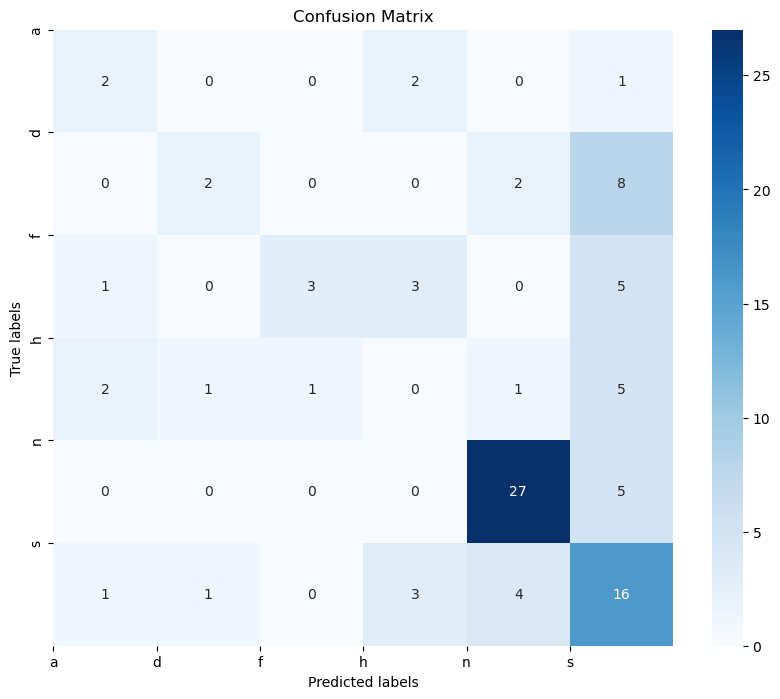

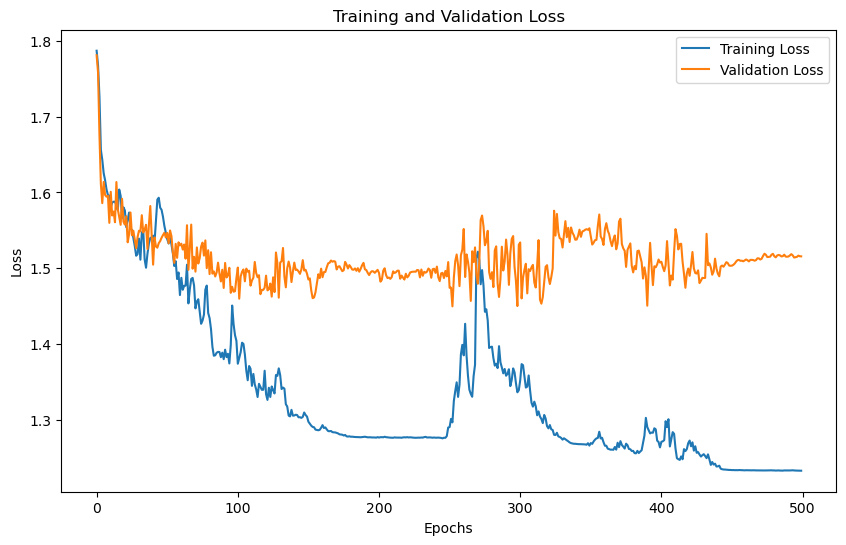

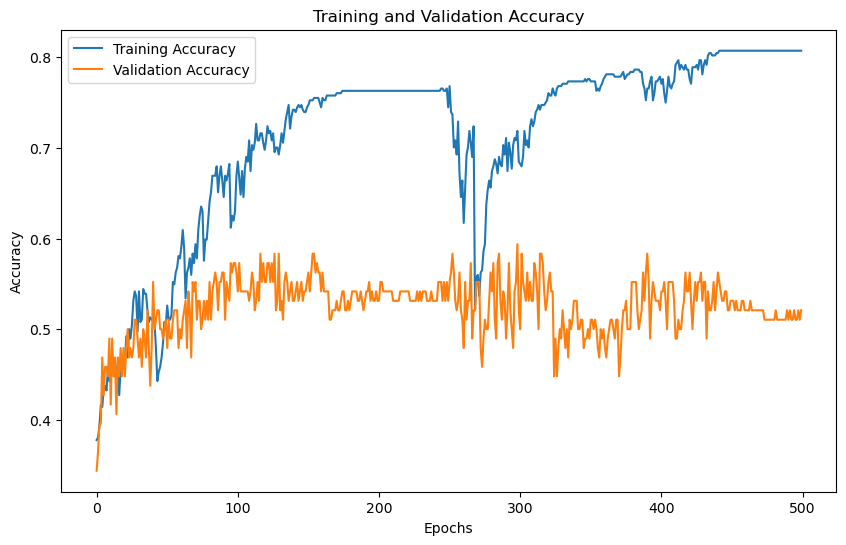

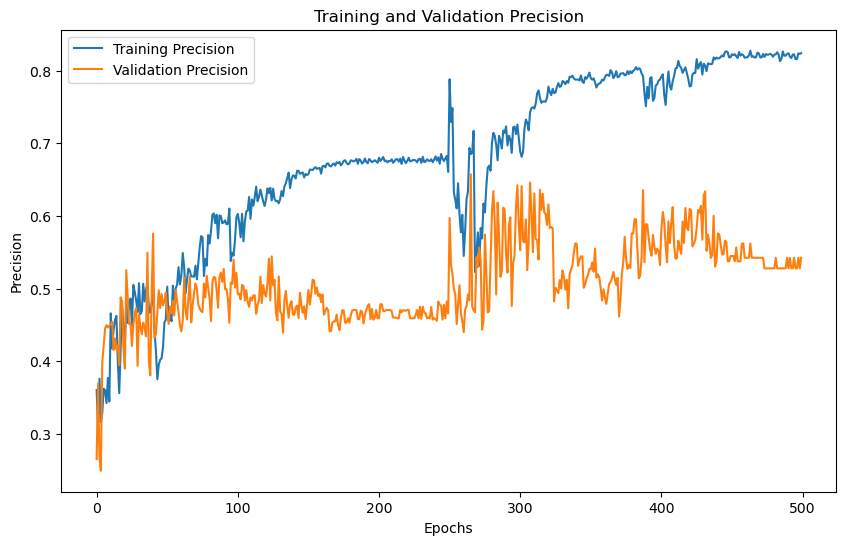

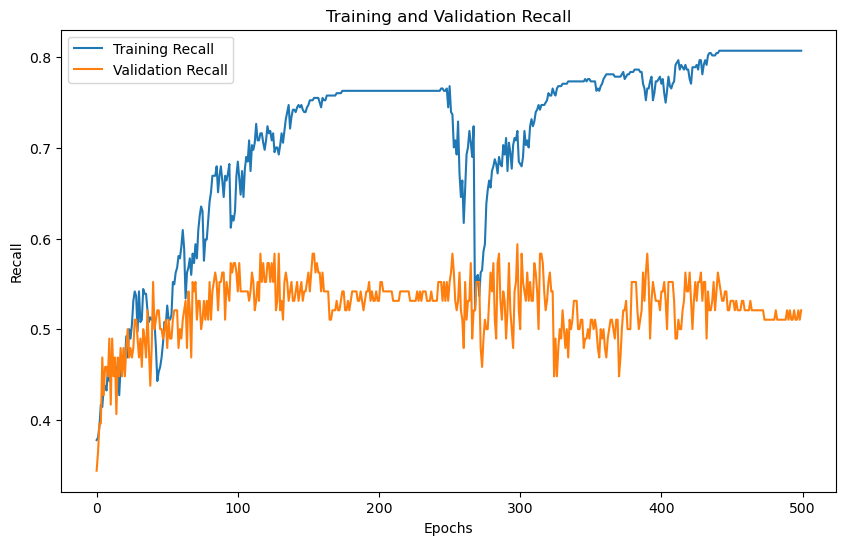

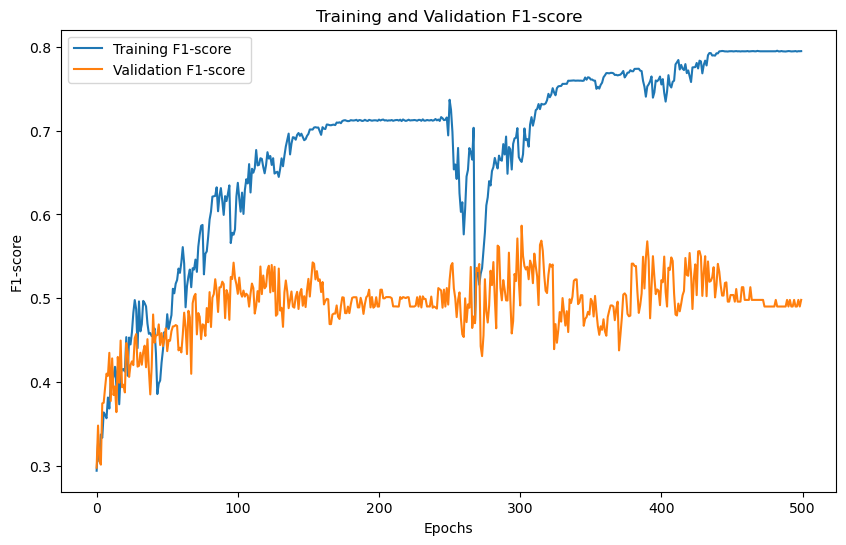

'Model Training and Evaluation Successfully completed'

In [20]:
train_model()

# N_MFCC 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 savee
Enter N_MFCC:  40
No. of classes 6
Training with N_MFCC: 40
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (480, 40, 1)
Y Shape : (480, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7827, Training Accuracy: 0.3151, Training Precision:0.1701,Training Recall:0.3151,Training F1-Score:0.2053
Validation Loss: 1.7568, Validation Accuracy: 0.3750, Validation Precision:0.2946,Validation Recall:0.3750,Validation F1-Score:0.2979
Epoch [2/500],
Training Loss: 1.7496, Training Accuracy: 0.3281, Training Precision:0.1738,Training Recall:0.3281,Training F1-Score:0.2149
Validation Loss: 1.7093, Validation Accuracy: 0.4062, Validation Precision:0.3180,Validation Recall:0.4062,Validation F1-Score:0.3280
Epoch [3/500],
Training Loss: 1.7124, Training Accuracy: 0.3932, Training Precision:0.1874,Training Recall:0.3932,Training F1-Score:0.2515
Validation Loss: 1.6085, Validation Accuracy: 0.4896, Validation Precision:0.

Epoch [31/500],
Training Loss: 1.5600, Training Accuracy: 0.4844, Training Precision:0.4439,Training Recall:0.4844,Training F1-Score:0.4217
Validation Loss: 1.5217, Validation Accuracy: 0.5000, Validation Precision:0.5215,Validation Recall:0.5000,Validation F1-Score:0.4613
Epoch [32/500],
Training Loss: 1.5468, Training Accuracy: 0.4948, Training Precision:0.4691,Training Recall:0.4948,Training F1-Score:0.4280
Validation Loss: 1.4694, Validation Accuracy: 0.5625, Validation Precision:0.4691,Validation Recall:0.5625,Validation F1-Score:0.5017
Epoch [33/500],
Training Loss: 1.5445, Training Accuracy: 0.5312, Training Precision:0.5435,Training Recall:0.5312,Training F1-Score:0.4593
Validation Loss: 1.5122, Validation Accuracy: 0.5312, Validation Precision:0.4864,Validation Recall:0.5312,Validation F1-Score:0.4752
Epoch [34/500],
Training Loss: 1.5318, Training Accuracy: 0.5547, Training Precision:0.5210,Training Recall:0.5547,Training F1-Score:0.4921
Validation Loss: 1.5012, Validation Ac

Epoch [61/500],
Training Loss: 1.4869, Training Accuracy: 0.5417, Training Precision:0.5472,Training Recall:0.5417,Training F1-Score:0.5044
Validation Loss: 1.4830, Validation Accuracy: 0.5521, Validation Precision:0.5943,Validation Recall:0.5521,Validation F1-Score:0.5137
Epoch [62/500],
Training Loss: 1.4889, Training Accuracy: 0.5755, Training Precision:0.5911,Training Recall:0.5755,Training F1-Score:0.5323
Validation Loss: 1.4810, Validation Accuracy: 0.5417, Validation Precision:0.5139,Validation Recall:0.5417,Validation F1-Score:0.4913
Epoch [63/500],
Training Loss: 1.4757, Training Accuracy: 0.5833, Training Precision:0.5895,Training Recall:0.5833,Training F1-Score:0.5498
Validation Loss: 1.4625, Validation Accuracy: 0.5833, Validation Precision:0.5832,Validation Recall:0.5833,Validation F1-Score:0.5468
Epoch [64/500],
Training Loss: 1.4706, Training Accuracy: 0.5599, Training Precision:0.5626,Training Recall:0.5599,Training F1-Score:0.5169
Validation Loss: 1.4803, Validation Ac

Epoch [91/500],
Training Loss: 1.4645, Training Accuracy: 0.5807, Training Precision:0.6088,Training Recall:0.5807,Training F1-Score:0.5513
Validation Loss: 1.4704, Validation Accuracy: 0.5625, Validation Precision:0.5601,Validation Recall:0.5625,Validation F1-Score:0.5207
Epoch [92/500],
Training Loss: 1.4528, Training Accuracy: 0.5990, Training Precision:0.6167,Training Recall:0.5990,Training F1-Score:0.5689
Validation Loss: 1.4569, Validation Accuracy: 0.5833, Validation Precision:0.6217,Validation Recall:0.5833,Validation F1-Score:0.5557
Epoch [93/500],
Training Loss: 1.4485, Training Accuracy: 0.5807, Training Precision:0.5891,Training Recall:0.5807,Training F1-Score:0.5568
Validation Loss: 1.4487, Validation Accuracy: 0.6042, Validation Precision:0.6377,Validation Recall:0.6042,Validation F1-Score:0.5795
Epoch [94/500],
Training Loss: 1.4497, Training Accuracy: 0.5807, Training Precision:0.6053,Training Recall:0.5807,Training F1-Score:0.5474
Validation Loss: 1.4627, Validation Ac

Epoch [121/500],
Training Loss: 1.4558, Training Accuracy: 0.5990, Training Precision:0.5865,Training Recall:0.5990,Training F1-Score:0.5750
Validation Loss: 1.4496, Validation Accuracy: 0.5833, Validation Precision:0.5584,Validation Recall:0.5833,Validation F1-Score:0.5420
Epoch [122/500],
Training Loss: 1.4296, Training Accuracy: 0.6276, Training Precision:0.6257,Training Recall:0.6276,Training F1-Score:0.6089
Validation Loss: 1.4356, Validation Accuracy: 0.5938, Validation Precision:0.5597,Validation Recall:0.5938,Validation F1-Score:0.5452
Epoch [123/500],
Training Loss: 1.4256, Training Accuracy: 0.6250, Training Precision:0.6211,Training Recall:0.6250,Training F1-Score:0.6020
Validation Loss: 1.4457, Validation Accuracy: 0.5938, Validation Precision:0.5877,Validation Recall:0.5938,Validation F1-Score:0.5567
Epoch [124/500],
Training Loss: 1.4081, Training Accuracy: 0.6406, Training Precision:0.6499,Training Recall:0.6406,Training F1-Score:0.6191
Validation Loss: 1.4401, Validatio

...

Epoch [361/500],
Training Loss: 1.2808, Training Accuracy: 0.7656, Training Precision:0.7741,Training Recall:0.7656,Training F1-Score:0.7594
Validation Loss: 1.4458, Validation Accuracy: 0.5938, Validation Precision:0.6173,Validation Recall:0.5938,Validation F1-Score:0.5851
Epoch [362/500],
Training Loss: 1.2672, Training Accuracy: 0.7917, Training Precision:0.8045,Training Recall:0.7917,Training F1-Score:0.7853
Validation Loss: 1.4282, Validation Accuracy: 0.6146, Validation Precision:0.6499,Validation Recall:0.6146,Validation F1-Score:0.5943
Epoch [363/500],
Training Loss: 1.2602, Training Accuracy: 0.7969, Training Precision:0.8087,Training Recall:0.7969,Training F1-Score:0.7939
Validation Loss: 1.4436, Validation Accuracy: 0.5938, Validation Precision:0.6188,Validation Recall:0.5938,Validation F1-Score:0.5765
Epoch [364/500],
Training Loss: 1.2596, Training Accuracy: 0.7760, Training Precision:0.7909,Training Recall:0.7760,Training F1-Score:0.7754
Validation Loss: 1.4588, Validatio

Epoch [391/500],
Training Loss: 1.2484, Training Accuracy: 0.8073, Training Precision:0.8179,Training Recall:0.8073,Training F1-Score:0.8042
Validation Loss: 1.4694, Validation Accuracy: 0.5625, Validation Precision:0.5772,Validation Recall:0.5625,Validation F1-Score:0.5472
Epoch [392/500],
Training Loss: 1.2337, Training Accuracy: 0.8099, Training Precision:0.8196,Training Recall:0.8099,Training F1-Score:0.8040
Validation Loss: 1.4630, Validation Accuracy: 0.5729, Validation Precision:0.5714,Validation Recall:0.5729,Validation F1-Score:0.5542
Epoch [393/500],
Training Loss: 1.2387, Training Accuracy: 0.8021, Training Precision:0.8115,Training Recall:0.8021,Training F1-Score:0.7950
Validation Loss: 1.4786, Validation Accuracy: 0.5625, Validation Precision:0.6128,Validation Recall:0.5625,Validation F1-Score:0.5473
Epoch [394/500],
Training Loss: 1.2396, Training Accuracy: 0.8099, Training Precision:0.8305,Training Recall:0.8099,Training F1-Score:0.8066
Validation Loss: 1.4366, Validatio

Epoch [421/500],
Training Loss: 1.2477, Training Accuracy: 0.8073, Training Precision:0.8161,Training Recall:0.8073,Training F1-Score:0.8060
Validation Loss: 1.5182, Validation Accuracy: 0.5208, Validation Precision:0.5701,Validation Recall:0.5208,Validation F1-Score:0.5284
Epoch [422/500],
Training Loss: 1.2475, Training Accuracy: 0.8125, Training Precision:0.8200,Training Recall:0.8125,Training F1-Score:0.8088
Validation Loss: 1.4595, Validation Accuracy: 0.5833, Validation Precision:0.6151,Validation Recall:0.5833,Validation F1-Score:0.5836
Epoch [423/500],
Training Loss: 1.2387, Training Accuracy: 0.8203, Training Precision:0.8327,Training Recall:0.8203,Training F1-Score:0.8178
Validation Loss: 1.4874, Validation Accuracy: 0.5521, Validation Precision:0.5833,Validation Recall:0.5521,Validation F1-Score:0.5500
Epoch [424/500],
Training Loss: 1.2276, Training Accuracy: 0.8203, Training Precision:0.8322,Training Recall:0.8203,Training F1-Score:0.8165
Validation Loss: 1.4638, Validatio

Epoch [451/500],
Training Loss: 1.2175, Training Accuracy: 0.8307, Training Precision:0.8421,Training Recall:0.8307,Training F1-Score:0.8280
Validation Loss: 1.4859, Validation Accuracy: 0.5521, Validation Precision:0.5994,Validation Recall:0.5521,Validation F1-Score:0.5449
Epoch [452/500],
Training Loss: 1.2128, Training Accuracy: 0.8359, Training Precision:0.8459,Training Recall:0.8359,Training F1-Score:0.8336
Validation Loss: 1.4992, Validation Accuracy: 0.5417, Validation Precision:0.5873,Validation Recall:0.5417,Validation F1-Score:0.5247
Epoch [453/500],
Training Loss: 1.2074, Training Accuracy: 0.8359, Training Precision:0.8470,Training Recall:0.8359,Training F1-Score:0.8335
Validation Loss: 1.4870, Validation Accuracy: 0.5625, Validation Precision:0.5792,Validation Recall:0.5625,Validation F1-Score:0.5451
Epoch [454/500],
Training Loss: 1.2068, Training Accuracy: 0.8359, Training Precision:0.8436,Training Recall:0.8359,Training F1-Score:0.8333
Validation Loss: 1.4985, Validatio

Epoch [481/500],
Training Loss: 1.2024, Training Accuracy: 0.8411, Training Precision:0.8522,Training Recall:0.8411,Training F1-Score:0.8390
Validation Loss: 1.4959, Validation Accuracy: 0.5417, Validation Precision:0.5397,Validation Recall:0.5417,Validation F1-Score:0.5256
Epoch [482/500],
Training Loss: 1.2014, Training Accuracy: 0.8411, Training Precision:0.8521,Training Recall:0.8411,Training F1-Score:0.8390
Validation Loss: 1.4941, Validation Accuracy: 0.5417, Validation Precision:0.5388,Validation Recall:0.5417,Validation F1-Score:0.5255
Epoch [483/500],
Training Loss: 1.2009, Training Accuracy: 0.8411, Training Precision:0.8517,Training Recall:0.8411,Training F1-Score:0.8388
Validation Loss: 1.4939, Validation Accuracy: 0.5521, Validation Precision:0.5486,Validation Recall:0.5521,Validation F1-Score:0.5358
Epoch [484/500],
Training Loss: 1.2004, Training Accuracy: 0.8411, Training Precision:0.8503,Training Recall:0.8411,Training F1-Score:0.8388
Validation Loss: 1.4956, Validatio

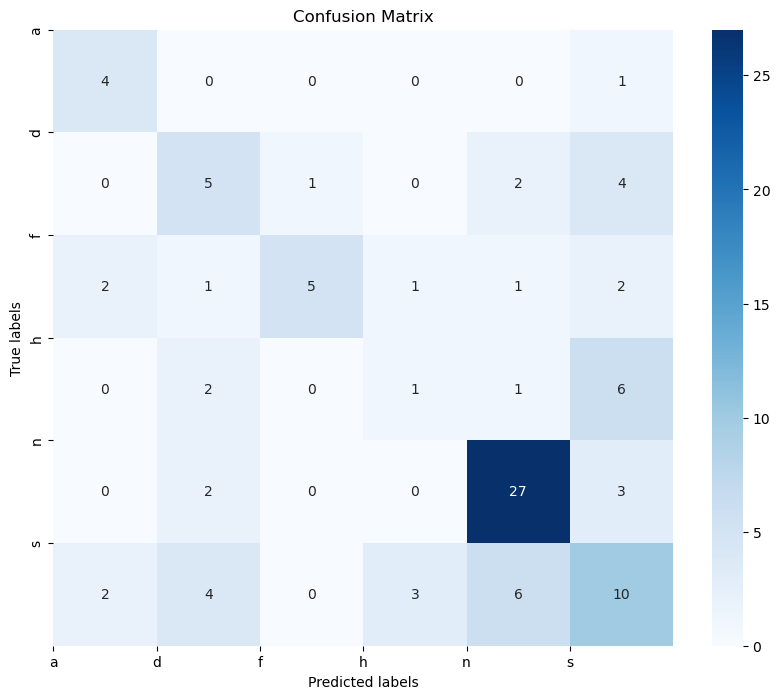

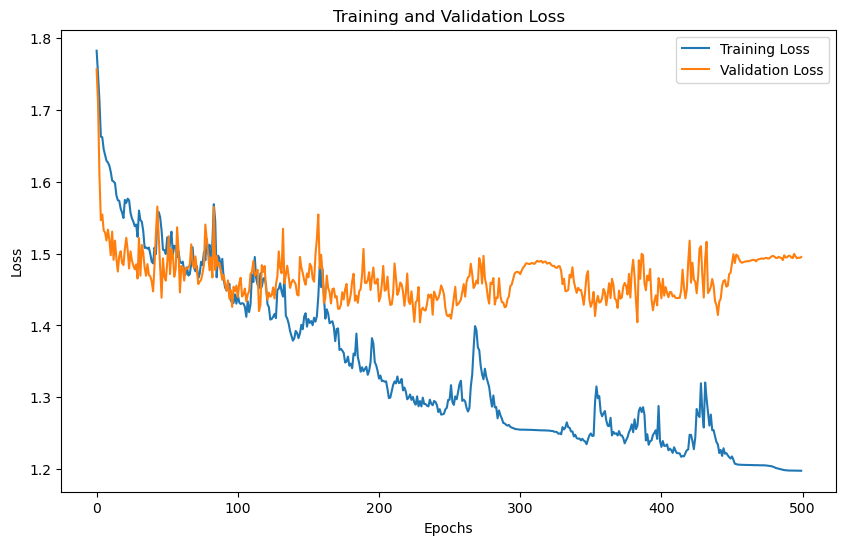

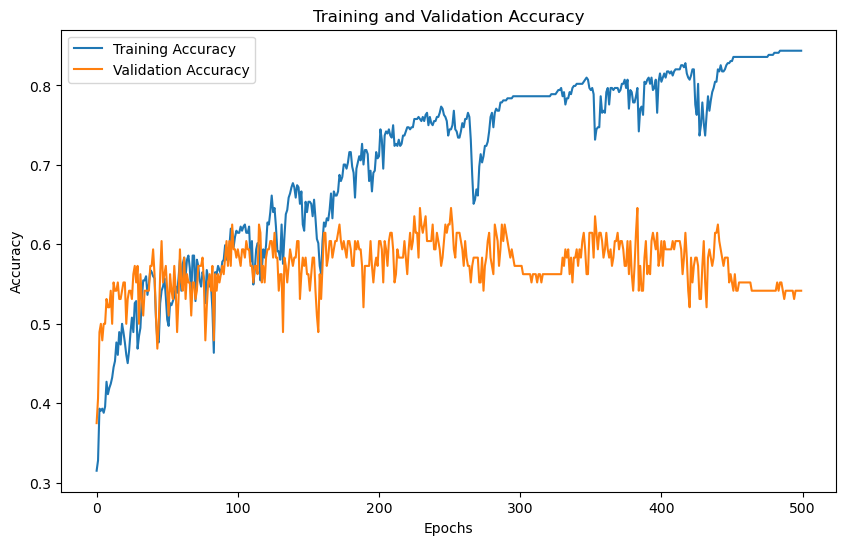

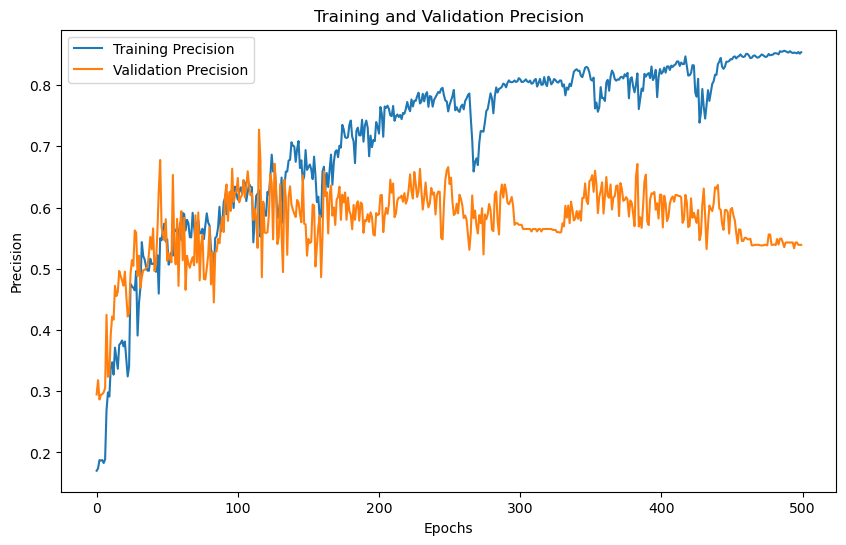

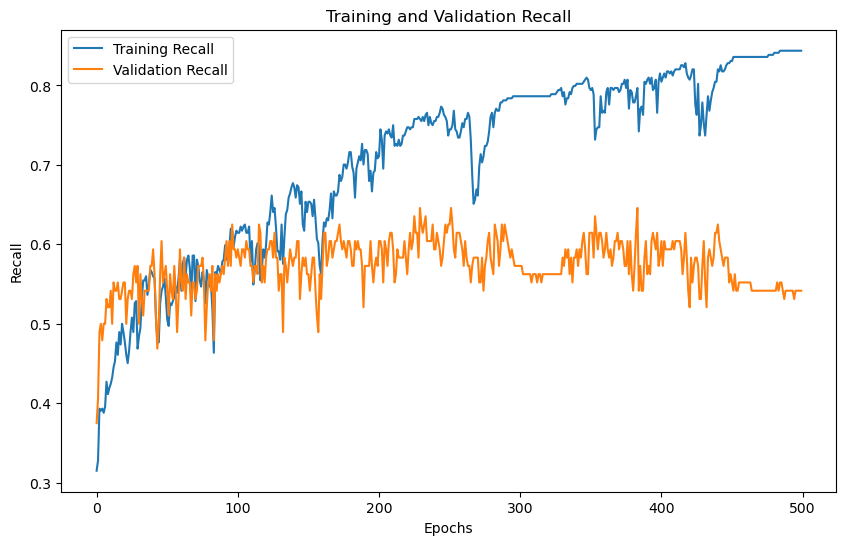

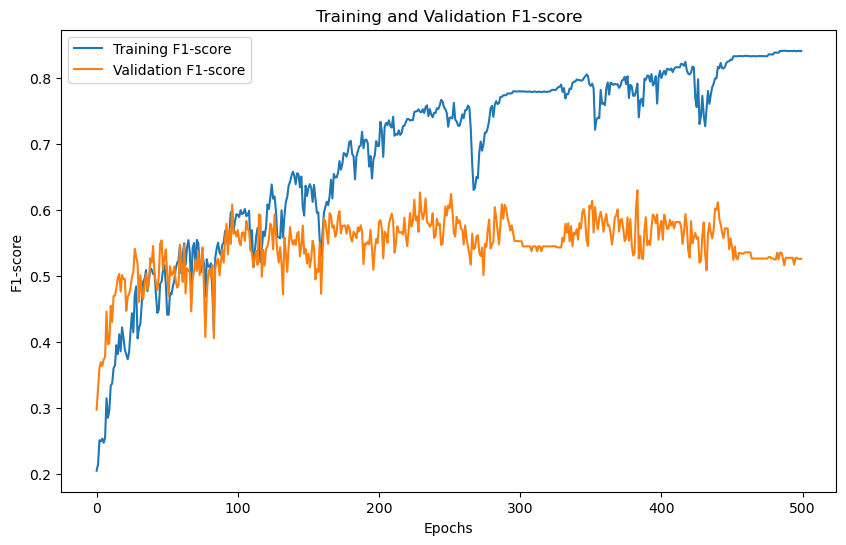

'Model Training and Evaluation Successfully completed'

In [21]:
train_model()

# RAVDESS

# N_MFCC 16

# 300 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  16
No. of classes 8
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 16, 1)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0747, Training Accuracy: 0.1467, Training Precision:0.0970,Training Recall:0.1467,Training F1-Score:0.0555
Validation Loss: 2.0723, Validation Accuracy: 0.1285, Validation Precision:0.1398,Validation Recall:0.1285,Validation F1-Score:0.0573
Epoch [2/500],
Training Loss: 2.0587, Training Accuracy: 0.2222, Training Precision:0.1256,Training Recall:0.2222,Training F1-Score:0.1401
Validation Loss: 2.0493, Validation Accuracy: 0.1771, Validation Precision:0.0722,Validation Recall:0.1771,Validation F1-Score:0.0977
Epoch [3/500],
Training Loss: 2.0366, Training Accuracy: 0.2031, Training Precision:0.1218,Training Recall:0.2031,Training F1-Score:0.1337
Validation Loss: 2.0345, Validation Accuracy: 0.1979, Validation Precisio

Epoch [31/500],
Training Loss: 1.8546, Training Accuracy: 0.4297, Training Precision:0.3975,Training Recall:0.4297,Training F1-Score:0.4045
Validation Loss: 1.9086, Validation Accuracy: 0.3611, Validation Precision:0.3514,Validation Recall:0.3611,Validation F1-Score:0.3381
Epoch [32/500],
Training Loss: 1.8583, Training Accuracy: 0.4132, Training Precision:0.4214,Training Recall:0.4132,Training F1-Score:0.3833
Validation Loss: 1.9605, Validation Accuracy: 0.2986, Validation Precision:0.3020,Validation Recall:0.2986,Validation F1-Score:0.2650
Epoch [33/500],
Training Loss: 1.8985, Training Accuracy: 0.3724, Training Precision:0.3698,Training Recall:0.3724,Training F1-Score:0.3100
Validation Loss: 1.9255, Validation Accuracy: 0.3368, Validation Precision:0.3936,Validation Recall:0.3368,Validation F1-Score:0.2876
Epoch [34/500],
Training Loss: 1.8859, Training Accuracy: 0.3845, Training Precision:0.3930,Training Recall:0.3845,Training F1-Score:0.3508
Validation Loss: 1.9212, Validation Ac

Epoch [61/500],
Training Loss: 1.6557, Training Accuracy: 0.6302, Training Precision:0.6036,Training Recall:0.6302,Training F1-Score:0.6059
Validation Loss: 1.8274, Validation Accuracy: 0.4410, Validation Precision:0.4324,Validation Recall:0.4410,Validation F1-Score:0.4167
Epoch [62/500],
Training Loss: 1.6502, Training Accuracy: 0.6380, Training Precision:0.6120,Training Recall:0.6380,Training F1-Score:0.6145
Validation Loss: 1.8320, Validation Accuracy: 0.4306, Validation Precision:0.4123,Validation Recall:0.4306,Validation F1-Score:0.4064
Epoch [63/500],
Training Loss: 1.6474, Training Accuracy: 0.6380, Training Precision:0.6076,Training Recall:0.6380,Training F1-Score:0.6104
Validation Loss: 1.8250, Validation Accuracy: 0.4340, Validation Precision:0.4128,Validation Recall:0.4340,Validation F1-Score:0.4062
Epoch [64/500],
Training Loss: 1.6456, Training Accuracy: 0.6285, Training Precision:0.6019,Training Recall:0.6285,Training F1-Score:0.5995
Validation Loss: 1.8141, Validation Ac

Epoch [91/500],
Training Loss: 1.5714, Training Accuracy: 0.7040, Training Precision:0.6695,Training Recall:0.7040,Training F1-Score:0.6768
Validation Loss: 1.7996, Validation Accuracy: 0.4792, Validation Precision:0.4666,Validation Recall:0.4792,Validation F1-Score:0.4547
Epoch [92/500],
Training Loss: 1.5712, Training Accuracy: 0.7092, Training Precision:0.6733,Training Recall:0.7092,Training F1-Score:0.6816
Validation Loss: 1.8072, Validation Accuracy: 0.4618, Validation Precision:0.4636,Validation Recall:0.4618,Validation F1-Score:0.4392
Epoch [93/500],
Training Loss: 1.5661, Training Accuracy: 0.7066, Training Precision:0.6699,Training Recall:0.7066,Training F1-Score:0.6777
Validation Loss: 1.8042, Validation Accuracy: 0.4688, Validation Precision:0.4525,Validation Recall:0.4688,Validation F1-Score:0.4461
Epoch [94/500],
Training Loss: 1.5738, Training Accuracy: 0.6910, Training Precision:0.6500,Training Recall:0.6910,Training F1-Score:0.6648
Validation Loss: 1.8419, Validation Ac

Epoch [121/500],
Training Loss: 1.5392, Training Accuracy: 0.7396, Training Precision:0.6962,Training Recall:0.7396,Training F1-Score:0.7115
Validation Loss: 1.8083, Validation Accuracy: 0.4583, Validation Precision:0.4435,Validation Recall:0.4583,Validation F1-Score:0.4393
Epoch [122/500],
Training Loss: 1.5363, Training Accuracy: 0.7378, Training Precision:0.6990,Training Recall:0.7378,Training F1-Score:0.7105
Validation Loss: 1.8134, Validation Accuracy: 0.4618, Validation Precision:0.4407,Validation Recall:0.4618,Validation F1-Score:0.4334
Epoch [123/500],
Training Loss: 1.5422, Training Accuracy: 0.7257, Training Precision:0.6896,Training Recall:0.7257,Training F1-Score:0.6980
Validation Loss: 1.8220, Validation Accuracy: 0.4444, Validation Precision:0.4372,Validation Recall:0.4444,Validation F1-Score:0.4243
Epoch [124/500],
Training Loss: 1.5438, Training Accuracy: 0.7361, Training Precision:0.6920,Training Recall:0.7361,Training F1-Score:0.7092
Validation Loss: 1.8167, Validatio

...

Epoch [361/500],
Training Loss: 1.4017, Training Accuracy: 0.8698, Training Precision:0.8784,Training Recall:0.8698,Training F1-Score:0.8709
Validation Loss: 1.8156, Validation Accuracy: 0.4514, Validation Precision:0.4746,Validation Recall:0.4514,Validation F1-Score:0.4528
Epoch [362/500],
Training Loss: 1.4017, Training Accuracy: 0.8698, Training Precision:0.8787,Training Recall:0.8698,Training F1-Score:0.8708
Validation Loss: 1.8153, Validation Accuracy: 0.4410, Validation Precision:0.4714,Validation Recall:0.4410,Validation F1-Score:0.4461
Epoch [363/500],
Training Loss: 1.4016, Training Accuracy: 0.8698, Training Precision:0.8749,Training Recall:0.8698,Training F1-Score:0.8700
Validation Loss: 1.8128, Validation Accuracy: 0.4479, Validation Precision:0.4743,Validation Recall:0.4479,Validation F1-Score:0.4505
Epoch [364/500],
Training Loss: 1.4016, Training Accuracy: 0.8698, Training Precision:0.8777,Training Recall:0.8698,Training F1-Score:0.8709
Validation Loss: 1.8131, Validatio

Epoch [391/500],
Training Loss: 1.4006, Training Accuracy: 0.8707, Training Precision:0.8780,Training Recall:0.8707,Training F1-Score:0.8713
Validation Loss: 1.8168, Validation Accuracy: 0.4514, Validation Precision:0.4800,Validation Recall:0.4514,Validation F1-Score:0.4538
Epoch [392/500],
Training Loss: 1.4007, Training Accuracy: 0.8707, Training Precision:0.8748,Training Recall:0.8707,Training F1-Score:0.8706
Validation Loss: 1.8128, Validation Accuracy: 0.4514, Validation Precision:0.4735,Validation Recall:0.4514,Validation F1-Score:0.4523
Epoch [393/500],
Training Loss: 1.4007, Training Accuracy: 0.8707, Training Precision:0.8806,Training Recall:0.8707,Training F1-Score:0.8721
Validation Loss: 1.8167, Validation Accuracy: 0.4444, Validation Precision:0.4809,Validation Recall:0.4444,Validation F1-Score:0.4505
Epoch [394/500],
Training Loss: 1.4007, Training Accuracy: 0.8707, Training Precision:0.8764,Training Recall:0.8707,Training F1-Score:0.8710
Validation Loss: 1.8159, Validatio

Epoch [421/500],
Training Loss: 1.5406, Training Accuracy: 0.7865, Training Precision:0.7921,Training Recall:0.7865,Training F1-Score:0.7868
Validation Loss: 1.8321, Validation Accuracy: 0.4340, Validation Precision:0.4563,Validation Recall:0.4340,Validation F1-Score:0.4385
Epoch [422/500],
Training Loss: 1.5128, Training Accuracy: 0.7873, Training Precision:0.7979,Training Recall:0.7873,Training F1-Score:0.7865
Validation Loss: 1.8335, Validation Accuracy: 0.4271, Validation Precision:0.4410,Validation Recall:0.4271,Validation F1-Score:0.4225
Epoch [423/500],
Training Loss: 1.4778, Training Accuracy: 0.8177, Training Precision:0.8234,Training Recall:0.8177,Training F1-Score:0.8171
Validation Loss: 1.8136, Validation Accuracy: 0.4583, Validation Precision:0.4755,Validation Recall:0.4583,Validation F1-Score:0.4609
Epoch [424/500],
Training Loss: 1.4799, Training Accuracy: 0.8377, Training Precision:0.8423,Training Recall:0.8377,Training F1-Score:0.8374
Validation Loss: 1.7852, Validatio

Epoch [451/500],
Training Loss: 1.3896, Training Accuracy: 0.8828, Training Precision:0.8883,Training Recall:0.8828,Training F1-Score:0.8837
Validation Loss: 1.7766, Validation Accuracy: 0.5069, Validation Precision:0.5233,Validation Recall:0.5069,Validation F1-Score:0.5080
Epoch [452/500],
Training Loss: 1.3894, Training Accuracy: 0.8828, Training Precision:0.8863,Training Recall:0.8828,Training F1-Score:0.8833
Validation Loss: 1.7803, Validation Accuracy: 0.4931, Validation Precision:0.5067,Validation Recall:0.4931,Validation F1-Score:0.4939
Epoch [453/500],
Training Loss: 1.3894, Training Accuracy: 0.8828, Training Precision:0.8873,Training Recall:0.8828,Training F1-Score:0.8836
Validation Loss: 1.7816, Validation Accuracy: 0.4965, Validation Precision:0.5112,Validation Recall:0.4965,Validation F1-Score:0.4983
Epoch [454/500],
Training Loss: 1.3892, Training Accuracy: 0.8828, Training Precision:0.8885,Training Recall:0.8828,Training F1-Score:0.8838
Validation Loss: 1.7838, Validatio

Epoch [481/500],
Training Loss: 1.3858, Training Accuracy: 0.8889, Training Precision:0.8949,Training Recall:0.8889,Training F1-Score:0.8900
Validation Loss: 1.7925, Validation Accuracy: 0.4757, Validation Precision:0.4928,Validation Recall:0.4757,Validation F1-Score:0.4726
Epoch [482/500],
Training Loss: 1.3843, Training Accuracy: 0.8889, Training Precision:0.8951,Training Recall:0.8889,Training F1-Score:0.8901
Validation Loss: 1.7888, Validation Accuracy: 0.4722, Validation Precision:0.4887,Validation Recall:0.4722,Validation F1-Score:0.4698
Epoch [483/500],
Training Loss: 1.3841, Training Accuracy: 0.8889, Training Precision:0.8969,Training Recall:0.8889,Training F1-Score:0.8904
Validation Loss: 1.7865, Validation Accuracy: 0.4826, Validation Precision:0.4968,Validation Recall:0.4826,Validation F1-Score:0.4799
Epoch [484/500],
Training Loss: 1.3840, Training Accuracy: 0.8889, Training Precision:0.8949,Training Recall:0.8889,Training F1-Score:0.8900
Validation Loss: 1.7817, Validatio

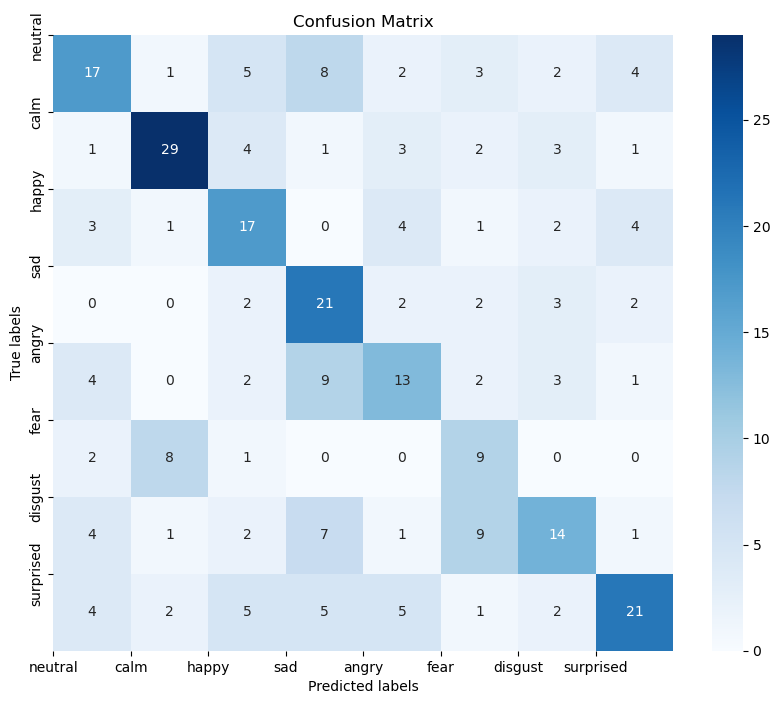

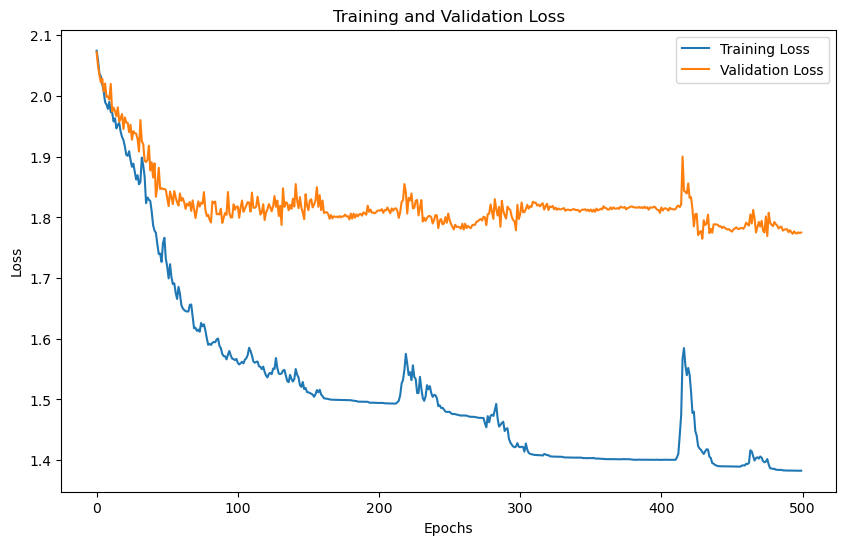

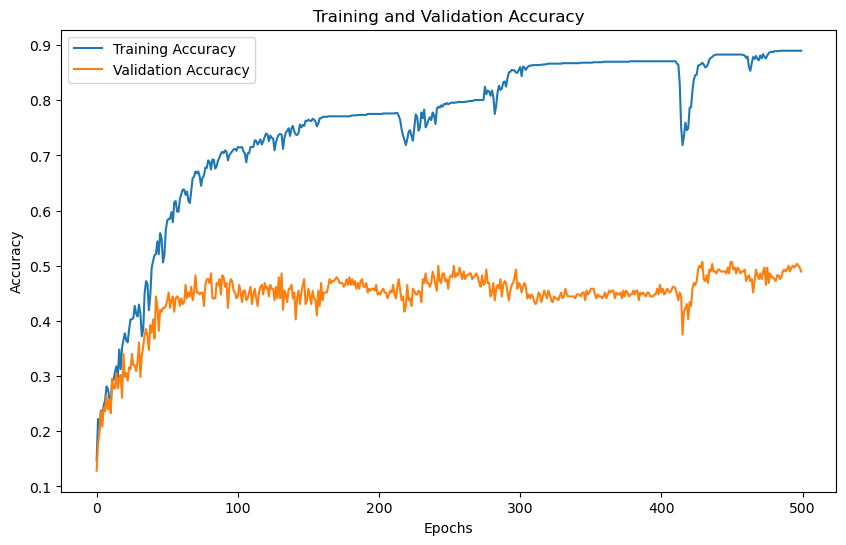

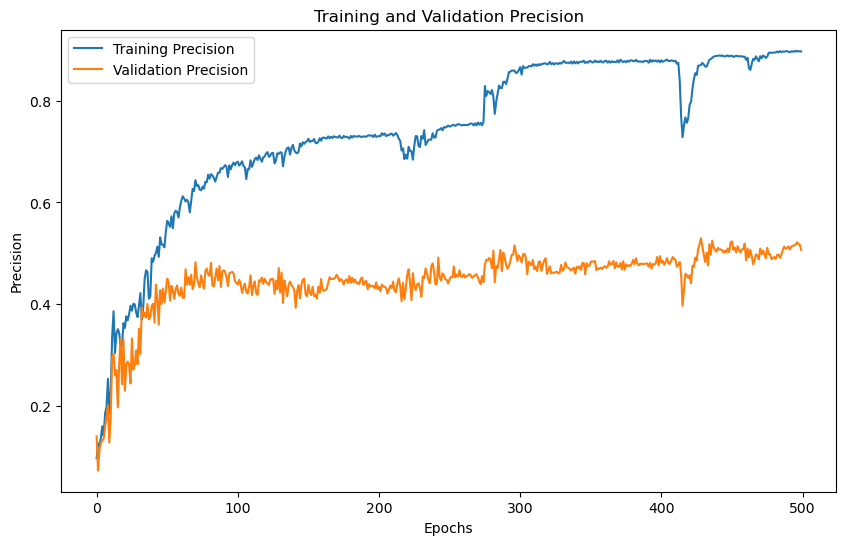

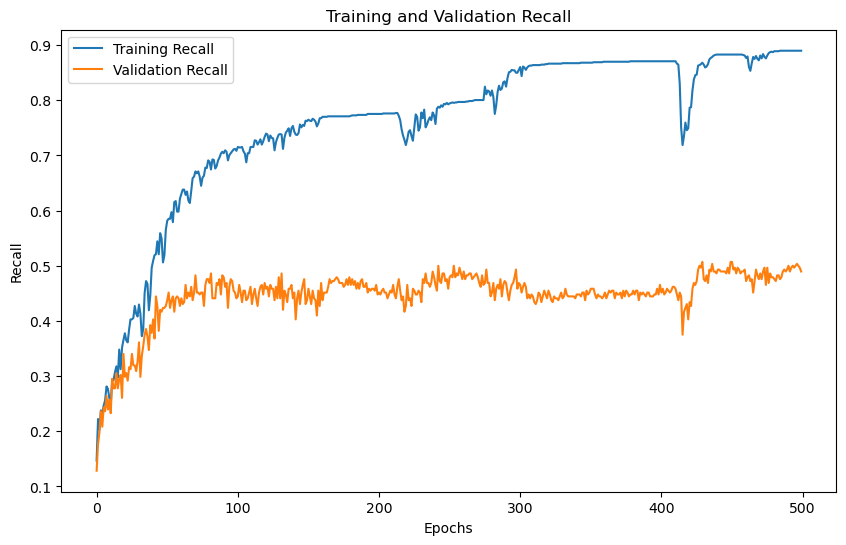

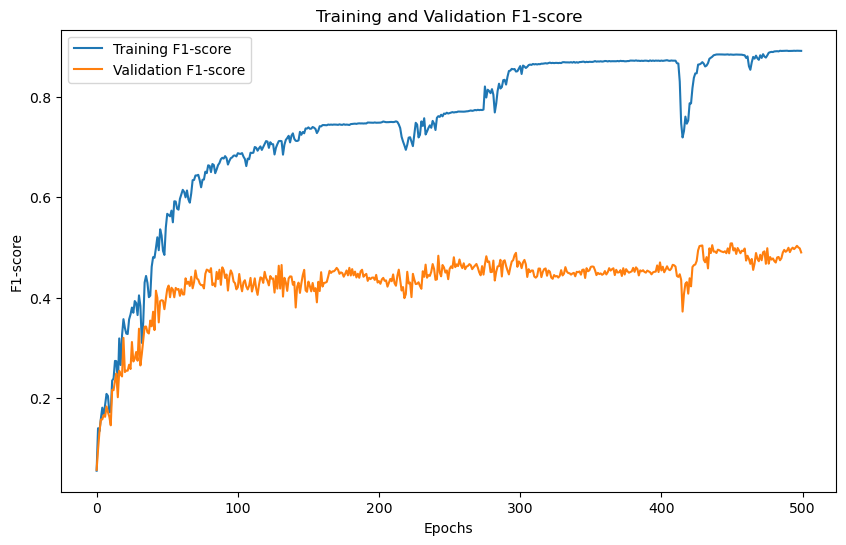

'Model Training and Evaluation Successfully completed'

In [22]:
train_model()

# N_MFCC 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  24
No. of classes 8
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 24, 1)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0698, Training Accuracy: 0.1753, Training Precision:0.0875,Training Recall:0.1753,Training F1-Score:0.0819
Validation Loss: 2.0731, Validation Accuracy: 0.1701, Validation Precision:0.0380,Validation Recall:0.1701,Validation F1-Score:0.0621
Epoch [2/500],
Training Loss: 2.0496, Training Accuracy: 0.2118, Training Precision:0.1132,Training Recall:0.2118,Training F1-Score:0.1295
Validation Loss: 2.0420, Validation Accuracy: 0.1736, Validation Precision:0.0838,Validation Recall:0.1736,Validation F1-Score:0.0948
Epoch [3/500],
Training Loss: 2.0284, Training Accuracy: 0.2309, Training Precision:0.1794,Training Recall:0.2309,Training F1-Score:0.1872
Validation Loss: 2.0056, Validation Accuracy: 0.2049, Validation Precisio

Epoch [31/500],
Training Loss: 1.9522, Training Accuracy: 0.3212, Training Precision:0.3348,Training Recall:0.3212,Training F1-Score:0.3032
Validation Loss: 2.0142, Validation Accuracy: 0.2326, Validation Precision:0.2380,Validation Recall:0.2326,Validation F1-Score:0.1972
Epoch [32/500],
Training Loss: 1.9382, Training Accuracy: 0.3637, Training Precision:0.3561,Training Recall:0.3637,Training F1-Score:0.3319
Validation Loss: 1.9724, Validation Accuracy: 0.2882, Validation Precision:0.2687,Validation Recall:0.2882,Validation F1-Score:0.2513
Epoch [33/500],
Training Loss: 1.9178, Training Accuracy: 0.3620, Training Precision:0.3455,Training Recall:0.3620,Training F1-Score:0.3379
Validation Loss: 1.9776, Validation Accuracy: 0.2674, Validation Precision:0.2646,Validation Recall:0.2674,Validation F1-Score:0.2574
Epoch [34/500],
Training Loss: 1.9128, Training Accuracy: 0.3880, Training Precision:0.3748,Training Recall:0.3880,Training F1-Score:0.3542
Validation Loss: 1.9738, Validation Ac

Epoch [61/500],
Training Loss: 1.7728, Training Accuracy: 0.5243, Training Precision:0.5000,Training Recall:0.5243,Training F1-Score:0.4988
Validation Loss: 1.9324, Validation Accuracy: 0.3264, Validation Precision:0.3001,Validation Recall:0.3264,Validation F1-Score:0.3000
Epoch [62/500],
Training Loss: 1.7557, Training Accuracy: 0.5417, Training Precision:0.5180,Training Recall:0.5417,Training F1-Score:0.5148
Validation Loss: 1.9534, Validation Accuracy: 0.3090, Validation Precision:0.2840,Validation Recall:0.3090,Validation F1-Score:0.2865
Epoch [63/500],
Training Loss: 1.7513, Training Accuracy: 0.5382, Training Precision:0.5100,Training Recall:0.5382,Training F1-Score:0.5127
Validation Loss: 1.9367, Validation Accuracy: 0.3264, Validation Precision:0.3119,Validation Recall:0.3264,Validation F1-Score:0.3092
Epoch [64/500],
Training Loss: 1.7550, Training Accuracy: 0.5104, Training Precision:0.4869,Training Recall:0.5104,Training F1-Score:0.4883
Validation Loss: 1.9545, Validation Ac

Epoch [91/500],
Training Loss: 1.6867, Training Accuracy: 0.6094, Training Precision:0.5766,Training Recall:0.6094,Training F1-Score:0.5840
Validation Loss: 1.9191, Validation Accuracy: 0.3542, Validation Precision:0.3402,Validation Recall:0.3542,Validation F1-Score:0.3345
Epoch [92/500],
Training Loss: 1.6693, Training Accuracy: 0.6085, Training Precision:0.5743,Training Recall:0.6085,Training F1-Score:0.5810
Validation Loss: 1.9176, Validation Accuracy: 0.3576, Validation Precision:0.3396,Validation Recall:0.3576,Validation F1-Score:0.3380
Epoch [93/500],
Training Loss: 1.6651, Training Accuracy: 0.6068, Training Precision:0.5796,Training Recall:0.6068,Training F1-Score:0.5806
Validation Loss: 1.9178, Validation Accuracy: 0.3472, Validation Precision:0.3236,Validation Recall:0.3472,Validation F1-Score:0.3213
Epoch [94/500],
Training Loss: 1.6635, Training Accuracy: 0.6224, Training Precision:0.5968,Training Recall:0.6224,Training F1-Score:0.5959
Validation Loss: 1.9125, Validation Ac

Epoch [121/500],
Training Loss: 1.6087, Training Accuracy: 0.6797, Training Precision:0.6477,Training Recall:0.6797,Training F1-Score:0.6552
Validation Loss: 1.9048, Validation Accuracy: 0.3611, Validation Precision:0.3496,Validation Recall:0.3611,Validation F1-Score:0.3421
Epoch [122/500],
Training Loss: 1.6040, Training Accuracy: 0.6710, Training Precision:0.6306,Training Recall:0.6710,Training F1-Score:0.6461
Validation Loss: 1.8977, Validation Accuracy: 0.3646, Validation Precision:0.3491,Validation Recall:0.3646,Validation F1-Score:0.3444
Epoch [123/500],
Training Loss: 1.6117, Training Accuracy: 0.6736, Training Precision:0.6399,Training Recall:0.6736,Training F1-Score:0.6480
Validation Loss: 1.9083, Validation Accuracy: 0.3576, Validation Precision:0.3539,Validation Recall:0.3576,Validation F1-Score:0.3389
Epoch [124/500],
Training Loss: 1.6030, Training Accuracy: 0.6753, Training Precision:0.6407,Training Recall:0.6753,Training F1-Score:0.6496
Validation Loss: 1.8982, Validatio

...

Epoch [361/500],
Training Loss: 1.4444, Training Accuracy: 0.8264, Training Precision:0.8336,Training Recall:0.8264,Training F1-Score:0.8242
Validation Loss: 1.8736, Validation Accuracy: 0.3889, Validation Precision:0.4094,Validation Recall:0.3889,Validation F1-Score:0.3849
Epoch [362/500],
Training Loss: 1.4443, Training Accuracy: 0.8264, Training Precision:0.8434,Training Recall:0.8264,Training F1-Score:0.8265
Validation Loss: 1.8759, Validation Accuracy: 0.3889, Validation Precision:0.4152,Validation Recall:0.3889,Validation F1-Score:0.3850
Epoch [363/500],
Training Loss: 1.4443, Training Accuracy: 0.8264, Training Precision:0.8322,Training Recall:0.8264,Training F1-Score:0.8239
Validation Loss: 1.8768, Validation Accuracy: 0.3889, Validation Precision:0.4100,Validation Recall:0.3889,Validation F1-Score:0.3853
Epoch [364/500],
Training Loss: 1.4442, Training Accuracy: 0.8264, Training Precision:0.8449,Training Recall:0.8264,Training F1-Score:0.8268
Validation Loss: 1.8727, Validatio

Epoch [391/500],
Training Loss: 1.4423, Training Accuracy: 0.8281, Training Precision:0.8428,Training Recall:0.8281,Training F1-Score:0.8276
Validation Loss: 1.8836, Validation Accuracy: 0.3889, Validation Precision:0.4133,Validation Recall:0.3889,Validation F1-Score:0.3819
Epoch [392/500],
Training Loss: 1.4422, Training Accuracy: 0.8281, Training Precision:0.8378,Training Recall:0.8281,Training F1-Score:0.8261
Validation Loss: 1.8850, Validation Accuracy: 0.3785, Validation Precision:0.4006,Validation Recall:0.3785,Validation F1-Score:0.3719
Epoch [393/500],
Training Loss: 1.4422, Training Accuracy: 0.8281, Training Precision:0.8466,Training Recall:0.8281,Training F1-Score:0.8282
Validation Loss: 1.8824, Validation Accuracy: 0.3854, Validation Precision:0.4123,Validation Recall:0.3854,Validation F1-Score:0.3797
Epoch [394/500],
Training Loss: 1.4421, Training Accuracy: 0.8281, Training Precision:0.8361,Training Recall:0.8281,Training F1-Score:0.8261
Validation Loss: 1.8812, Validatio

Epoch [421/500],
Training Loss: 1.4421, Training Accuracy: 0.8281, Training Precision:0.8386,Training Recall:0.8281,Training F1-Score:0.8266
Validation Loss: 1.8758, Validation Accuracy: 0.3924, Validation Precision:0.4169,Validation Recall:0.3924,Validation F1-Score:0.3878
Epoch [422/500],
Training Loss: 1.4422, Training Accuracy: 0.8281, Training Precision:0.8420,Training Recall:0.8281,Training F1-Score:0.8271
Validation Loss: 1.8776, Validation Accuracy: 0.3924, Validation Precision:0.4173,Validation Recall:0.3924,Validation F1-Score:0.3874
Epoch [423/500],
Training Loss: 1.4422, Training Accuracy: 0.8281, Training Precision:0.8365,Training Recall:0.8281,Training F1-Score:0.8260
Validation Loss: 1.8769, Validation Accuracy: 0.3924, Validation Precision:0.4141,Validation Recall:0.3924,Validation F1-Score:0.3861
Epoch [424/500],
Training Loss: 1.4422, Training Accuracy: 0.8281, Training Precision:0.8416,Training Recall:0.8281,Training F1-Score:0.8272
Validation Loss: 1.8791, Validatio

Epoch [451/500],
Training Loss: 1.5771, Training Accuracy: 0.7109, Training Precision:0.7338,Training Recall:0.7109,Training F1-Score:0.7084
Validation Loss: 1.8990, Validation Accuracy: 0.3715, Validation Precision:0.3813,Validation Recall:0.3715,Validation F1-Score:0.3493
Epoch [452/500],
Training Loss: 1.5440, Training Accuracy: 0.7578, Training Precision:0.7659,Training Recall:0.7578,Training F1-Score:0.7551
Validation Loss: 1.8778, Validation Accuracy: 0.3854, Validation Precision:0.3993,Validation Recall:0.3854,Validation F1-Score:0.3764
Epoch [453/500],
Training Loss: 1.5306, Training Accuracy: 0.7413, Training Precision:0.7498,Training Recall:0.7413,Training F1-Score:0.7381
Validation Loss: 1.8879, Validation Accuracy: 0.3785, Validation Precision:0.3874,Validation Recall:0.3785,Validation F1-Score:0.3760
Epoch [454/500],
Training Loss: 1.5203, Training Accuracy: 0.7569, Training Precision:0.7706,Training Recall:0.7569,Training F1-Score:0.7560
Validation Loss: 1.9057, Validatio

Epoch [481/500],
Training Loss: 1.4321, Training Accuracy: 0.8403, Training Precision:0.8523,Training Recall:0.8403,Training F1-Score:0.8390
Validation Loss: 1.8672, Validation Accuracy: 0.4097, Validation Precision:0.4085,Validation Recall:0.4097,Validation F1-Score:0.3971
Epoch [482/500],
Training Loss: 1.4317, Training Accuracy: 0.8403, Training Precision:0.8534,Training Recall:0.8403,Training F1-Score:0.8394
Validation Loss: 1.8667, Validation Accuracy: 0.4028, Validation Precision:0.4111,Validation Recall:0.4028,Validation F1-Score:0.3952
Epoch [483/500],
Training Loss: 1.4325, Training Accuracy: 0.8403, Training Precision:0.8531,Training Recall:0.8403,Training F1-Score:0.8394
Validation Loss: 1.8628, Validation Accuracy: 0.4097, Validation Precision:0.4186,Validation Recall:0.4097,Validation F1-Score:0.4030
Epoch [484/500],
Training Loss: 1.4310, Training Accuracy: 0.8420, Training Precision:0.8551,Training Recall:0.8420,Training F1-Score:0.8414
Validation Loss: 1.8795, Validatio

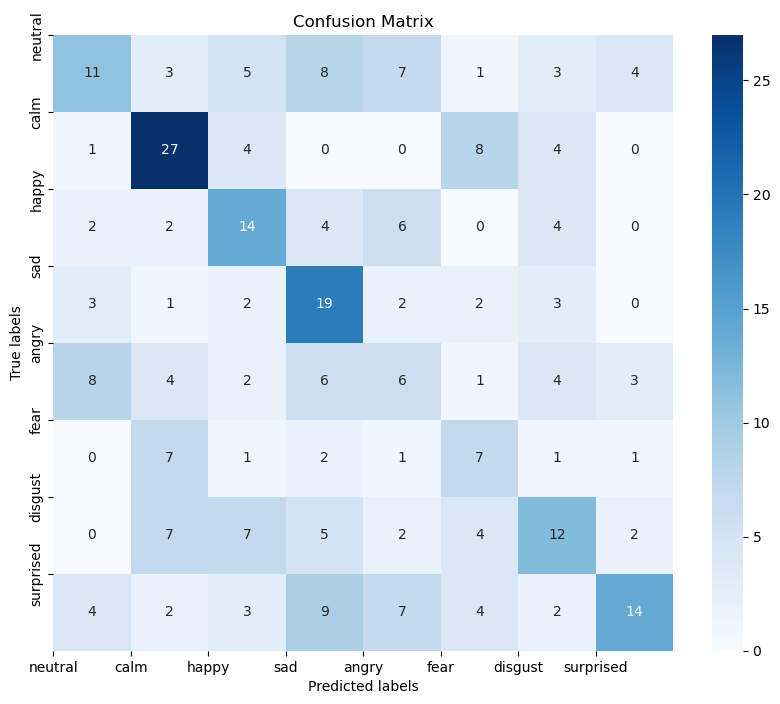

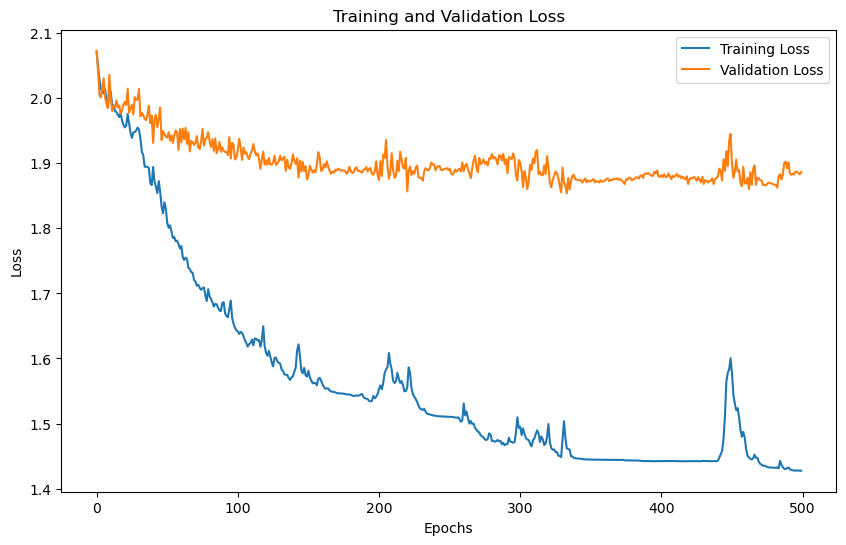

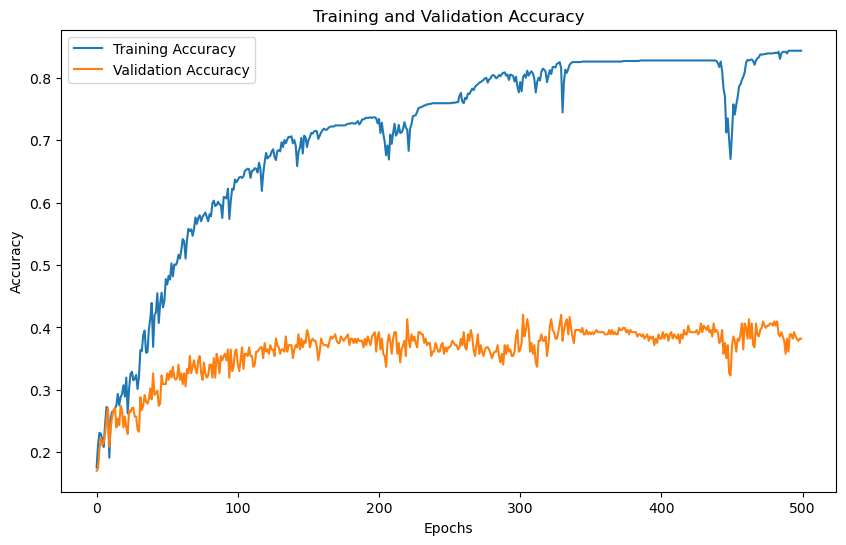

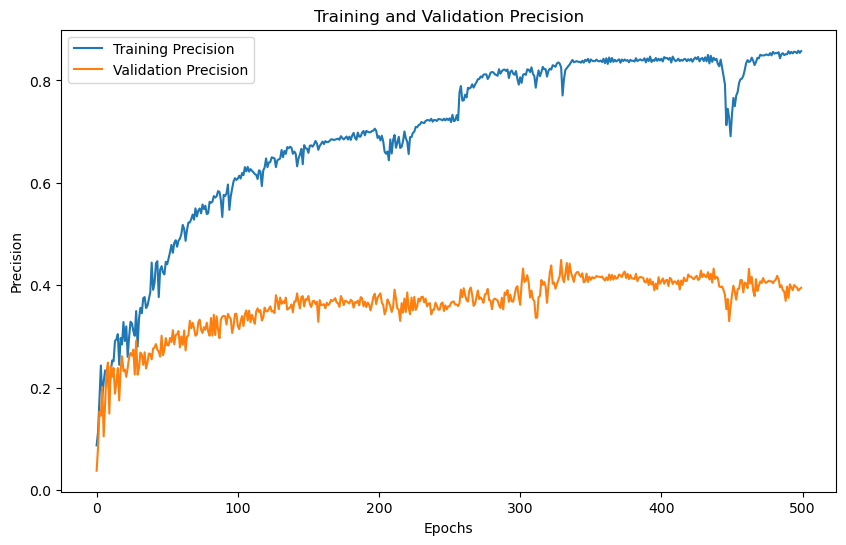

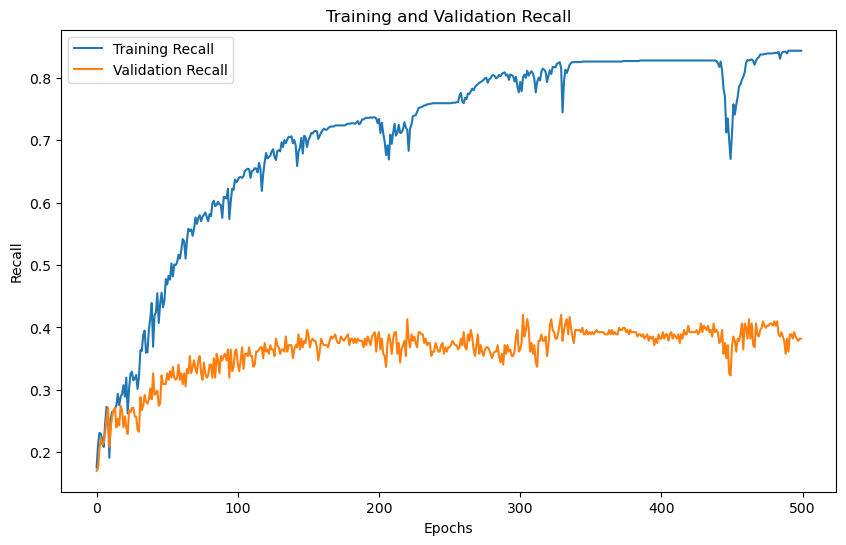

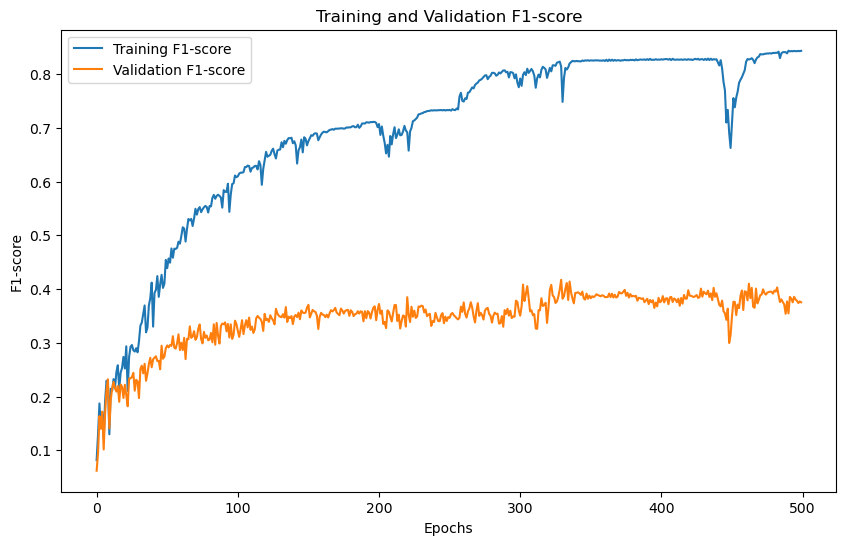

'Model Training and Evaluation Successfully completed'

In [23]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  32
No. of classes 8
Training with N_MFCC: 32
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 32, 1)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0746, Training Accuracy: 0.1719, Training Precision:0.0655,Training Recall:0.1719,Training F1-Score:0.0773
Validation Loss: 2.0642, Validation Accuracy: 0.1771, Validation Precision:0.0541,Validation Recall:0.1771,Validation F1-Score:0.0827
Epoch [2/500],
Training Loss: 2.0535, Training Accuracy: 0.1944, Training Precision:0.0813,Training Recall:0.1944,Training F1-Score:0.1127
Validation Loss: 2.0426, Validation Accuracy: 0.1736, Validation Precision:0.0722,Validation Recall:0.1736,Validation F1-Score:0.0952
Epoch [3/500],
Training Loss: 2.0334, Training Accuracy: 0.2413, Training Precision:0.1583,Training Recall:0.2413,Training F1-Score:0.1805
Validation Loss: 2.0156, Validation Accuracy: 0.2639, Validation Precisio

Epoch [31/500],
Training Loss: 1.9246, Training Accuracy: 0.3620, Training Precision:0.3597,Training Recall:0.3620,Training F1-Score:0.3206
Validation Loss: 1.9601, Validation Accuracy: 0.2951, Validation Precision:0.2742,Validation Recall:0.2951,Validation F1-Score:0.2595
Epoch [32/500],
Training Loss: 1.9223, Training Accuracy: 0.3594, Training Precision:0.3451,Training Recall:0.3594,Training F1-Score:0.3332
Validation Loss: 1.9561, Validation Accuracy: 0.3090, Validation Precision:0.3187,Validation Recall:0.3090,Validation F1-Score:0.2952
Epoch [33/500],
Training Loss: 1.9310, Training Accuracy: 0.3472, Training Precision:0.3206,Training Recall:0.3472,Training F1-Score:0.3214
Validation Loss: 1.9939, Validation Accuracy: 0.2604, Validation Precision:0.2371,Validation Recall:0.2604,Validation F1-Score:0.2378
Epoch [34/500],
Training Loss: 1.9251, Training Accuracy: 0.3568, Training Precision:0.3350,Training Recall:0.3568,Training F1-Score:0.3125
Validation Loss: 1.9609, Validation Ac

Epoch [61/500],
Training Loss: 1.8609, Training Accuracy: 0.4297, Training Precision:0.4078,Training Recall:0.4297,Training F1-Score:0.4044
Validation Loss: 1.9400, Validation Accuracy: 0.3194, Validation Precision:0.3008,Validation Recall:0.3194,Validation F1-Score:0.2942
Epoch [62/500],
Training Loss: 1.8539, Training Accuracy: 0.4297, Training Precision:0.4151,Training Recall:0.4297,Training F1-Score:0.3992
Validation Loss: 1.9489, Validation Accuracy: 0.3194, Validation Precision:0.3217,Validation Recall:0.3194,Validation F1-Score:0.2921
Epoch [63/500],
Training Loss: 1.8447, Training Accuracy: 0.4401, Training Precision:0.4205,Training Recall:0.4401,Training F1-Score:0.4100
Validation Loss: 1.9609, Validation Accuracy: 0.3125, Validation Precision:0.3180,Validation Recall:0.3125,Validation F1-Score:0.2808
Epoch [64/500],
Training Loss: 1.8381, Training Accuracy: 0.4436, Training Precision:0.4324,Training Recall:0.4436,Training F1-Score:0.4169
Validation Loss: 1.9612, Validation Ac

Epoch [91/500],
Training Loss: 1.7753, Training Accuracy: 0.5122, Training Precision:0.4866,Training Recall:0.5122,Training F1-Score:0.4819
Validation Loss: 1.9232, Validation Accuracy: 0.3507, Validation Precision:0.3435,Validation Recall:0.3507,Validation F1-Score:0.3248
Epoch [92/500],
Training Loss: 1.7654, Training Accuracy: 0.5139, Training Precision:0.4874,Training Recall:0.5139,Training F1-Score:0.4897
Validation Loss: 1.9283, Validation Accuracy: 0.3368, Validation Precision:0.3182,Validation Recall:0.3368,Validation F1-Score:0.3101
Epoch [93/500],
Training Loss: 1.7561, Training Accuracy: 0.5017, Training Precision:0.4784,Training Recall:0.5017,Training F1-Score:0.4794
Validation Loss: 1.9300, Validation Accuracy: 0.3333, Validation Precision:0.3149,Validation Recall:0.3333,Validation F1-Score:0.3115
Epoch [94/500],
Training Loss: 1.7793, Training Accuracy: 0.5009, Training Precision:0.4891,Training Recall:0.5009,Training F1-Score:0.4724
Validation Loss: 1.9318, Validation Ac

Epoch [121/500],
Training Loss: 1.6983, Training Accuracy: 0.5729, Training Precision:0.5468,Training Recall:0.5729,Training F1-Score:0.5493
Validation Loss: 1.9180, Validation Accuracy: 0.3438, Validation Precision:0.3282,Validation Recall:0.3438,Validation F1-Score:0.3231
Epoch [122/500],
Training Loss: 1.7016, Training Accuracy: 0.5859, Training Precision:0.5453,Training Recall:0.5859,Training F1-Score:0.5624
Validation Loss: 1.9053, Validation Accuracy: 0.3646, Validation Precision:0.3463,Validation Recall:0.3646,Validation F1-Score:0.3480
Epoch [123/500],
Training Loss: 1.6969, Training Accuracy: 0.5877, Training Precision:0.5540,Training Recall:0.5877,Training F1-Score:0.5643
Validation Loss: 1.9179, Validation Accuracy: 0.3438, Validation Precision:0.3195,Validation Recall:0.3438,Validation F1-Score:0.3221
Epoch [124/500],
Training Loss: 1.6966, Training Accuracy: 0.5894, Training Precision:0.5561,Training Recall:0.5894,Training F1-Score:0.5679
Validation Loss: 1.9198, Validatio

...

Epoch [361/500],
Training Loss: 1.5480, Training Accuracy: 0.7318, Training Precision:0.7312,Training Recall:0.7318,Training F1-Score:0.7292
Validation Loss: 1.9485, Validation Accuracy: 0.3160, Validation Precision:0.3213,Validation Recall:0.3160,Validation F1-Score:0.3116
Epoch [362/500],
Training Loss: 1.5434, Training Accuracy: 0.7405, Training Precision:0.7463,Training Recall:0.7405,Training F1-Score:0.7394
Validation Loss: 1.9295, Validation Accuracy: 0.3333, Validation Precision:0.3623,Validation Recall:0.3333,Validation F1-Score:0.3331
Epoch [363/500],
Training Loss: 1.5420, Training Accuracy: 0.7396, Training Precision:0.7453,Training Recall:0.7396,Training F1-Score:0.7380
Validation Loss: 1.9287, Validation Accuracy: 0.3403, Validation Precision:0.3612,Validation Recall:0.3403,Validation F1-Score:0.3363
Epoch [364/500],
Training Loss: 1.5437, Training Accuracy: 0.7292, Training Precision:0.7353,Training Recall:0.7292,Training F1-Score:0.7277
Validation Loss: 1.9377, Validatio

Epoch [391/500],
Training Loss: 1.5217, Training Accuracy: 0.7474, Training Precision:0.7571,Training Recall:0.7474,Training F1-Score:0.7465
Validation Loss: 1.9410, Validation Accuracy: 0.3264, Validation Precision:0.3451,Validation Recall:0.3264,Validation F1-Score:0.3236
Epoch [392/500],
Training Loss: 1.5215, Training Accuracy: 0.7474, Training Precision:0.7578,Training Recall:0.7474,Training F1-Score:0.7460
Validation Loss: 1.9392, Validation Accuracy: 0.3299, Validation Precision:0.3443,Validation Recall:0.3299,Validation F1-Score:0.3259
Epoch [393/500],
Training Loss: 1.5219, Training Accuracy: 0.7491, Training Precision:0.7521,Training Recall:0.7491,Training F1-Score:0.7470
Validation Loss: 1.9351, Validation Accuracy: 0.3333, Validation Precision:0.3486,Validation Recall:0.3333,Validation F1-Score:0.3315
Epoch [394/500],
Training Loss: 1.5251, Training Accuracy: 0.7465, Training Precision:0.7509,Training Recall:0.7465,Training F1-Score:0.7448
Validation Loss: 1.9422, Validatio

Epoch [421/500],
Training Loss: 1.5174, Training Accuracy: 0.7500, Training Precision:0.7583,Training Recall:0.7500,Training F1-Score:0.7490
Validation Loss: 1.9551, Validation Accuracy: 0.3056, Validation Precision:0.3154,Validation Recall:0.3056,Validation F1-Score:0.3028
Epoch [422/500],
Training Loss: 1.5171, Training Accuracy: 0.7509, Training Precision:0.7592,Training Recall:0.7509,Training F1-Score:0.7497
Validation Loss: 1.9466, Validation Accuracy: 0.3194, Validation Precision:0.3258,Validation Recall:0.3194,Validation F1-Score:0.3152
Epoch [423/500],
Training Loss: 1.5170, Training Accuracy: 0.7509, Training Precision:0.7658,Training Recall:0.7509,Training F1-Score:0.7512
Validation Loss: 1.9493, Validation Accuracy: 0.3194, Validation Precision:0.3332,Validation Recall:0.3194,Validation F1-Score:0.3175
Epoch [424/500],
Training Loss: 1.5166, Training Accuracy: 0.7517, Training Precision:0.7576,Training Recall:0.7517,Training F1-Score:0.7506
Validation Loss: 1.9549, Validatio

Epoch [451/500],
Training Loss: 1.5085, Training Accuracy: 0.7622, Training Precision:0.7819,Training Recall:0.7622,Training F1-Score:0.7634
Validation Loss: 1.9537, Validation Accuracy: 0.3160, Validation Precision:0.3212,Validation Recall:0.3160,Validation F1-Score:0.3095
Epoch [452/500],
Training Loss: 1.5062, Training Accuracy: 0.7639, Training Precision:0.7802,Training Recall:0.7639,Training F1-Score:0.7652
Validation Loss: 1.9383, Validation Accuracy: 0.3333, Validation Precision:0.3379,Validation Recall:0.3333,Validation F1-Score:0.3240
Epoch [453/500],
Training Loss: 1.5050, Training Accuracy: 0.7656, Training Precision:0.7809,Training Recall:0.7656,Training F1-Score:0.7664
Validation Loss: 1.9554, Validation Accuracy: 0.3021, Validation Precision:0.3062,Validation Recall:0.3021,Validation F1-Score:0.2913
Epoch [454/500],
Training Loss: 1.5029, Training Accuracy: 0.7700, Training Precision:0.7862,Training Recall:0.7700,Training F1-Score:0.7718
Validation Loss: 1.9529, Validatio

Epoch [481/500],
Training Loss: 1.4979, Training Accuracy: 0.7786, Training Precision:0.7863,Training Recall:0.7786,Training F1-Score:0.7770
Validation Loss: 1.9110, Validation Accuracy: 0.3576, Validation Precision:0.3769,Validation Recall:0.3576,Validation F1-Score:0.3514
Epoch [482/500],
Training Loss: 1.4958, Training Accuracy: 0.7847, Training Precision:0.7930,Training Recall:0.7847,Training F1-Score:0.7837
Validation Loss: 1.9403, Validation Accuracy: 0.3229, Validation Precision:0.3430,Validation Recall:0.3229,Validation F1-Score:0.3134
Epoch [483/500],
Training Loss: 1.4883, Training Accuracy: 0.7847, Training Precision:0.7916,Training Recall:0.7847,Training F1-Score:0.7838
Validation Loss: 1.9317, Validation Accuracy: 0.3333, Validation Precision:0.3543,Validation Recall:0.3333,Validation F1-Score:0.3269
Epoch [484/500],
Training Loss: 1.4866, Training Accuracy: 0.7856, Training Precision:0.7932,Training Recall:0.7856,Training F1-Score:0.7839
Validation Loss: 1.9232, Validatio

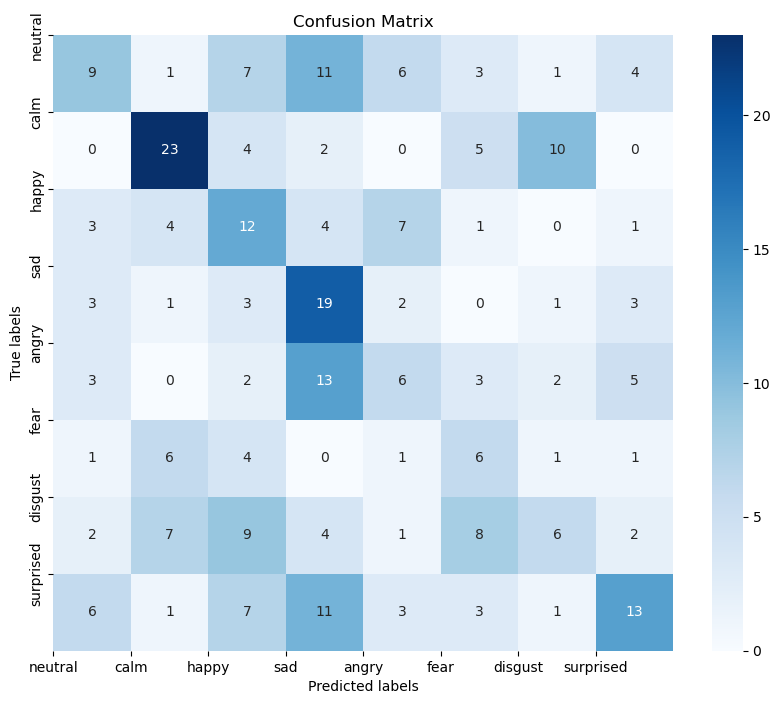

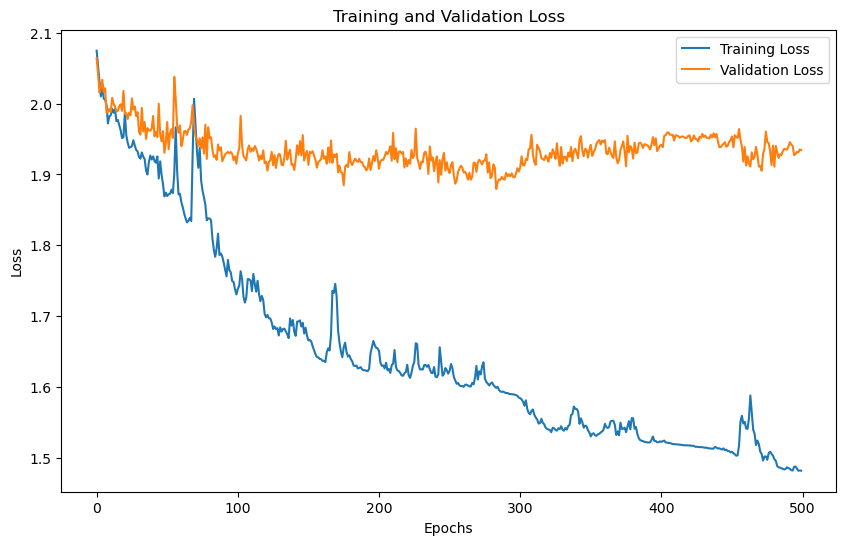

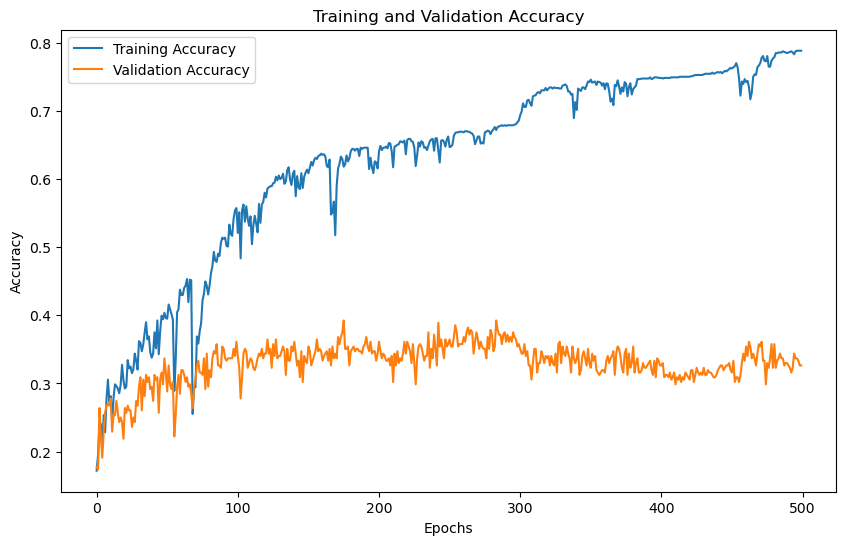

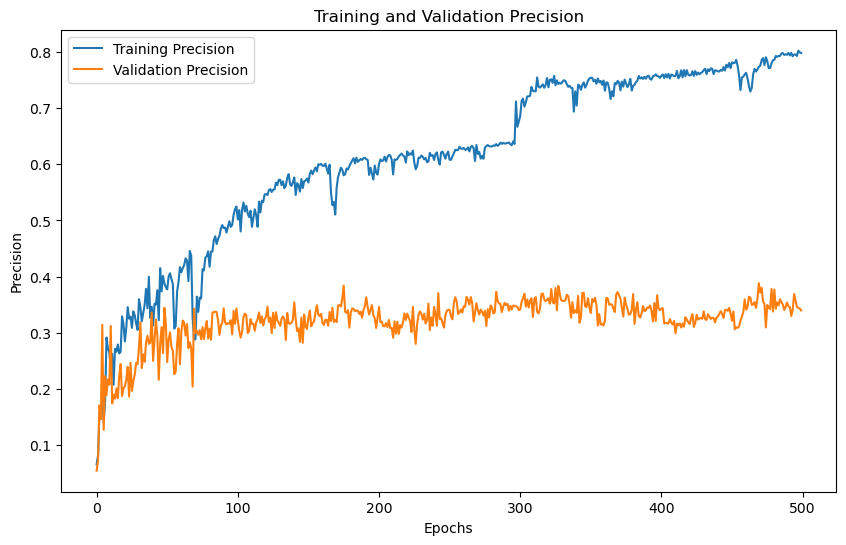

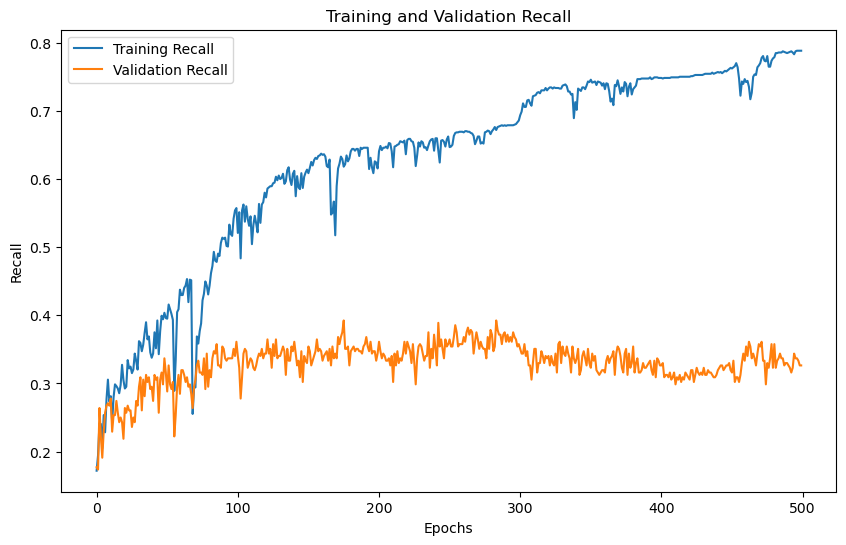

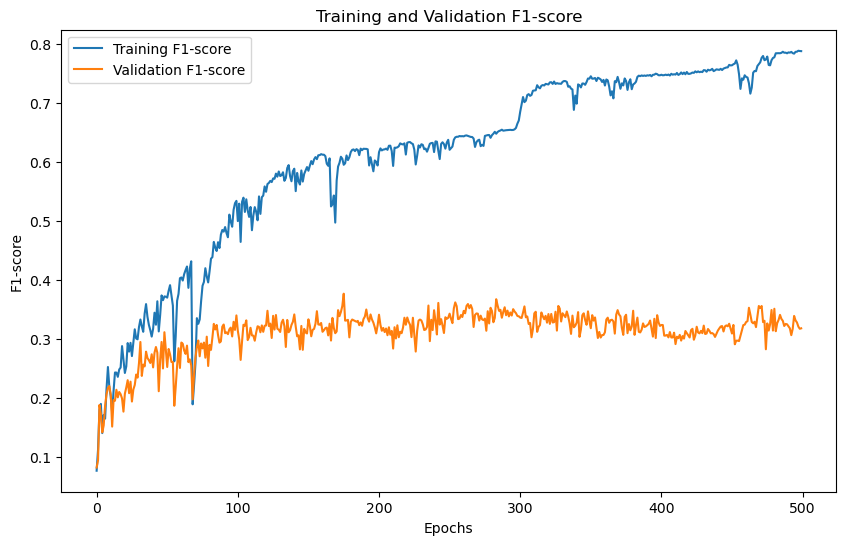

'Model Training and Evaluation Successfully completed'

In [24]:
train_model()

# N_MFCC 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 ravdess
Enter N_MFCC:  40
No. of classes 8
Training with N_MFCC: 40
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (1440, 40, 1)
Y Shape : (1440, 8)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 2.0740, Training Accuracy: 0.1615, Training Precision:0.0651,Training Recall:0.1615,Training F1-Score:0.0892
Validation Loss: 2.0643, Validation Accuracy: 0.1424, Validation Precision:0.0630,Validation Recall:0.1424,Validation F1-Score:0.0822
Epoch [2/500],
Training Loss: 2.0535, Training Accuracy: 0.2049, Training Precision:0.1153,Training Recall:0.2049,Training F1-Score:0.1288
Validation Loss: 2.0433, Validation Accuracy: 0.1736, Validation Precision:0.0868,Validation Recall:0.1736,Validation F1-Score:0.1032
Epoch [3/500],
Training Loss: 2.0303, Training Accuracy: 0.2196, Training Precision:0.1062,Training Recall:0.2196,Training F1-Score:0.1098
Validation Loss: 2.0097, Validation Accuracy: 0.2465, Validation Precisio

Epoch [31/500],
Training Loss: 1.9171, Training Accuracy: 0.3602, Training Precision:0.3396,Training Recall:0.3602,Training F1-Score:0.3146
Validation Loss: 1.9719, Validation Accuracy: 0.2917, Validation Precision:0.2248,Validation Recall:0.2917,Validation F1-Score:0.2329
Epoch [32/500],
Training Loss: 1.9112, Training Accuracy: 0.3646, Training Precision:0.3508,Training Recall:0.3646,Training F1-Score:0.3264
Validation Loss: 1.9685, Validation Accuracy: 0.2986, Validation Precision:0.2670,Validation Recall:0.2986,Validation F1-Score:0.2591
Epoch [33/500],
Training Loss: 1.9041, Training Accuracy: 0.3767, Training Precision:0.3617,Training Recall:0.3767,Training F1-Score:0.3323
Validation Loss: 1.9652, Validation Accuracy: 0.2986, Validation Precision:0.2635,Validation Recall:0.2986,Validation F1-Score:0.2468
Epoch [34/500],
Training Loss: 1.9147, Training Accuracy: 0.3316, Training Precision:0.3026,Training Recall:0.3316,Training F1-Score:0.3010
Validation Loss: 1.9803, Validation Ac

Epoch [61/500],
Training Loss: 1.8375, Training Accuracy: 0.4392, Training Precision:0.4063,Training Recall:0.4392,Training F1-Score:0.4056
Validation Loss: 1.9732, Validation Accuracy: 0.2812, Validation Precision:0.2353,Validation Recall:0.2812,Validation F1-Score:0.2398
Epoch [62/500],
Training Loss: 1.8671, Training Accuracy: 0.3429, Training Precision:0.3497,Training Recall:0.3429,Training F1-Score:0.3030
Validation Loss: 1.9713, Validation Accuracy: 0.2882, Validation Precision:0.2469,Validation Recall:0.2882,Validation F1-Score:0.2343
Epoch [63/500],
Training Loss: 1.9096, Training Accuracy: 0.4045, Training Precision:0.3873,Training Recall:0.4045,Training F1-Score:0.3630
Validation Loss: 1.9569, Validation Accuracy: 0.3056, Validation Precision:0.2569,Validation Recall:0.3056,Validation F1-Score:0.2651
Epoch [64/500],
Training Loss: 1.8444, Training Accuracy: 0.4523, Training Precision:0.4254,Training Recall:0.4523,Training F1-Score:0.4254
Validation Loss: 1.9772, Validation Ac

Epoch [91/500],
Training Loss: 1.7655, Training Accuracy: 0.5347, Training Precision:0.5002,Training Recall:0.5347,Training F1-Score:0.5143
Validation Loss: 1.9773, Validation Accuracy: 0.2778, Validation Precision:0.2598,Validation Recall:0.2778,Validation F1-Score:0.2632
Epoch [92/500],
Training Loss: 1.7611, Training Accuracy: 0.5278, Training Precision:0.4984,Training Recall:0.5278,Training F1-Score:0.5097
Validation Loss: 1.9691, Validation Accuracy: 0.2951, Validation Precision:0.2940,Validation Recall:0.2951,Validation F1-Score:0.2901
Epoch [93/500],
Training Loss: 1.7510, Training Accuracy: 0.5599, Training Precision:0.5287,Training Recall:0.5599,Training F1-Score:0.5354
Validation Loss: 1.9458, Validation Accuracy: 0.3194, Validation Precision:0.2845,Validation Recall:0.3194,Validation F1-Score:0.2977
Epoch [94/500],
Training Loss: 1.7386, Training Accuracy: 0.5495, Training Precision:0.5228,Training Recall:0.5495,Training F1-Score:0.5239
Validation Loss: 1.9443, Validation Ac

Epoch [121/500],
Training Loss: 1.6590, Training Accuracy: 0.6172, Training Precision:0.5793,Training Recall:0.6172,Training F1-Score:0.5942
Validation Loss: 1.9303, Validation Accuracy: 0.3542, Validation Precision:0.3283,Validation Recall:0.3542,Validation F1-Score:0.3384
Epoch [122/500],
Training Loss: 1.6589, Training Accuracy: 0.6094, Training Precision:0.5734,Training Recall:0.6094,Training F1-Score:0.5886
Validation Loss: 1.9653, Validation Accuracy: 0.3056, Validation Precision:0.2911,Validation Recall:0.3056,Validation F1-Score:0.2953
Epoch [123/500],
Training Loss: 1.6766, Training Accuracy: 0.5972, Training Precision:0.5604,Training Recall:0.5972,Training F1-Score:0.5731
Validation Loss: 1.9775, Validation Accuracy: 0.2951, Validation Precision:0.2606,Validation Recall:0.2951,Validation F1-Score:0.2722
Epoch [124/500],
Training Loss: 1.6796, Training Accuracy: 0.6155, Training Precision:0.5792,Training Recall:0.6155,Training F1-Score:0.5922
Validation Loss: 1.9671, Validatio

...

Epoch [361/500],
Training Loss: 1.5309, Training Accuracy: 0.7387, Training Precision:0.6900,Training Recall:0.7387,Training F1-Score:0.7131
Validation Loss: 1.9352, Validation Accuracy: 0.3299, Validation Precision:0.3079,Validation Recall:0.3299,Validation F1-Score:0.3152
Epoch [362/500],
Training Loss: 1.5307, Training Accuracy: 0.7387, Training Precision:0.6918,Training Recall:0.7387,Training F1-Score:0.7133
Validation Loss: 1.9304, Validation Accuracy: 0.3403, Validation Precision:0.3166,Validation Recall:0.3403,Validation F1-Score:0.3246
Epoch [363/500],
Training Loss: 1.5304, Training Accuracy: 0.7387, Training Precision:0.6921,Training Recall:0.7387,Training F1-Score:0.7138
Validation Loss: 1.9360, Validation Accuracy: 0.3264, Validation Precision:0.3084,Validation Recall:0.3264,Validation F1-Score:0.3133
Epoch [364/500],
Training Loss: 1.5305, Training Accuracy: 0.7387, Training Precision:0.6923,Training Recall:0.7387,Training F1-Score:0.7133
Validation Loss: 1.9332, Validatio

Epoch [391/500],
Training Loss: 1.5269, Training Accuracy: 0.7405, Training Precision:0.6923,Training Recall:0.7405,Training F1-Score:0.7150
Validation Loss: 1.9352, Validation Accuracy: 0.3264, Validation Precision:0.2986,Validation Recall:0.3264,Validation F1-Score:0.3080
Epoch [392/500],
Training Loss: 1.5270, Training Accuracy: 0.7405, Training Precision:0.6945,Training Recall:0.7405,Training F1-Score:0.7149
Validation Loss: 1.9323, Validation Accuracy: 0.3333, Validation Precision:0.3055,Validation Recall:0.3333,Validation F1-Score:0.3153
Epoch [393/500],
Training Loss: 1.5270, Training Accuracy: 0.7405, Training Precision:0.6976,Training Recall:0.7405,Training F1-Score:0.7164
Validation Loss: 1.9355, Validation Accuracy: 0.3264, Validation Precision:0.3030,Validation Recall:0.3264,Validation F1-Score:0.3104
Epoch [394/500],
Training Loss: 1.5267, Training Accuracy: 0.7413, Training Precision:0.6945,Training Recall:0.7413,Training F1-Score:0.7164
Validation Loss: 1.9366, Validatio

Epoch [421/500],
Training Loss: 1.5353, Training Accuracy: 0.7569, Training Precision:0.7576,Training Recall:0.7569,Training F1-Score:0.7538
Validation Loss: 1.9350, Validation Accuracy: 0.3368, Validation Precision:0.3384,Validation Recall:0.3368,Validation F1-Score:0.3324
Epoch [422/500],
Training Loss: 1.5308, Training Accuracy: 0.7569, Training Precision:0.7576,Training Recall:0.7569,Training F1-Score:0.7552
Validation Loss: 1.9203, Validation Accuracy: 0.3542, Validation Precision:0.3633,Validation Recall:0.3542,Validation F1-Score:0.3485
Epoch [423/500],
Training Loss: 1.5349, Training Accuracy: 0.7604, Training Precision:0.7628,Training Recall:0.7604,Training F1-Score:0.7584
Validation Loss: 1.9253, Validation Accuracy: 0.3472, Validation Precision:0.3686,Validation Recall:0.3472,Validation F1-Score:0.3422
Epoch [424/500],
Training Loss: 1.5432, Training Accuracy: 0.7561, Training Precision:0.7596,Training Recall:0.7561,Training F1-Score:0.7538
Validation Loss: 1.9305, Validatio

Epoch [451/500],
Training Loss: 1.4802, Training Accuracy: 0.7917, Training Precision:0.7918,Training Recall:0.7917,Training F1-Score:0.7904
Validation Loss: 1.9092, Validation Accuracy: 0.3576, Validation Precision:0.3678,Validation Recall:0.3576,Validation F1-Score:0.3583
Epoch [452/500],
Training Loss: 1.4786, Training Accuracy: 0.7925, Training Precision:0.7927,Training Recall:0.7925,Training F1-Score:0.7917
Validation Loss: 1.9094, Validation Accuracy: 0.3611, Validation Precision:0.3746,Validation Recall:0.3611,Validation F1-Score:0.3637
Epoch [453/500],
Training Loss: 1.4782, Training Accuracy: 0.7925, Training Precision:0.7935,Training Recall:0.7925,Training F1-Score:0.7918
Validation Loss: 1.9090, Validation Accuracy: 0.3611, Validation Precision:0.3742,Validation Recall:0.3611,Validation F1-Score:0.3634
Epoch [454/500],
Training Loss: 1.4777, Training Accuracy: 0.7925, Training Precision:0.7928,Training Recall:0.7925,Training F1-Score:0.7921
Validation Loss: 1.9145, Validatio

Epoch [481/500],
Training Loss: 1.4837, Training Accuracy: 0.7951, Training Precision:0.7981,Training Recall:0.7951,Training F1-Score:0.7956
Validation Loss: 1.9443, Validation Accuracy: 0.3229, Validation Precision:0.3664,Validation Recall:0.3229,Validation F1-Score:0.3325
Epoch [482/500],
Training Loss: 1.4799, Training Accuracy: 0.7969, Training Precision:0.7983,Training Recall:0.7969,Training F1-Score:0.7969
Validation Loss: 1.9295, Validation Accuracy: 0.3403, Validation Precision:0.3504,Validation Recall:0.3403,Validation F1-Score:0.3413
Epoch [483/500],
Training Loss: 1.4808, Training Accuracy: 0.7995, Training Precision:0.8001,Training Recall:0.7995,Training F1-Score:0.7987
Validation Loss: 1.9593, Validation Accuracy: 0.3021, Validation Precision:0.3102,Validation Recall:0.3021,Validation F1-Score:0.2990
Epoch [484/500],
Training Loss: 1.4939, Training Accuracy: 0.7882, Training Precision:0.7911,Training Recall:0.7882,Training F1-Score:0.7876
Validation Loss: 1.9420, Validatio

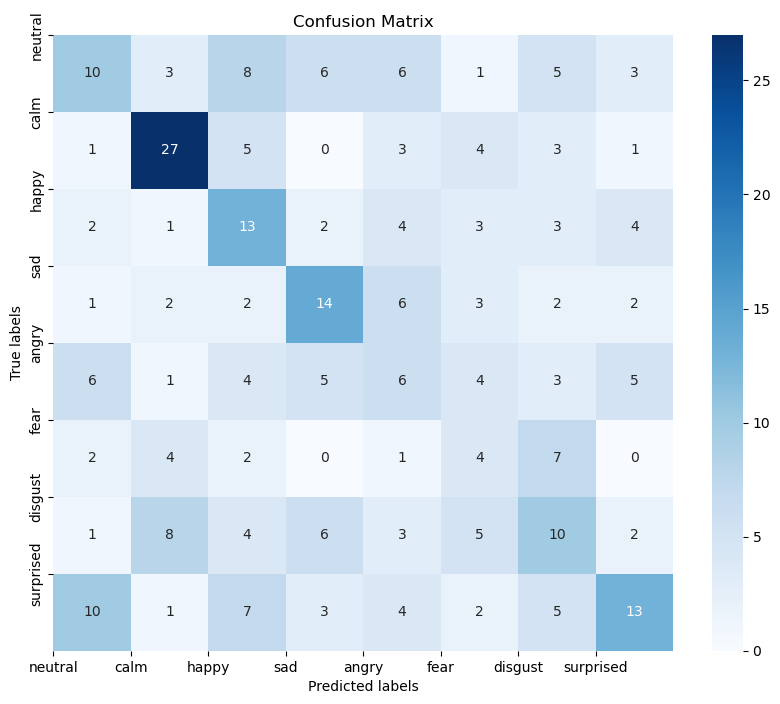

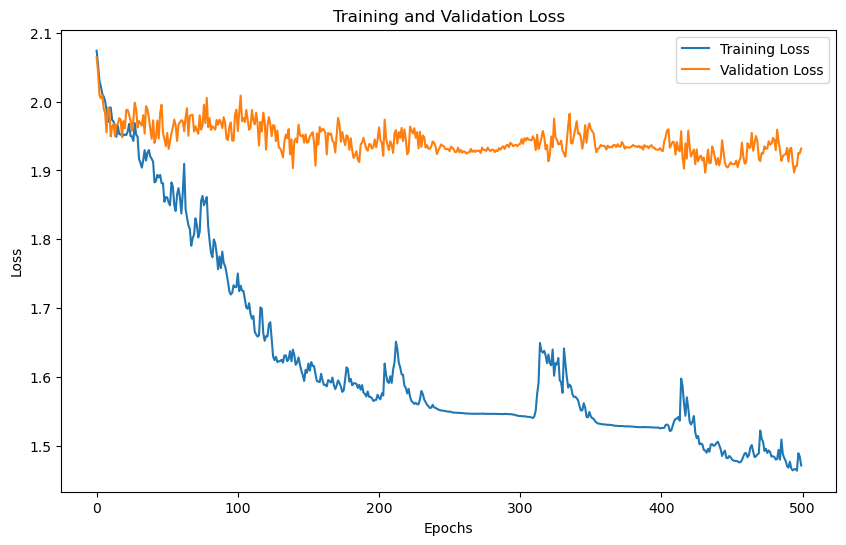

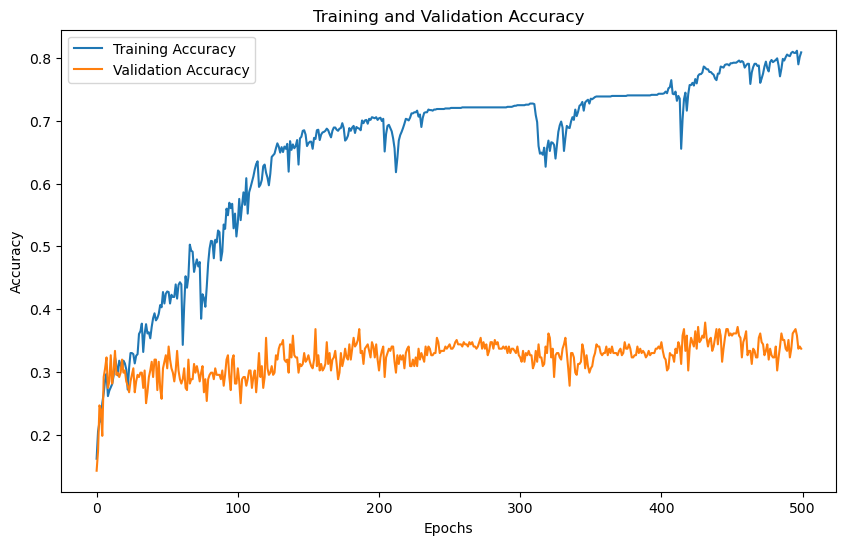

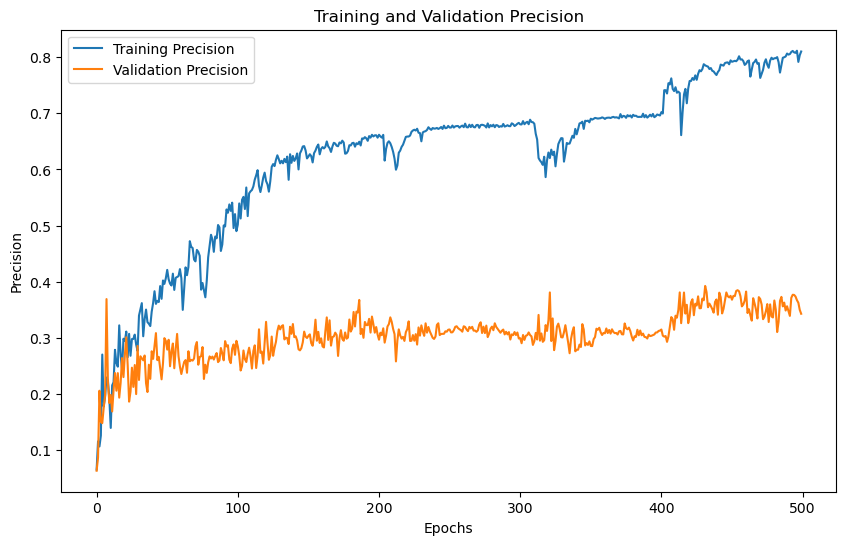

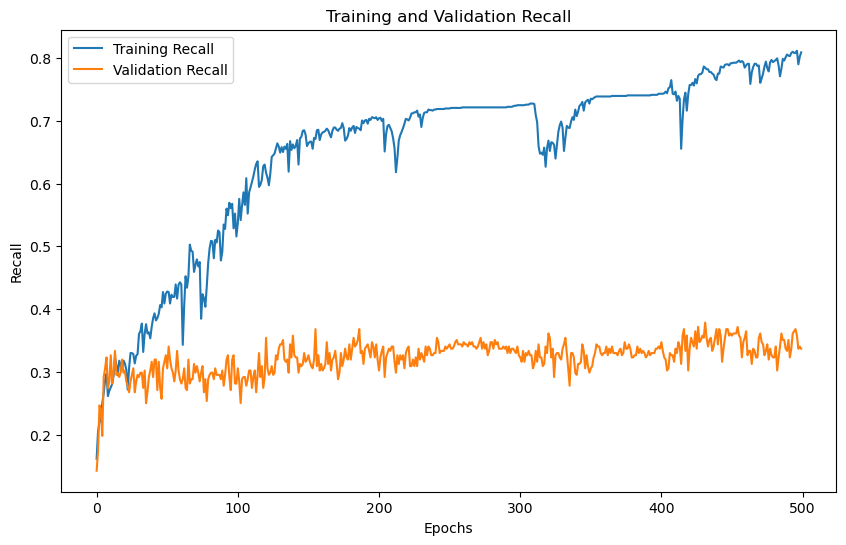

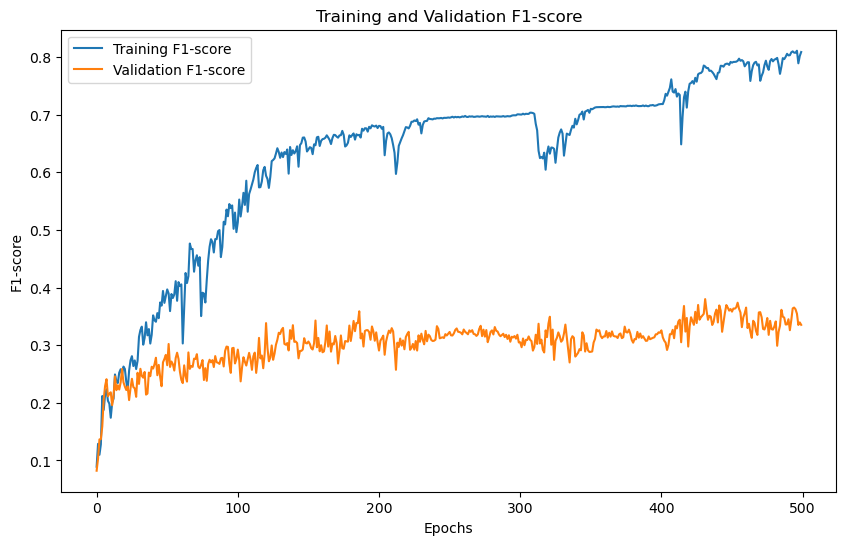

'Model Training and Evaluation Successfully completed'

In [25]:
train_model()

# CREMA

# N_MFCC 16

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  16
No. of classes 6
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 16, 1)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7420, Training Accuracy: 0.2896, Training Precision:0.2311,Training Recall:0.2896,Training F1-Score:0.2088
Validation Loss: 1.7214, Validation Accuracy: 0.2915, Validation Precision:0.2366,Validation Recall:0.2915,Validation F1-Score:0.2092
Epoch [2/500],
Training Loss: 1.6958, Training Accuracy: 0.3166, Training Precision:0.1975,Training Recall:0.3166,Training F1-Score:0.2270
Validation Loss: 1.6916, Validation Accuracy: 0.3298, Validation Precision:0.2137,Validation Recall:0.3298,Validation F1-Score:0.2414
Epoch [3/500],
Training Loss: 1.6825, Training Accuracy: 0.3477, Training Precision:0.3014,Training Recall:0.3477,Training F1-Score:0.2908
Validation Loss: 1.6678, Validation Accuracy: 0.3472, Validation Precision:

Epoch [31/500],
Training Loss: 1.5975, Training Accuracy: 0.4504, Training Precision:0.4505,Training Recall:0.4504,Training F1-Score:0.4246
Validation Loss: 1.5889, Validation Accuracy: 0.4426, Validation Precision:0.4365,Validation Recall:0.4426,Validation F1-Score:0.4170
Epoch [32/500],
Training Loss: 1.5886, Training Accuracy: 0.4507, Training Precision:0.4569,Training Recall:0.4507,Training F1-Score:0.4238
Validation Loss: 1.5906, Validation Accuracy: 0.4466, Validation Precision:0.4379,Validation Recall:0.4466,Validation F1-Score:0.4226
Epoch [33/500],
Training Loss: 1.5859, Training Accuracy: 0.4446, Training Precision:0.4439,Training Recall:0.4446,Training F1-Score:0.4230
Validation Loss: 1.5930, Validation Accuracy: 0.4412, Validation Precision:0.4343,Validation Recall:0.4412,Validation F1-Score:0.4168
Epoch [34/500],
Training Loss: 1.5835, Training Accuracy: 0.4762, Training Precision:0.4666,Training Recall:0.4762,Training F1-Score:0.4534
Validation Loss: 1.5828, Validation Ac

Epoch [61/500],
Training Loss: 1.5255, Training Accuracy: 0.5320, Training Precision:0.5271,Training Recall:0.5320,Training F1-Score:0.5270
Validation Loss: 1.5902, Validation Accuracy: 0.4453, Validation Precision:0.4378,Validation Recall:0.4453,Validation F1-Score:0.4384
Epoch [62/500],
Training Loss: 1.5188, Training Accuracy: 0.5244, Training Precision:0.5359,Training Recall:0.5244,Training F1-Score:0.5091
Validation Loss: 1.5864, Validation Accuracy: 0.4473, Validation Precision:0.4372,Validation Recall:0.4473,Validation F1-Score:0.4296
Epoch [63/500],
Training Loss: 1.5332, Training Accuracy: 0.4833, Training Precision:0.5097,Training Recall:0.4833,Training F1-Score:0.4687
Validation Loss: 1.6084, Validation Accuracy: 0.4285, Validation Precision:0.4423,Validation Recall:0.4285,Validation F1-Score:0.4120
Epoch [64/500],
Training Loss: 1.5243, Training Accuracy: 0.5130, Training Precision:0.5173,Training Recall:0.5130,Training F1-Score:0.5020
Validation Loss: 1.6027, Validation Ac

Epoch [91/500],
Training Loss: 1.4100, Training Accuracy: 0.6304, Training Precision:0.6323,Training Recall:0.6304,Training F1-Score:0.6251
Validation Loss: 1.6056, Validation Accuracy: 0.4271, Validation Precision:0.4214,Validation Recall:0.4271,Validation F1-Score:0.4208
Epoch [92/500],
Training Loss: 1.4230, Training Accuracy: 0.6434, Training Precision:0.6489,Training Recall:0.6434,Training F1-Score:0.6372
Validation Loss: 1.5943, Validation Accuracy: 0.4392, Validation Precision:0.4258,Validation Recall:0.4392,Validation F1-Score:0.4278
Epoch [93/500],
Training Loss: 1.4192, Training Accuracy: 0.6454, Training Precision:0.6500,Training Recall:0.6454,Training F1-Score:0.6397
Validation Loss: 1.5851, Validation Accuracy: 0.4500, Validation Precision:0.4407,Validation Recall:0.4500,Validation F1-Score:0.4400
Epoch [94/500],
Training Loss: 1.4035, Training Accuracy: 0.6481, Training Precision:0.6536,Training Recall:0.6481,Training F1-Score:0.6414
Validation Loss: 1.5960, Validation Ac

Epoch [121/500],
Training Loss: 1.3584, Training Accuracy: 0.6960, Training Precision:0.6980,Training Recall:0.6960,Training F1-Score:0.6921
Validation Loss: 1.6016, Validation Accuracy: 0.4352, Validation Precision:0.4284,Validation Recall:0.4352,Validation F1-Score:0.4298
Epoch [122/500],
Training Loss: 1.3527, Training Accuracy: 0.6951, Training Precision:0.6958,Training Recall:0.6951,Training F1-Score:0.6904
Validation Loss: 1.6040, Validation Accuracy: 0.4332, Validation Precision:0.4262,Validation Recall:0.4332,Validation F1-Score:0.4274
Epoch [123/500],
Training Loss: 1.3529, Training Accuracy: 0.6867, Training Precision:0.6873,Training Recall:0.6867,Training F1-Score:0.6835
Validation Loss: 1.6099, Validation Accuracy: 0.4291, Validation Precision:0.4190,Validation Recall:0.4291,Validation F1-Score:0.4198
Epoch [124/500],
Training Loss: 1.3723, Training Accuracy: 0.6797, Training Precision:0.6861,Training Recall:0.6797,Training F1-Score:0.6766
Validation Loss: 1.6083, Validatio

...

Epoch [361/500],
Training Loss: 1.2462, Training Accuracy: 0.7907, Training Precision:0.7953,Training Recall:0.7907,Training F1-Score:0.7894
Validation Loss: 1.6386, Validation Accuracy: 0.4009, Validation Precision:0.3889,Validation Recall:0.4009,Validation F1-Score:0.3900
Epoch [362/500],
Training Loss: 1.2388, Training Accuracy: 0.8088, Training Precision:0.8151,Training Recall:0.8088,Training F1-Score:0.8077
Validation Loss: 1.6373, Validation Accuracy: 0.4016, Validation Precision:0.3890,Validation Recall:0.4016,Validation F1-Score:0.3894
Epoch [363/500],
Training Loss: 1.2444, Training Accuracy: 0.7999, Training Precision:0.8045,Training Recall:0.7999,Training F1-Score:0.7989
Validation Loss: 1.6326, Validation Accuracy: 0.4063, Validation Precision:0.3963,Validation Recall:0.4063,Validation F1-Score:0.3969
Epoch [364/500],
Training Loss: 1.2473, Training Accuracy: 0.8063, Training Precision:0.8073,Training Recall:0.8063,Training F1-Score:0.8051
Validation Loss: 1.6230, Validatio

Epoch [391/500],
Training Loss: 1.2256, Training Accuracy: 0.8100, Training Precision:0.8124,Training Recall:0.8100,Training F1-Score:0.8089
Validation Loss: 1.6376, Validation Accuracy: 0.4009, Validation Precision:0.3978,Validation Recall:0.4009,Validation F1-Score:0.3981
Epoch [392/500],
Training Loss: 1.2420, Training Accuracy: 0.8152, Training Precision:0.8181,Training Recall:0.8152,Training F1-Score:0.8141
Validation Loss: 1.6304, Validation Accuracy: 0.4097, Validation Precision:0.4021,Validation Recall:0.4097,Validation F1-Score:0.4045
Epoch [393/500],
Training Loss: 1.2366, Training Accuracy: 0.8023, Training Precision:0.8030,Training Recall:0.8023,Training F1-Score:0.8009
Validation Loss: 1.6372, Validation Accuracy: 0.4016, Validation Precision:0.3967,Validation Recall:0.4016,Validation F1-Score:0.3986
Epoch [394/500],
Training Loss: 1.2366, Training Accuracy: 0.8068, Training Precision:0.8107,Training Recall:0.8068,Training F1-Score:0.8061
Validation Loss: 1.6402, Validatio

Epoch [421/500],
Training Loss: 1.2562, Training Accuracy: 0.7917, Training Precision:0.7961,Training Recall:0.7917,Training F1-Score:0.7909
Validation Loss: 1.6306, Validation Accuracy: 0.4083, Validation Precision:0.4019,Validation Recall:0.4083,Validation F1-Score:0.4009
Epoch [422/500],
Training Loss: 1.2418, Training Accuracy: 0.8125, Training Precision:0.8142,Training Recall:0.8125,Training F1-Score:0.8117
Validation Loss: 1.6343, Validation Accuracy: 0.4043, Validation Precision:0.3977,Validation Recall:0.4043,Validation F1-Score:0.3998
Epoch [423/500],
Training Loss: 1.2346, Training Accuracy: 0.8109, Training Precision:0.8153,Training Recall:0.8109,Training F1-Score:0.8100
Validation Loss: 1.6313, Validation Accuracy: 0.4077, Validation Precision:0.4007,Validation Recall:0.4077,Validation F1-Score:0.4002
Epoch [424/500],
Training Loss: 1.2331, Training Accuracy: 0.8109, Training Precision:0.8164,Training Recall:0.8109,Training F1-Score:0.8103
Validation Loss: 1.6383, Validatio

Epoch [451/500],
Training Loss: 1.2237, Training Accuracy: 0.8194, Training Precision:0.8224,Training Recall:0.8194,Training F1-Score:0.8185
Validation Loss: 1.6311, Validation Accuracy: 0.4110, Validation Precision:0.4042,Validation Recall:0.4110,Validation F1-Score:0.4044
Epoch [452/500],
Training Loss: 1.2212, Training Accuracy: 0.8233, Training Precision:0.8247,Training Recall:0.8233,Training F1-Score:0.8222
Validation Loss: 1.6444, Validation Accuracy: 0.3929, Validation Precision:0.3843,Validation Recall:0.3929,Validation F1-Score:0.3862
Epoch [453/500],
Training Loss: 1.2178, Training Accuracy: 0.8305, Training Precision:0.8328,Training Recall:0.8305,Training F1-Score:0.8297
Validation Loss: 1.6327, Validation Accuracy: 0.4070, Validation Precision:0.4001,Validation Recall:0.4070,Validation F1-Score:0.4015
Epoch [454/500],
Training Loss: 1.2214, Training Accuracy: 0.8186, Training Precision:0.8222,Training Recall:0.8186,Training F1-Score:0.8179
Validation Loss: 1.6427, Validatio

Epoch [481/500],
Training Loss: 1.2316, Training Accuracy: 0.8137, Training Precision:0.8181,Training Recall:0.8137,Training F1-Score:0.8131
Validation Loss: 1.6521, Validation Accuracy: 0.3848, Validation Precision:0.3847,Validation Recall:0.3848,Validation F1-Score:0.3800
Epoch [482/500],
Training Loss: 1.2233, Training Accuracy: 0.8251, Training Precision:0.8286,Training Recall:0.8251,Training F1-Score:0.8243
Validation Loss: 1.6249, Validation Accuracy: 0.4150, Validation Precision:0.4056,Validation Recall:0.4150,Validation F1-Score:0.4061
Epoch [483/500],
Training Loss: 1.2195, Training Accuracy: 0.8221, Training Precision:0.8237,Training Recall:0.8221,Training F1-Score:0.8213
Validation Loss: 1.6426, Validation Accuracy: 0.3962, Validation Precision:0.3890,Validation Recall:0.3962,Validation F1-Score:0.3903
Epoch [484/500],
Training Loss: 1.2184, Training Accuracy: 0.8235, Training Precision:0.8267,Training Recall:0.8235,Training F1-Score:0.8226
Validation Loss: 1.6483, Validatio

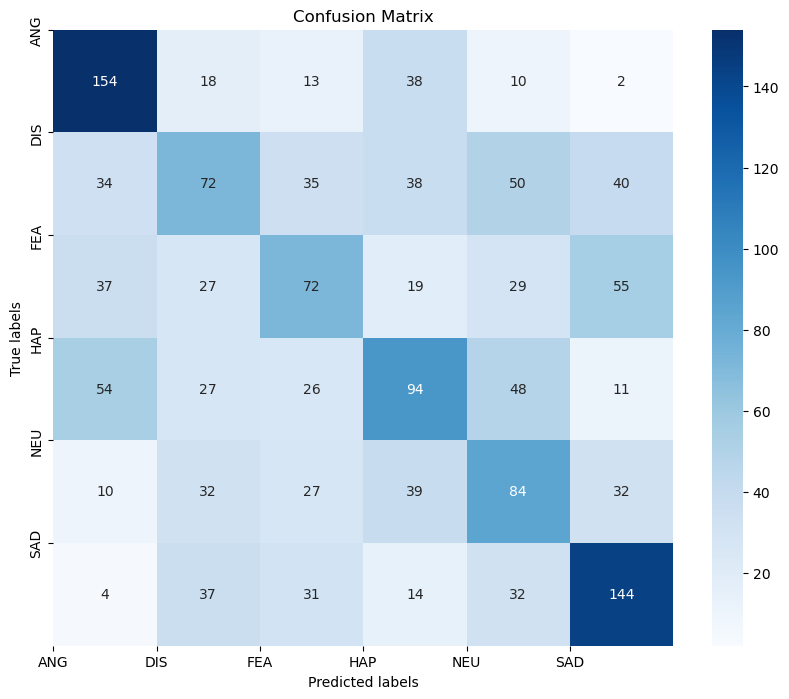

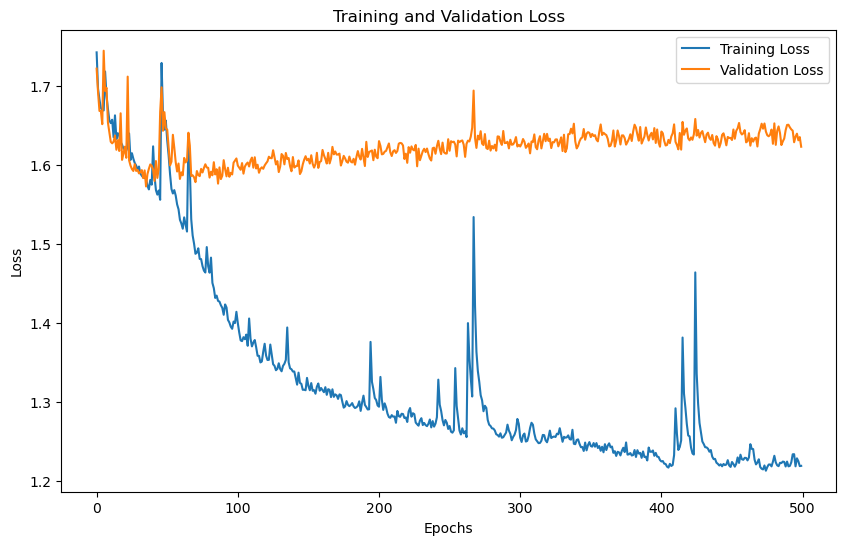

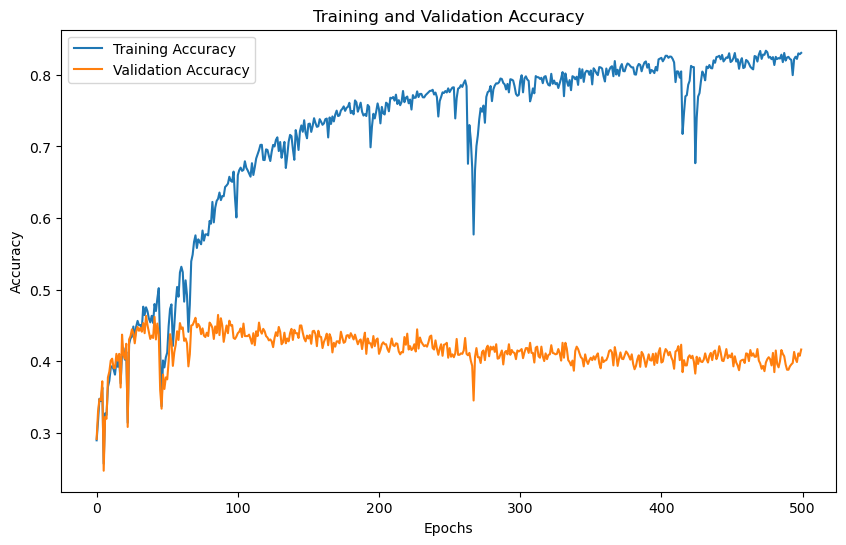

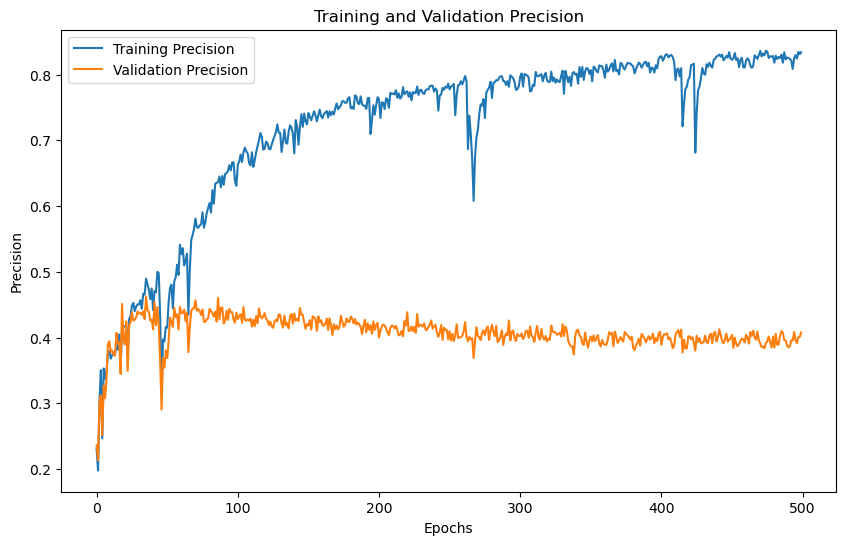

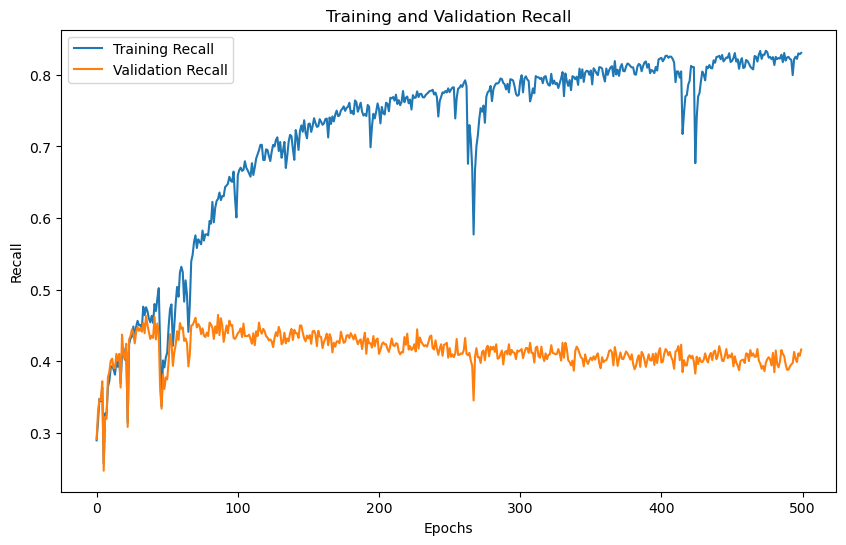

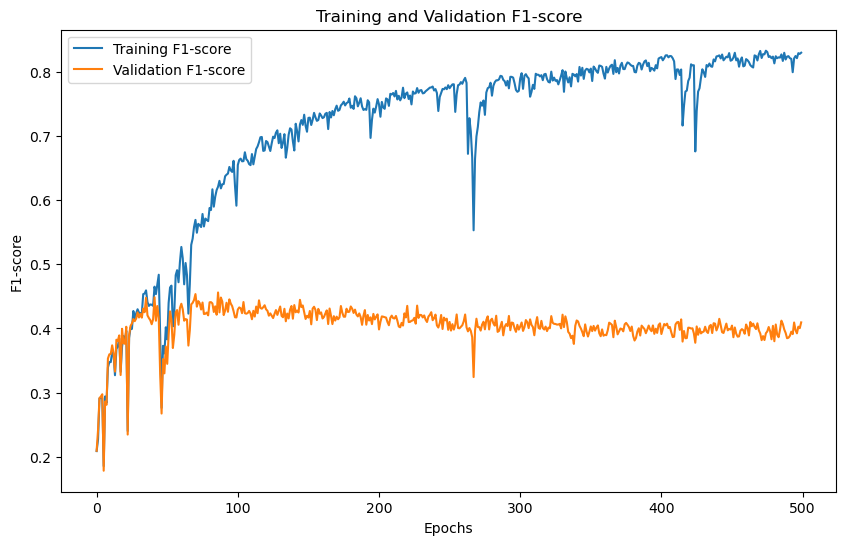

'Model Training and Evaluation Successfully completed'

In [26]:
train_model()

# N_MFCC 24

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  24
No. of classes 6
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 24, 1)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7589, Training Accuracy: 0.2884, Training Precision:0.2033,Training Recall:0.2884,Training F1-Score:0.1762
Validation Loss: 1.7147, Validation Accuracy: 0.2928, Validation Precision:0.2268,Validation Recall:0.2928,Validation F1-Score:0.1838
Epoch [2/500],
Training Loss: 1.7040, Training Accuracy: 0.2254, Training Precision:0.2711,Training Recall:0.2254,Training F1-Score:0.1458
Validation Loss: 1.7965, Validation Accuracy: 0.2001, Validation Precision:0.2302,Validation Recall:0.2001,Validation F1-Score:0.1193
Epoch [3/500],
Training Loss: 1.8195, Training Accuracy: 0.1860, Training Precision:0.0894,Training Recall:0.1860,Training F1-Score:0.0946
Validation Loss: 1.8122, Validation Accuracy: 0.1968, Validation Precision:

Epoch [31/500],
Training Loss: 1.7388, Training Accuracy: 0.3501, Training Precision:0.4140,Training Recall:0.3501,Training F1-Score:0.2820
Validation Loss: 1.6675, Validation Accuracy: 0.3566, Validation Precision:0.2577,Validation Recall:0.3566,Validation F1-Score:0.2844
Epoch [32/500],
Training Loss: 1.6944, Training Accuracy: 0.3627, Training Precision:0.2571,Training Recall:0.3627,Training F1-Score:0.2840
Validation Loss: 1.6650, Validation Accuracy: 0.3600, Validation Precision:0.2587,Validation Recall:0.3600,Validation F1-Score:0.2848
Epoch [33/500],
Training Loss: 1.6957, Training Accuracy: 0.2518, Training Precision:0.2565,Training Recall:0.2518,Training F1-Score:0.1852
Validation Loss: 1.7553, Validation Accuracy: 0.2391, Validation Precision:0.1953,Validation Recall:0.2391,Validation F1-Score:0.1688
Epoch [34/500],
Training Loss: 1.7436, Training Accuracy: 0.3069, Training Precision:0.3409,Training Recall:0.3069,Training F1-Score:0.2522
Validation Loss: 1.7147, Validation Ac

Epoch [61/500],
Training Loss: 1.6510, Training Accuracy: 0.3817, Training Precision:0.3608,Training Recall:0.3817,Training F1-Score:0.3304
Validation Loss: 1.6501, Validation Accuracy: 0.3761, Validation Precision:0.3556,Validation Recall:0.3761,Validation F1-Score:0.3234
Epoch [62/500],
Training Loss: 1.6460, Training Accuracy: 0.3833, Training Precision:0.3656,Training Recall:0.3833,Training F1-Score:0.3614
Validation Loss: 1.6423, Validation Accuracy: 0.3781, Validation Precision:0.3558,Validation Recall:0.3781,Validation F1-Score:0.3508
Epoch [63/500],
Training Loss: 1.6387, Training Accuracy: 0.3956, Training Precision:0.3729,Training Recall:0.3956,Training F1-Score:0.3649
Validation Loss: 1.6373, Validation Accuracy: 0.3821, Validation Precision:0.3596,Validation Recall:0.3821,Validation F1-Score:0.3499
Epoch [64/500],
Training Loss: 1.6363, Training Accuracy: 0.3872, Training Precision:0.3845,Training Recall:0.3872,Training F1-Score:0.3821
Validation Loss: 1.6431, Validation Ac

Epoch [91/500],
Training Loss: 1.5924, Training Accuracy: 0.4562, Training Precision:0.4473,Training Recall:0.4562,Training F1-Score:0.4487
Validation Loss: 1.6031, Validation Accuracy: 0.4325, Validation Precision:0.4177,Validation Recall:0.4325,Validation F1-Score:0.4211
Epoch [92/500],
Training Loss: 1.5993, Training Accuracy: 0.4453, Training Precision:0.4411,Training Recall:0.4453,Training F1-Score:0.4239
Validation Loss: 1.6093, Validation Accuracy: 0.4171, Validation Precision:0.4060,Validation Recall:0.4171,Validation F1-Score:0.3911
Epoch [93/500],
Training Loss: 1.5857, Training Accuracy: 0.4441, Training Precision:0.4499,Training Recall:0.4441,Training F1-Score:0.4254
Validation Loss: 1.6116, Validation Accuracy: 0.4244, Validation Precision:0.4157,Validation Recall:0.4244,Validation F1-Score:0.3994
Epoch [94/500],
Training Loss: 1.5846, Training Accuracy: 0.4062, Training Precision:0.4308,Training Recall:0.4062,Training F1-Score:0.3917
Validation Loss: 1.6329, Validation Ac

Epoch [121/500],
Training Loss: 1.5531, Training Accuracy: 0.4969, Training Precision:0.5047,Training Recall:0.4969,Training F1-Score:0.4850
Validation Loss: 1.5900, Validation Accuracy: 0.4433, Validation Precision:0.4402,Validation Recall:0.4433,Validation F1-Score:0.4305
Epoch [122/500],
Training Loss: 1.5487, Training Accuracy: 0.5003, Training Precision:0.4999,Training Recall:0.5003,Training F1-Score:0.4871
Validation Loss: 1.6012, Validation Accuracy: 0.4271, Validation Precision:0.4167,Validation Recall:0.4271,Validation F1-Score:0.4124
Epoch [123/500],
Training Loss: 1.5459, Training Accuracy: 0.5092, Training Precision:0.5125,Training Recall:0.5092,Training F1-Score:0.4940
Validation Loss: 1.5931, Validation Accuracy: 0.4399, Validation Precision:0.4284,Validation Recall:0.4399,Validation F1-Score:0.4208
Epoch [124/500],
Training Loss: 1.5419, Training Accuracy: 0.5149, Training Precision:0.5116,Training Recall:0.5149,Training F1-Score:0.5031
Validation Loss: 1.5926, Validatio

...

Epoch [361/500],
Training Loss: 1.2712, Training Accuracy: 0.7759, Training Precision:0.7787,Training Recall:0.7759,Training F1-Score:0.7742
Validation Loss: 1.6199, Validation Accuracy: 0.4224, Validation Precision:0.4166,Validation Recall:0.4224,Validation F1-Score:0.4172
Epoch [362/500],
Training Loss: 1.2740, Training Accuracy: 0.7606, Training Precision:0.7631,Training Recall:0.7606,Training F1-Score:0.7594
Validation Loss: 1.6238, Validation Accuracy: 0.4124, Validation Precision:0.4098,Validation Recall:0.4124,Validation F1-Score:0.4098
Epoch [363/500],
Training Loss: 1.2840, Training Accuracy: 0.7561, Training Precision:0.7595,Training Recall:0.7561,Training F1-Score:0.7533
Validation Loss: 1.6239, Validation Accuracy: 0.4144, Validation Precision:0.4109,Validation Recall:0.4144,Validation F1-Score:0.4103
Epoch [364/500],
Training Loss: 1.2905, Training Accuracy: 0.7636, Training Precision:0.7635,Training Recall:0.7636,Training F1-Score:0.7620
Validation Loss: 1.6269, Validatio

Epoch [391/500],
Training Loss: 1.2801, Training Accuracy: 0.7472, Training Precision:0.7491,Training Recall:0.7472,Training F1-Score:0.7459
Validation Loss: 1.6245, Validation Accuracy: 0.4164, Validation Precision:0.4191,Validation Recall:0.4164,Validation F1-Score:0.4163
Epoch [392/500],
Training Loss: 1.4439, Training Accuracy: 0.6309, Training Precision:0.6569,Training Recall:0.6309,Training F1-Score:0.6307
Validation Loss: 1.6234, Validation Accuracy: 0.4171, Validation Precision:0.4183,Validation Recall:0.4171,Validation F1-Score:0.4085
Epoch [393/500],
Training Loss: 1.3793, Training Accuracy: 0.6901, Training Precision:0.6989,Training Recall:0.6901,Training F1-Score:0.6878
Validation Loss: 1.6138, Validation Accuracy: 0.4238, Validation Precision:0.4198,Validation Recall:0.4238,Validation F1-Score:0.4160
Epoch [394/500],
Training Loss: 1.3346, Training Accuracy: 0.7222, Training Precision:0.7225,Training Recall:0.7222,Training F1-Score:0.7211
Validation Loss: 1.6211, Validatio

Epoch [421/500],
Training Loss: 1.2636, Training Accuracy: 0.7867, Training Precision:0.7890,Training Recall:0.7867,Training F1-Score:0.7854
Validation Loss: 1.6246, Validation Accuracy: 0.4137, Validation Precision:0.4108,Validation Recall:0.4137,Validation F1-Score:0.4099
Epoch [422/500],
Training Loss: 1.2619, Training Accuracy: 0.7870, Training Precision:0.7890,Training Recall:0.7870,Training F1-Score:0.7856
Validation Loss: 1.6341, Validation Accuracy: 0.4036, Validation Precision:0.3975,Validation Recall:0.4036,Validation F1-Score:0.3989
Epoch [423/500],
Training Loss: 1.2584, Training Accuracy: 0.7625, Training Precision:0.7640,Training Recall:0.7625,Training F1-Score:0.7614
Validation Loss: 1.6410, Validation Accuracy: 0.3949, Validation Precision:0.3956,Validation Recall:0.3949,Validation F1-Score:0.3916
Epoch [424/500],
Training Loss: 1.2786, Training Accuracy: 0.7762, Training Precision:0.7774,Training Recall:0.7762,Training F1-Score:0.7750
Validation Loss: 1.6166, Validatio

Epoch [451/500],
Training Loss: 1.2547, Training Accuracy: 0.7712, Training Precision:0.7775,Training Recall:0.7712,Training F1-Score:0.7700
Validation Loss: 1.6304, Validation Accuracy: 0.4063, Validation Precision:0.4107,Validation Recall:0.4063,Validation F1-Score:0.4037
Epoch [452/500],
Training Loss: 1.2603, Training Accuracy: 0.7895, Training Precision:0.7900,Training Recall:0.7895,Training F1-Score:0.7884
Validation Loss: 1.6184, Validation Accuracy: 0.4191, Validation Precision:0.4163,Validation Recall:0.4191,Validation F1-Score:0.4173
Epoch [453/500],
Training Loss: 1.2505, Training Accuracy: 0.7910, Training Precision:0.7923,Training Recall:0.7910,Training F1-Score:0.7895
Validation Loss: 1.6174, Validation Accuracy: 0.4231, Validation Precision:0.4164,Validation Recall:0.4231,Validation F1-Score:0.4178
Epoch [454/500],
Training Loss: 1.2847, Training Accuracy: 0.7734, Training Precision:0.7734,Training Recall:0.7734,Training F1-Score:0.7717
Validation Loss: 1.6198, Validatio

Epoch [481/500],
Training Loss: 1.2814, Training Accuracy: 0.7779, Training Precision:0.7795,Training Recall:0.7779,Training F1-Score:0.7767
Validation Loss: 1.6278, Validation Accuracy: 0.4110, Validation Precision:0.4118,Validation Recall:0.4110,Validation F1-Score:0.4103
Epoch [482/500],
Training Loss: 1.2684, Training Accuracy: 0.7838, Training Precision:0.7862,Training Recall:0.7838,Training F1-Score:0.7820
Validation Loss: 1.6277, Validation Accuracy: 0.4117, Validation Precision:0.4062,Validation Recall:0.4117,Validation F1-Score:0.4082
Epoch [483/500],
Training Loss: 1.2643, Training Accuracy: 0.7892, Training Precision:0.7906,Training Recall:0.7892,Training F1-Score:0.7878
Validation Loss: 1.6267, Validation Accuracy: 0.4110, Validation Precision:0.4073,Validation Recall:0.4110,Validation F1-Score:0.4077
Epoch [484/500],
Training Loss: 1.2735, Training Accuracy: 0.7872, Training Precision:0.7898,Training Recall:0.7872,Training F1-Score:0.7856
Validation Loss: 1.6230, Validatio

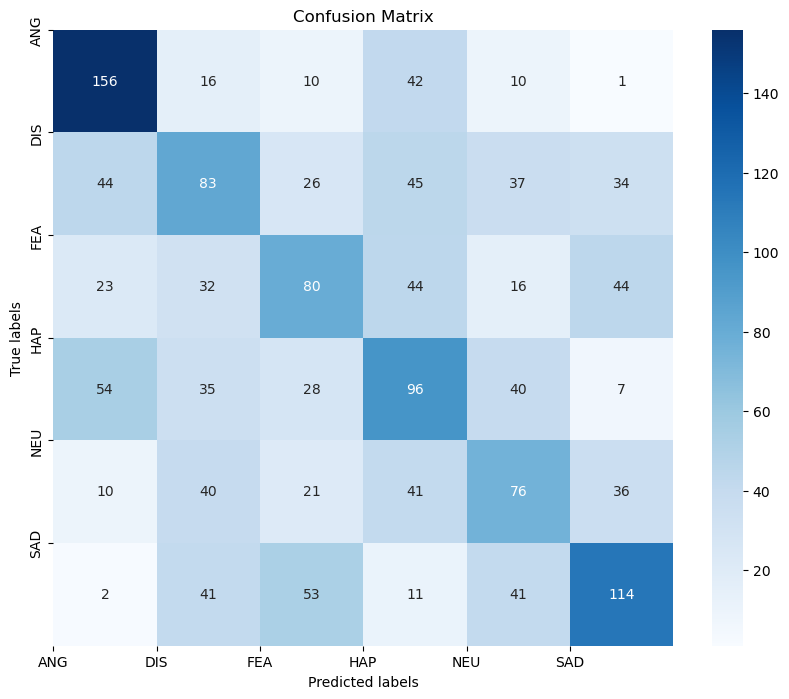

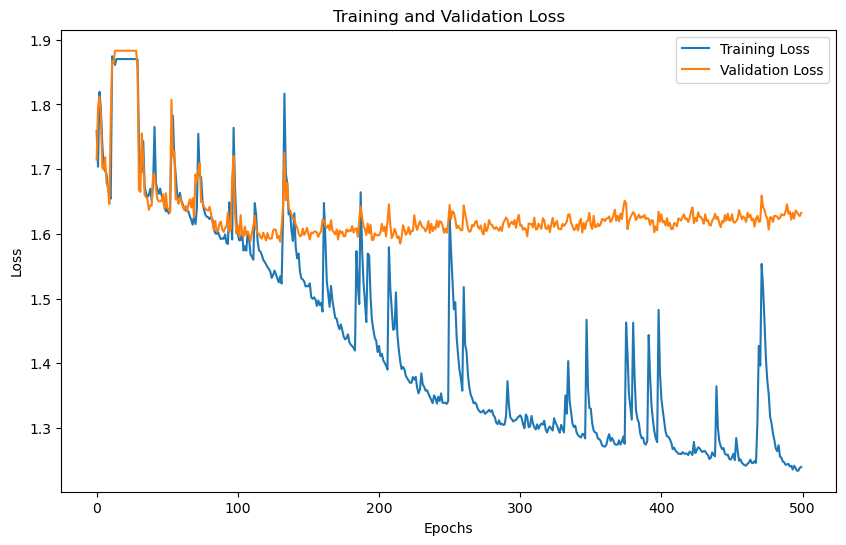

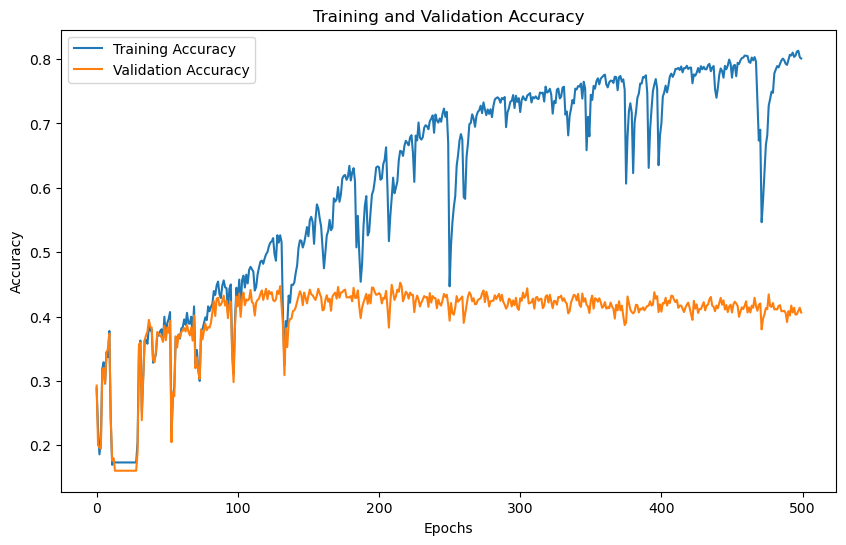

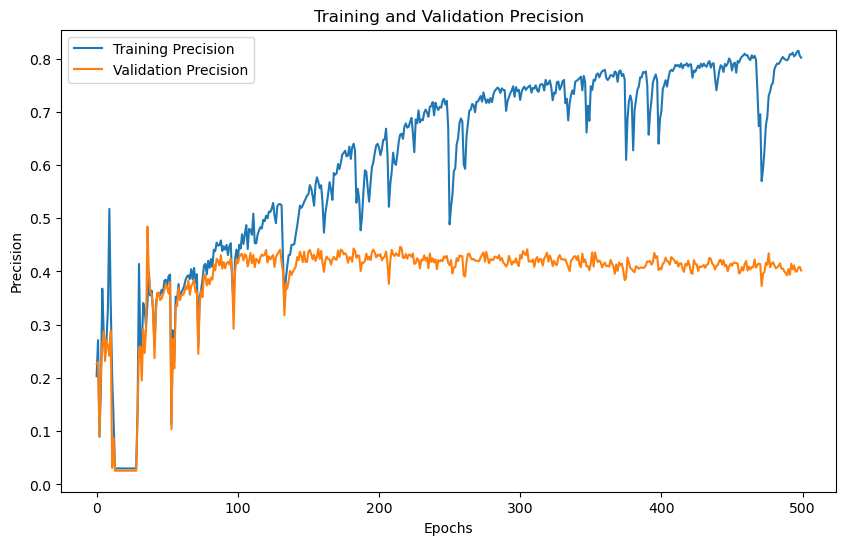

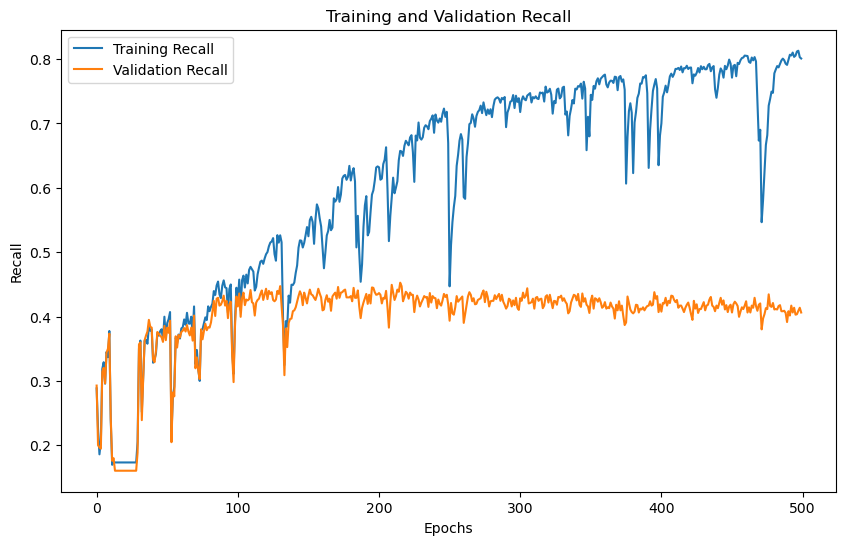

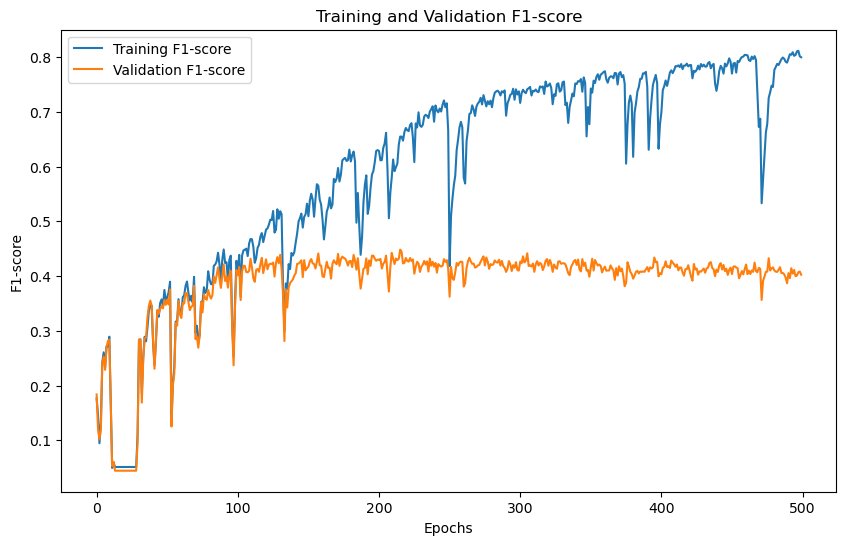

'Model Training and Evaluation Successfully completed'

In [27]:
train_model()

# N_MFCC 32

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  32
No. of classes 6
Training with N_MFCC: 32
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 32, 1)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7746, Training Accuracy: 0.2357, Training Precision:0.1677,Training Recall:0.2357,Training F1-Score:0.1520
Validation Loss: 1.7661, Validation Accuracy: 0.2297, Validation Precision:0.1477,Validation Recall:0.2297,Validation F1-Score:0.1460
Epoch [2/500],
Training Loss: 1.7491, Training Accuracy: 0.2864, Training Precision:0.1935,Training Recall:0.2864,Training F1-Score:0.1643
Validation Loss: 1.7334, Validation Accuracy: 0.2754, Validation Precision:0.1680,Validation Recall:0.2754,Validation F1-Score:0.1570
Epoch [3/500],
Training Loss: 1.7345, Training Accuracy: 0.2716, Training Precision:0.2108,Training Recall:0.2716,Training F1-Score:0.1654
Validation Loss: 1.7432, Validation Accuracy: 0.2606, Validation Precision:

Epoch [31/500],
Training Loss: 1.6363, Training Accuracy: 0.3827, Training Precision:0.3712,Training Recall:0.3827,Training F1-Score:0.3566
Validation Loss: 1.6663, Validation Accuracy: 0.3499, Validation Precision:0.3317,Validation Recall:0.3499,Validation F1-Score:0.3204
Epoch [32/500],
Training Loss: 1.6363, Training Accuracy: 0.3588, Training Precision:0.3701,Training Recall:0.3588,Training F1-Score:0.3180
Validation Loss: 1.6872, Validation Accuracy: 0.3318, Validation Precision:0.3155,Validation Recall:0.3318,Validation F1-Score:0.2886
Epoch [33/500],
Training Loss: 1.6346, Training Accuracy: 0.4121, Training Precision:0.3985,Training Recall:0.4121,Training F1-Score:0.3816
Validation Loss: 1.6467, Validation Accuracy: 0.3781, Validation Precision:0.3570,Validation Recall:0.3781,Validation F1-Score:0.3455
Epoch [34/500],
Training Loss: 1.6326, Training Accuracy: 0.4074, Training Precision:0.4351,Training Recall:0.4074,Training F1-Score:0.3964
Validation Loss: 1.6557, Validation Ac

Epoch [61/500],
Training Loss: 1.5447, Training Accuracy: 0.5083, Training Precision:0.5134,Training Recall:0.5083,Training F1-Score:0.5034
Validation Loss: 1.6282, Validation Accuracy: 0.4003, Validation Precision:0.4048,Validation Recall:0.4003,Validation F1-Score:0.3991
Epoch [62/500],
Training Loss: 1.5508, Training Accuracy: 0.4725, Training Precision:0.4868,Training Recall:0.4725,Training F1-Score:0.4517
Validation Loss: 1.6402, Validation Accuracy: 0.3895, Validation Precision:0.3780,Validation Recall:0.3895,Validation F1-Score:0.3653
Epoch [63/500],
Training Loss: 1.5363, Training Accuracy: 0.5244, Training Precision:0.5309,Training Recall:0.5244,Training F1-Score:0.5133
Validation Loss: 1.6140, Validation Accuracy: 0.4184, Validation Precision:0.4050,Validation Recall:0.4184,Validation F1-Score:0.4017
Epoch [64/500],
Training Loss: 1.5591, Training Accuracy: 0.4935, Training Precision:0.4924,Training Recall:0.4935,Training F1-Score:0.4881
Validation Loss: 1.6345, Validation Ac

Epoch [91/500],
Training Loss: 1.4531, Training Accuracy: 0.6052, Training Precision:0.6120,Training Recall:0.6052,Training F1-Score:0.6000
Validation Loss: 1.6275, Validation Accuracy: 0.4050, Validation Precision:0.3998,Validation Recall:0.4050,Validation F1-Score:0.3977
Epoch [92/500],
Training Loss: 1.4361, Training Accuracy: 0.6262, Training Precision:0.6282,Training Recall:0.6262,Training F1-Score:0.6225
Validation Loss: 1.6245, Validation Accuracy: 0.4137, Validation Precision:0.4119,Validation Recall:0.4137,Validation F1-Score:0.4108
Epoch [93/500],
Training Loss: 1.4400, Training Accuracy: 0.6130, Training Precision:0.6160,Training Recall:0.6130,Training F1-Score:0.6087
Validation Loss: 1.6272, Validation Accuracy: 0.4077, Validation Precision:0.4049,Validation Recall:0.4077,Validation F1-Score:0.4022
Epoch [94/500],
Training Loss: 1.4248, Training Accuracy: 0.6093, Training Precision:0.6282,Training Recall:0.6093,Training F1-Score:0.6052
Validation Loss: 1.6285, Validation Ac

Epoch [121/500],
Training Loss: 1.4079, Training Accuracy: 0.6610, Training Precision:0.6626,Training Recall:0.6610,Training F1-Score:0.6573
Validation Loss: 1.6454, Validation Accuracy: 0.3895, Validation Precision:0.3828,Validation Recall:0.3895,Validation F1-Score:0.3837
Epoch [122/500],
Training Loss: 1.3865, Training Accuracy: 0.6666, Training Precision:0.6733,Training Recall:0.6666,Training F1-Score:0.6635
Validation Loss: 1.6384, Validation Accuracy: 0.3956, Validation Precision:0.3895,Validation Recall:0.3956,Validation F1-Score:0.3871
Epoch [123/500],
Training Loss: 1.3843, Training Accuracy: 0.6736, Training Precision:0.6796,Training Recall:0.6736,Training F1-Score:0.6717
Validation Loss: 1.6431, Validation Accuracy: 0.3936, Validation Precision:0.3893,Validation Recall:0.3936,Validation F1-Score:0.3890
Epoch [124/500],
Training Loss: 1.3756, Training Accuracy: 0.6756, Training Precision:0.6833,Training Recall:0.6756,Training F1-Score:0.6728
Validation Loss: 1.6334, Validatio

...

Epoch [361/500],
Training Loss: 1.2052, Training Accuracy: 0.8448, Training Precision:0.8458,Training Recall:0.8448,Training F1-Score:0.8444
Validation Loss: 1.6572, Validation Accuracy: 0.3821, Validation Precision:0.3795,Validation Recall:0.3821,Validation F1-Score:0.3804
Epoch [362/500],
Training Loss: 1.2084, Training Accuracy: 0.8419, Training Precision:0.8431,Training Recall:0.8419,Training F1-Score:0.8416
Validation Loss: 1.6565, Validation Accuracy: 0.3828, Validation Precision:0.3831,Validation Recall:0.3828,Validation F1-Score:0.3824
Epoch [363/500],
Training Loss: 1.2053, Training Accuracy: 0.8360, Training Precision:0.8389,Training Recall:0.8360,Training F1-Score:0.8358
Validation Loss: 1.6451, Validation Accuracy: 0.3936, Validation Precision:0.3887,Validation Recall:0.3936,Validation F1-Score:0.3896
Epoch [364/500],
Training Loss: 1.2042, Training Accuracy: 0.8448, Training Precision:0.8460,Training Recall:0.8448,Training F1-Score:0.8443
Validation Loss: 1.6386, Validatio

Epoch [391/500],
Training Loss: 1.1981, Training Accuracy: 0.8429, Training Precision:0.8433,Training Recall:0.8429,Training F1-Score:0.8427
Validation Loss: 1.6493, Validation Accuracy: 0.3902, Validation Precision:0.3899,Validation Recall:0.3902,Validation F1-Score:0.3897
Epoch [392/500],
Training Loss: 1.2069, Training Accuracy: 0.8493, Training Precision:0.8502,Training Recall:0.8493,Training F1-Score:0.8490
Validation Loss: 1.6387, Validation Accuracy: 0.4023, Validation Precision:0.3998,Validation Recall:0.4023,Validation F1-Score:0.4002
Epoch [393/500],
Training Loss: 1.2066, Training Accuracy: 0.8421, Training Precision:0.8440,Training Recall:0.8421,Training F1-Score:0.8419
Validation Loss: 1.6438, Validation Accuracy: 0.3956, Validation Precision:0.3953,Validation Recall:0.3956,Validation F1-Score:0.3943
Epoch [394/500],
Training Loss: 1.2104, Training Accuracy: 0.8391, Training Precision:0.8403,Training Recall:0.8391,Training F1-Score:0.8389
Validation Loss: 1.6595, Validatio

Epoch [421/500],
Training Loss: 1.2182, Training Accuracy: 0.8354, Training Precision:0.8369,Training Recall:0.8354,Training F1-Score:0.8353
Validation Loss: 1.6573, Validation Accuracy: 0.3821, Validation Precision:0.3804,Validation Recall:0.3821,Validation F1-Score:0.3788
Epoch [422/500],
Training Loss: 1.2061, Training Accuracy: 0.8438, Training Precision:0.8454,Training Recall:0.8438,Training F1-Score:0.8435
Validation Loss: 1.6605, Validation Accuracy: 0.3774, Validation Precision:0.3755,Validation Recall:0.3774,Validation F1-Score:0.3738
Epoch [423/500],
Training Loss: 1.2015, Training Accuracy: 0.8507, Training Precision:0.8519,Training Recall:0.8507,Training F1-Score:0.8505
Validation Loss: 1.6565, Validation Accuracy: 0.3788, Validation Precision:0.3801,Validation Recall:0.3788,Validation F1-Score:0.3782
Epoch [424/500],
Training Loss: 1.2006, Training Accuracy: 0.8426, Training Precision:0.8429,Training Recall:0.8426,Training F1-Score:0.8424
Validation Loss: 1.6465, Validatio

Epoch [451/500],
Training Loss: 1.2040, Training Accuracy: 0.8355, Training Precision:0.8389,Training Recall:0.8355,Training F1-Score:0.8352
Validation Loss: 1.6535, Validation Accuracy: 0.3848, Validation Precision:0.3768,Validation Recall:0.3848,Validation F1-Score:0.3769
Epoch [452/500],
Training Loss: 1.2158, Training Accuracy: 0.8179, Training Precision:0.8200,Training Recall:0.8179,Training F1-Score:0.8172
Validation Loss: 1.6559, Validation Accuracy: 0.3848, Validation Precision:0.3790,Validation Recall:0.3848,Validation F1-Score:0.3784
Epoch [453/500],
Training Loss: 1.2066, Training Accuracy: 0.8507, Training Precision:0.8510,Training Recall:0.8507,Training F1-Score:0.8503
Validation Loss: 1.6463, Validation Accuracy: 0.3969, Validation Precision:0.3927,Validation Recall:0.3969,Validation F1-Score:0.3934
Epoch [454/500],
Training Loss: 1.1934, Training Accuracy: 0.8505, Training Precision:0.8515,Training Recall:0.8505,Training F1-Score:0.8503
Validation Loss: 1.6398, Validatio

Epoch [481/500],
Training Loss: 1.2102, Training Accuracy: 0.8463, Training Precision:0.8468,Training Recall:0.8463,Training F1-Score:0.8460
Validation Loss: 1.6635, Validation Accuracy: 0.3727, Validation Precision:0.3714,Validation Recall:0.3727,Validation F1-Score:0.3712
Epoch [482/500],
Training Loss: 1.1936, Training Accuracy: 0.8609, Training Precision:0.8618,Training Recall:0.8609,Training F1-Score:0.8606
Validation Loss: 1.6476, Validation Accuracy: 0.3936, Validation Precision:0.3891,Validation Recall:0.3936,Validation F1-Score:0.3899
Epoch [483/500],
Training Loss: 1.2072, Training Accuracy: 0.8502, Training Precision:0.8509,Training Recall:0.8502,Training F1-Score:0.8499
Validation Loss: 1.6625, Validation Accuracy: 0.3781, Validation Precision:0.3761,Validation Recall:0.3781,Validation F1-Score:0.3768
Epoch [484/500],
Training Loss: 1.1930, Training Accuracy: 0.8471, Training Precision:0.8495,Training Recall:0.8471,Training F1-Score:0.8470
Validation Loss: 1.6543, Validatio

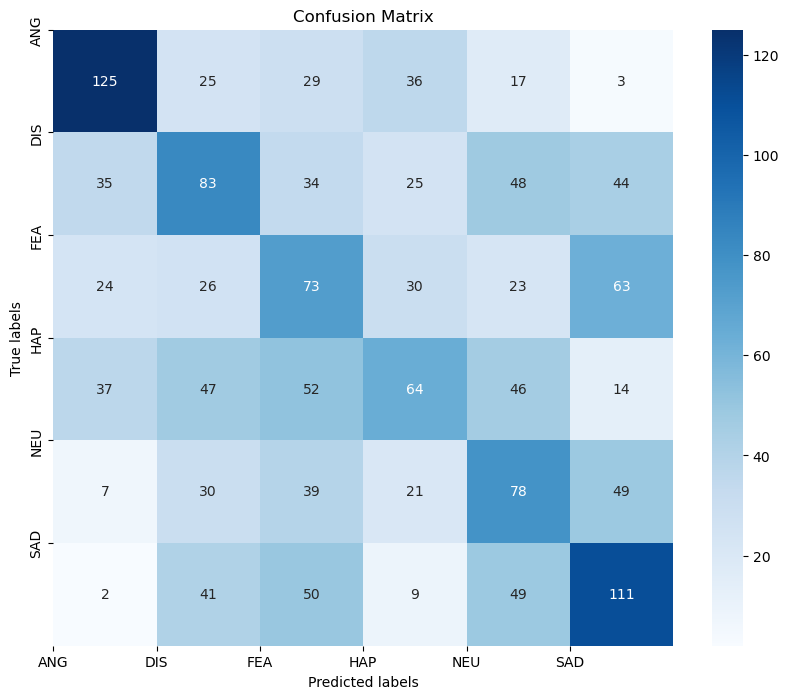

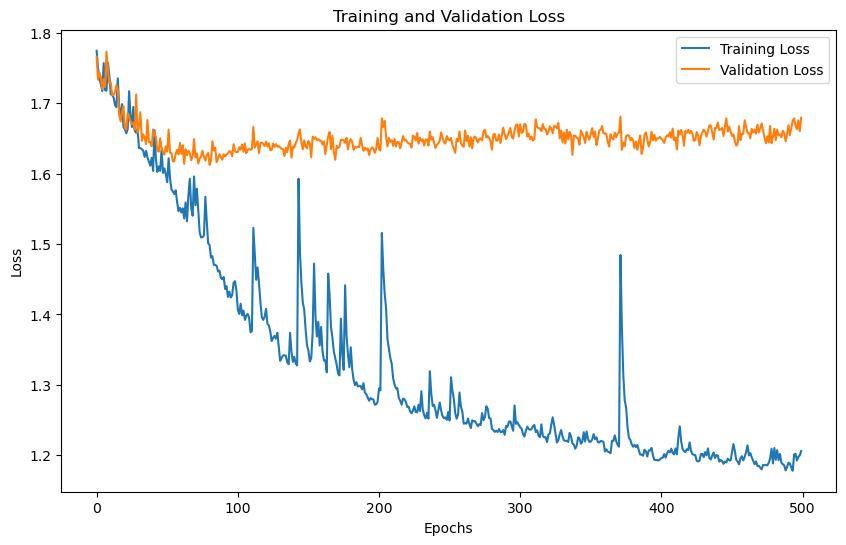

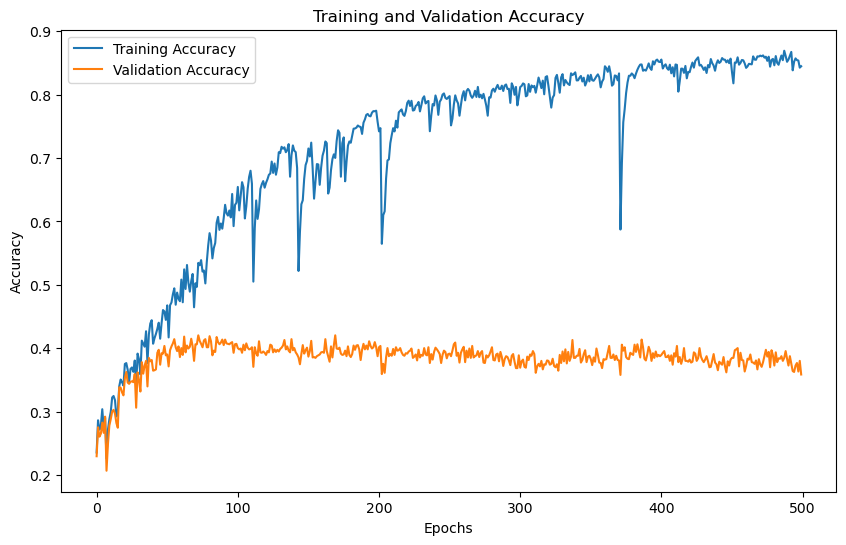

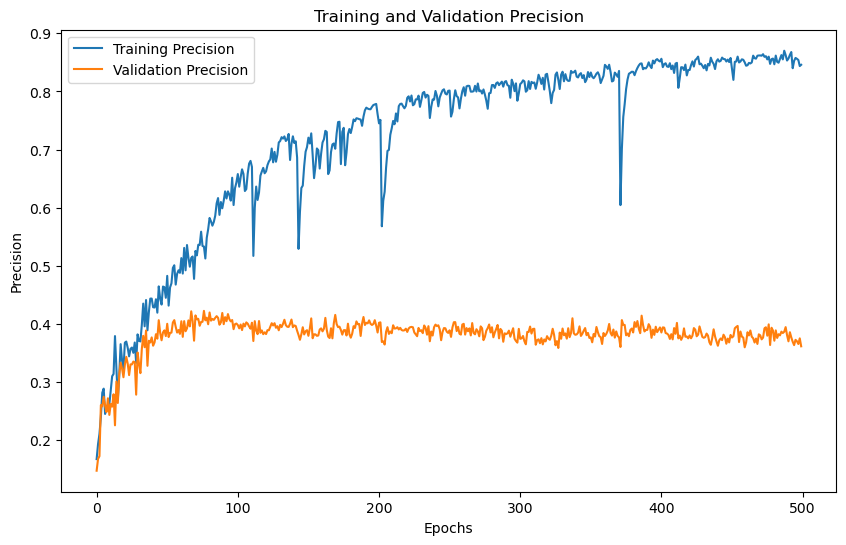

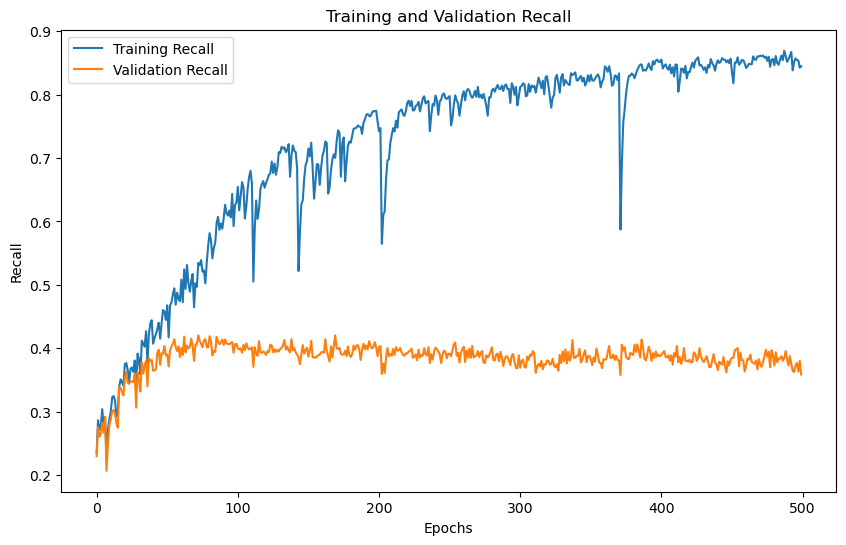

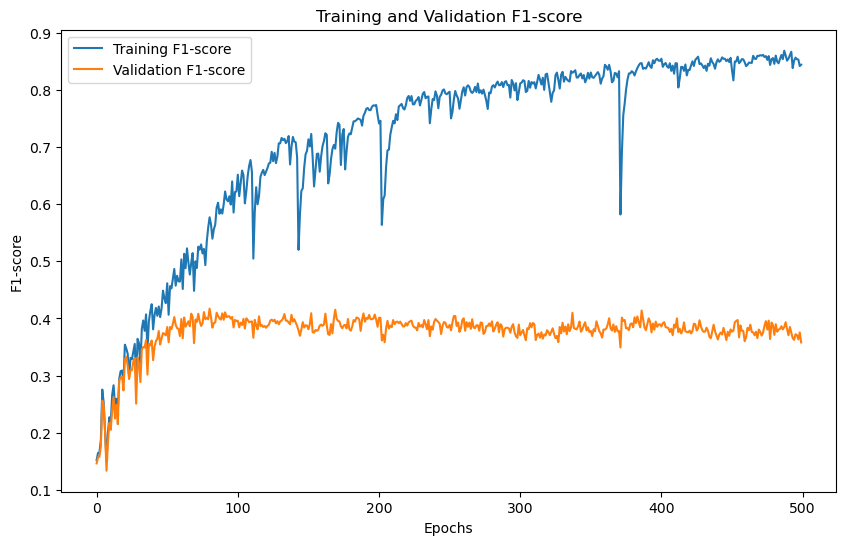

'Model Training and Evaluation Successfully completed'

In [28]:
train_model()

# N_MFCC 40

# 500 epochs

Enter dataset name:
tess, savee, crema, ravdess
 crema
Enter N_MFCC:  40
No. of classes 6
Training with N_MFCC: 40
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (7442, 40, 1)
Y Shape : (7442, 6)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7909, Training Accuracy: 0.2232, Training Precision:0.2144,Training Recall:0.2232,Training F1-Score:0.1448
Validation Loss: 1.7775, Validation Accuracy: 0.2122, Validation Precision:0.1098,Validation Recall:0.2122,Validation F1-Score:0.1330
Epoch [2/500],
Training Loss: 1.7882, Training Accuracy: 0.1697, Training Precision:0.0606,Training Recall:0.1697,Training F1-Score:0.0591
Validation Loss: 1.7903, Validation Accuracy: 0.1813, Validation Precision:0.0544,Validation Recall:0.1813,Validation F1-Score:0.0616
Epoch [3/500],
Training Loss: 1.7906, Training Accuracy: 0.1802, Training Precision:0.0610,Training Recall:0.1802,Training F1-Score:0.0834
Validation Loss: 1.7901, Validation Accuracy: 0.1632, Validation Precision:

Epoch [31/500],
Training Loss: 1.6714, Training Accuracy: 0.3672, Training Precision:0.2305,Training Recall:0.3672,Training F1-Score:0.2800
Validation Loss: 1.6526, Validation Accuracy: 0.3707, Validation Precision:0.2346,Validation Recall:0.3707,Validation F1-Score:0.2835
Epoch [32/500],
Training Loss: 1.6551, Training Accuracy: 0.3879, Training Precision:0.2619,Training Recall:0.3879,Training F1-Score:0.3050
Validation Loss: 1.6389, Validation Accuracy: 0.3848, Validation Precision:0.2575,Validation Recall:0.3848,Validation F1-Score:0.3018
Epoch [33/500],
Training Loss: 1.6446, Training Accuracy: 0.3963, Training Precision:0.2670,Training Recall:0.3963,Training F1-Score:0.3182
Validation Loss: 1.6337, Validation Accuracy: 0.3942, Validation Precision:0.2644,Validation Recall:0.3942,Validation F1-Score:0.3161
Epoch [34/500],
Training Loss: 1.6555, Training Accuracy: 0.3882, Training Precision:0.4403,Training Recall:0.3882,Training F1-Score:0.3164
Validation Loss: 1.6380, Validation Ac

Epoch [61/500],
Training Loss: 1.6526, Training Accuracy: 0.3717, Training Precision:0.3392,Training Recall:0.3717,Training F1-Score:0.3163
Validation Loss: 1.6496, Validation Accuracy: 0.3687, Validation Precision:0.3368,Validation Recall:0.3687,Validation F1-Score:0.3137
Epoch [62/500],
Training Loss: 1.6471, Training Accuracy: 0.3793, Training Precision:0.3296,Training Recall:0.3793,Training F1-Score:0.3346
Validation Loss: 1.6407, Validation Accuracy: 0.3714, Validation Precision:0.3045,Validation Recall:0.3714,Validation F1-Score:0.3231
Epoch [63/500],
Training Loss: 1.6606, Training Accuracy: 0.3840, Training Precision:0.3398,Training Recall:0.3840,Training F1-Score:0.3224
Validation Loss: 1.6401, Validation Accuracy: 0.3821, Validation Precision:0.3250,Validation Recall:0.3821,Validation F1-Score:0.3198
Epoch [64/500],
Training Loss: 1.6663, Training Accuracy: 0.3486, Training Precision:0.3151,Training Recall:0.3486,Training F1-Score:0.2769
Validation Loss: 1.6802, Validation Ac

Epoch [91/500],
Training Loss: 1.6677, Training Accuracy: 0.3892, Training Precision:0.3399,Training Recall:0.3892,Training F1-Score:0.3172
Validation Loss: 1.6375, Validation Accuracy: 0.3902, Validation Precision:0.3109,Validation Recall:0.3902,Validation F1-Score:0.3187
Epoch [92/500],
Training Loss: 1.6629, Training Accuracy: 0.3210, Training Precision:0.3079,Training Recall:0.3210,Training F1-Score:0.2543
Validation Loss: 1.6839, Validation Accuracy: 0.3224, Validation Precision:0.2493,Validation Recall:0.3224,Validation F1-Score:0.2545
Epoch [93/500],
Training Loss: 1.6746, Training Accuracy: 0.3077, Training Precision:0.3162,Training Recall:0.3077,Training F1-Score:0.2642
Validation Loss: 1.7039, Validation Accuracy: 0.3109, Validation Precision:0.3085,Validation Recall:0.3109,Validation F1-Score:0.2673
Epoch [94/500],
Training Loss: 1.6645, Training Accuracy: 0.3754, Training Precision:0.3900,Training Recall:0.3754,Training F1-Score:0.3101
Validation Loss: 1.6501, Validation Ac

Epoch [121/500],
Training Loss: 1.6190, Training Accuracy: 0.4169, Training Precision:0.3978,Training Recall:0.4169,Training F1-Score:0.3915
Validation Loss: 1.6364, Validation Accuracy: 0.3922, Validation Precision:0.3629,Validation Recall:0.3922,Validation F1-Score:0.3663
Epoch [122/500],
Training Loss: 1.6131, Training Accuracy: 0.4294, Training Precision:0.4217,Training Recall:0.4294,Training F1-Score:0.3789
Validation Loss: 1.6304, Validation Accuracy: 0.3989, Validation Precision:0.3720,Validation Recall:0.3989,Validation F1-Score:0.3493
Epoch [123/500],
Training Loss: 1.6092, Training Accuracy: 0.4260, Training Precision:0.4231,Training Recall:0.4260,Training F1-Score:0.3968
Validation Loss: 1.6332, Validation Accuracy: 0.3983, Validation Precision:0.3798,Validation Recall:0.3983,Validation F1-Score:0.3691
Epoch [124/500],
Training Loss: 1.6277, Training Accuracy: 0.4297, Training Precision:0.4239,Training Recall:0.4297,Training F1-Score:0.3871
Validation Loss: 1.6284, Validatio

...

Epoch [361/500],
Training Loss: 1.4746, Training Accuracy: 0.5975, Training Precision:0.6029,Training Recall:0.5975,Training F1-Score:0.5950
Validation Loss: 1.6627, Validation Accuracy: 0.3734, Validation Precision:0.3728,Validation Recall:0.3734,Validation F1-Score:0.3704
Epoch [362/500],
Training Loss: 1.4910, Training Accuracy: 0.5624, Training Precision:0.5658,Training Recall:0.5624,Training F1-Score:0.5585
Validation Loss: 1.6682, Validation Accuracy: 0.3694, Validation Precision:0.3639,Validation Recall:0.3694,Validation F1-Score:0.3625
Epoch [363/500],
Training Loss: 1.4749, Training Accuracy: 0.5913, Training Precision:0.5933,Training Recall:0.5913,Training F1-Score:0.5874
Validation Loss: 1.6585, Validation Accuracy: 0.3741, Validation Precision:0.3647,Validation Recall:0.3741,Validation F1-Score:0.3673
Epoch [364/500],
Training Loss: 1.4519, Training Accuracy: 0.6034, Training Precision:0.6027,Training Recall:0.6034,Training F1-Score:0.6009
Validation Loss: 1.6440, Validatio

Epoch [391/500],
Training Loss: 1.4982, Training Accuracy: 0.5780, Training Precision:0.5874,Training Recall:0.5780,Training F1-Score:0.5697
Validation Loss: 1.6436, Validation Accuracy: 0.3976, Validation Precision:0.3800,Validation Recall:0.3976,Validation F1-Score:0.3791
Epoch [392/500],
Training Loss: 1.4490, Training Accuracy: 0.6158, Training Precision:0.6163,Training Recall:0.6158,Training F1-Score:0.6147
Validation Loss: 1.6617, Validation Accuracy: 0.3768, Validation Precision:0.3801,Validation Recall:0.3768,Validation F1-Score:0.3777
Epoch [393/500],
Training Loss: 1.4318, Training Accuracy: 0.5987, Training Precision:0.6000,Training Recall:0.5987,Training F1-Score:0.5951
Validation Loss: 1.6593, Validation Accuracy: 0.3768, Validation Precision:0.3730,Validation Recall:0.3768,Validation F1-Score:0.3735
Epoch [394/500],
Training Loss: 1.4360, Training Accuracy: 0.6237, Training Precision:0.6275,Training Recall:0.6237,Training F1-Score:0.6223
Validation Loss: 1.6656, Validatio

Epoch [421/500],
Training Loss: 1.5625, Training Accuracy: 0.5107, Training Precision:0.5085,Training Recall:0.5107,Training F1-Score:0.5039
Validation Loss: 1.6572, Validation Accuracy: 0.3788, Validation Precision:0.3671,Validation Recall:0.3788,Validation F1-Score:0.3696
Epoch [422/500],
Training Loss: 1.5210, Training Accuracy: 0.5260, Training Precision:0.5327,Training Recall:0.5260,Training F1-Score:0.5238
Validation Loss: 1.6534, Validation Accuracy: 0.3862, Validation Precision:0.3793,Validation Recall:0.3862,Validation F1-Score:0.3803
Epoch [423/500],
Training Loss: 1.4977, Training Accuracy: 0.5575, Training Precision:0.5578,Training Recall:0.5575,Training F1-Score:0.5531
Validation Loss: 1.6589, Validation Accuracy: 0.3801, Validation Precision:0.3732,Validation Recall:0.3801,Validation F1-Score:0.3730
Epoch [424/500],
Training Loss: 1.5032, Training Accuracy: 0.5411, Training Precision:0.5418,Training Recall:0.5411,Training F1-Score:0.5402
Validation Loss: 1.6591, Validatio

Epoch [451/500],
Training Loss: 1.4345, Training Accuracy: 0.6296, Training Precision:0.6309,Training Recall:0.6296,Training F1-Score:0.6274
Validation Loss: 1.6653, Validation Accuracy: 0.3687, Validation Precision:0.3661,Validation Recall:0.3687,Validation F1-Score:0.3667
Epoch [452/500],
Training Loss: 1.5122, Training Accuracy: 0.4646, Training Precision:0.4807,Training Recall:0.4646,Training F1-Score:0.4591
Validation Loss: 1.6898, Validation Accuracy: 0.3486, Validation Precision:0.3499,Validation Recall:0.3486,Validation F1-Score:0.3394
Epoch [453/500],
Training Loss: 1.5436, Training Accuracy: 0.5721, Training Precision:0.5727,Training Recall:0.5721,Training F1-Score:0.5670
Validation Loss: 1.6777, Validation Accuracy: 0.3580, Validation Precision:0.3495,Validation Recall:0.3580,Validation F1-Score:0.3499
Epoch [454/500],
Training Loss: 1.4774, Training Accuracy: 0.5554, Training Precision:0.5591,Training Recall:0.5554,Training F1-Score:0.5489
Validation Loss: 1.6717, Validatio

Epoch [481/500],
Training Loss: 1.5032, Training Accuracy: 0.5503, Training Precision:0.5575,Training Recall:0.5503,Training F1-Score:0.5440
Validation Loss: 1.6610, Validation Accuracy: 0.3741, Validation Precision:0.3771,Validation Recall:0.3741,Validation F1-Score:0.3663
Epoch [482/500],
Training Loss: 1.5033, Training Accuracy: 0.5597, Training Precision:0.5688,Training Recall:0.5597,Training F1-Score:0.5490
Validation Loss: 1.6609, Validation Accuracy: 0.3741, Validation Precision:0.3684,Validation Recall:0.3741,Validation F1-Score:0.3591
Epoch [483/500],
Training Loss: 1.5015, Training Accuracy: 0.5486, Training Precision:0.5574,Training Recall:0.5486,Training F1-Score:0.5402
Validation Loss: 1.6732, Validation Accuracy: 0.3580, Validation Precision:0.3541,Validation Recall:0.3580,Validation F1-Score:0.3441
Epoch [484/500],
Training Loss: 1.4884, Training Accuracy: 0.5629, Training Precision:0.5707,Training Recall:0.5629,Training F1-Score:0.5553
Validation Loss: 1.6613, Validatio

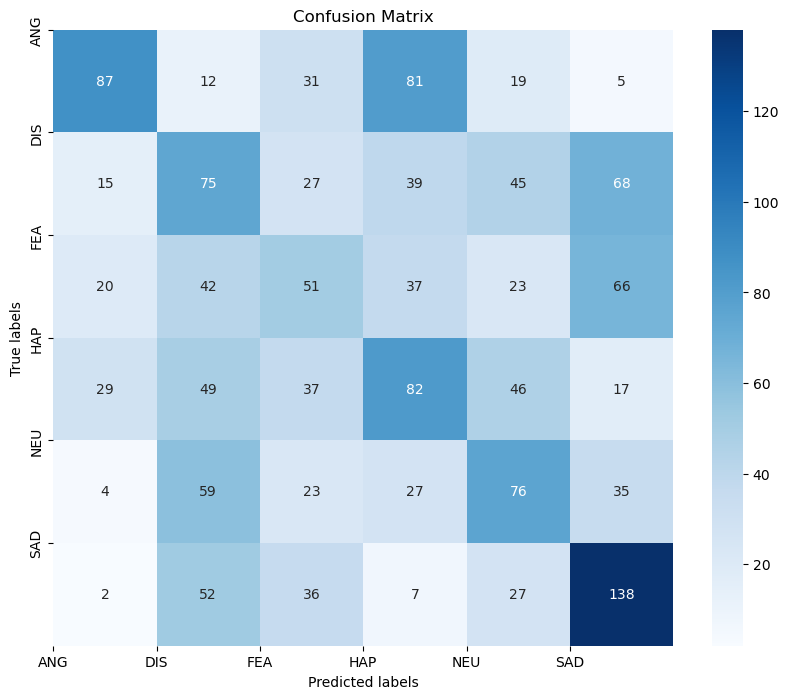

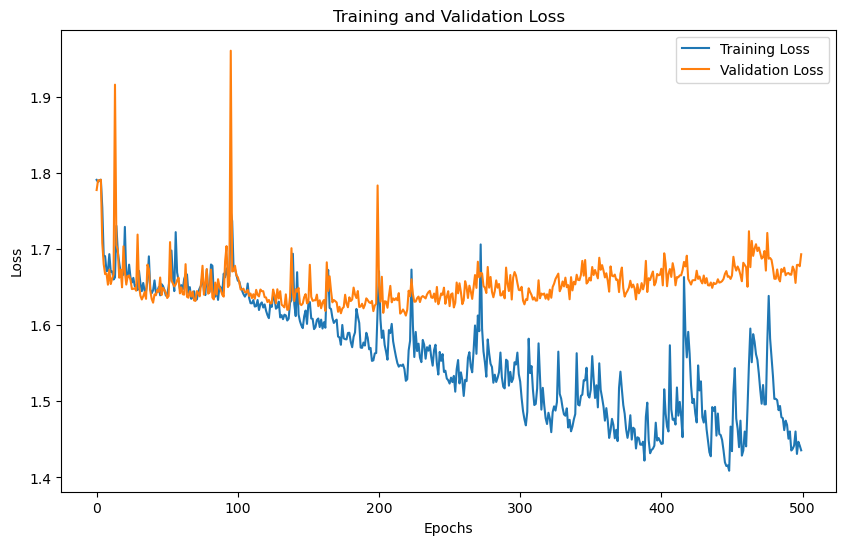

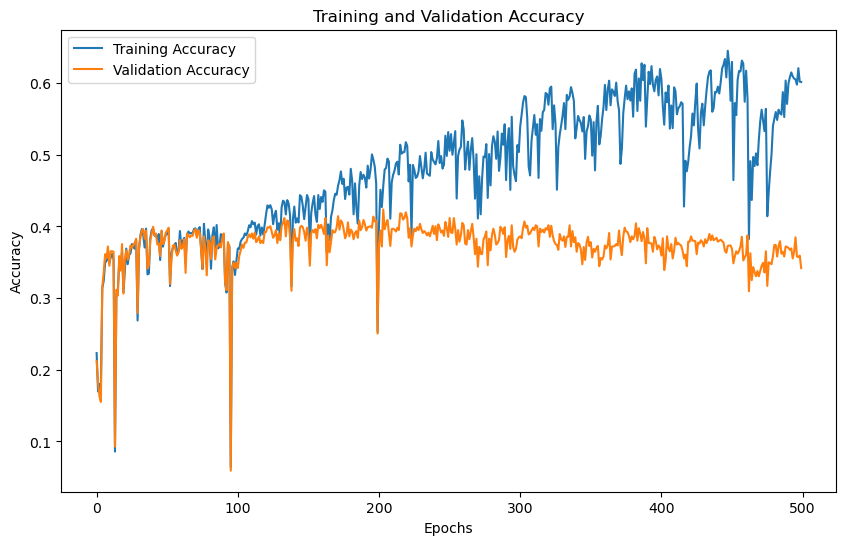

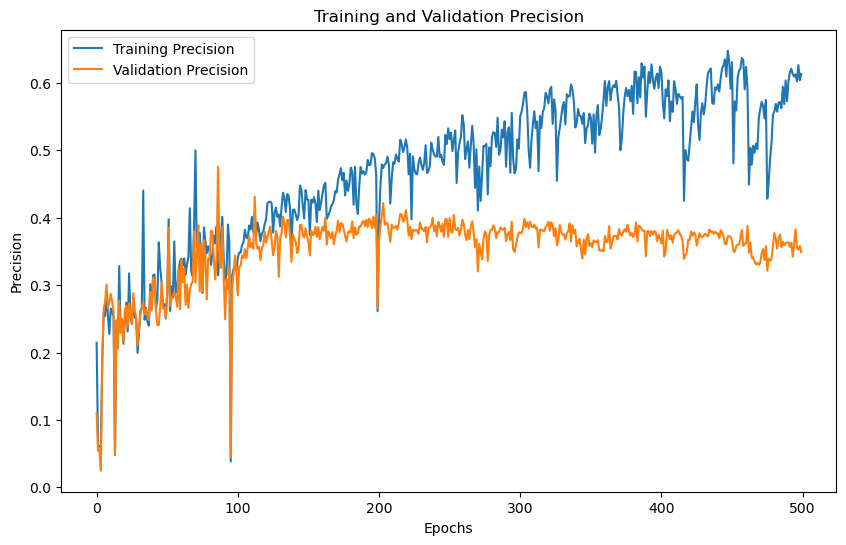

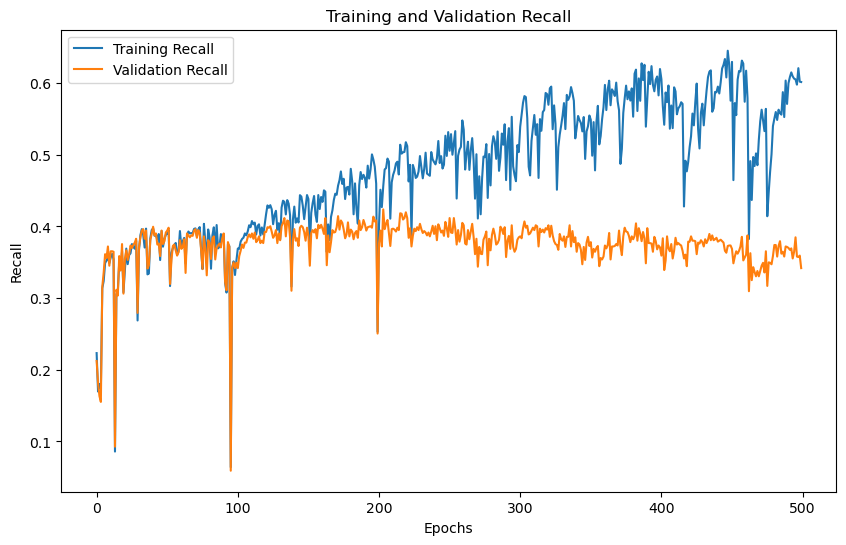

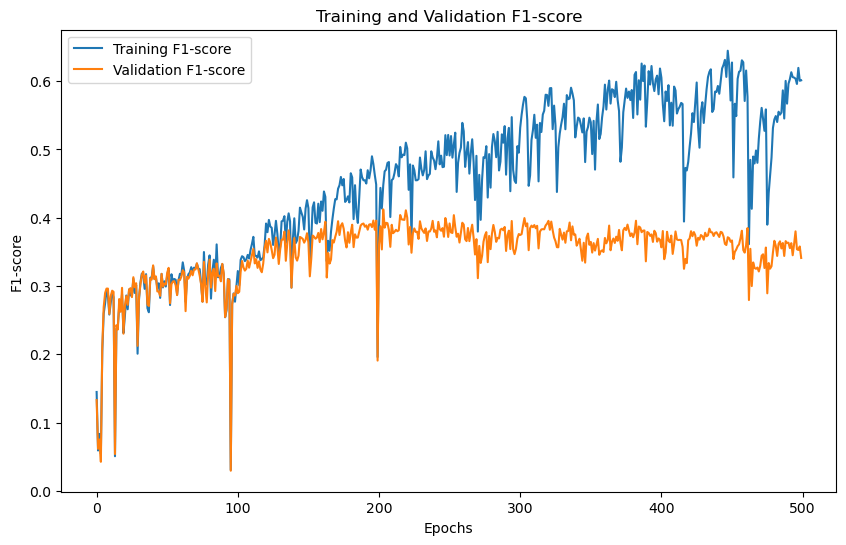

'Model Training and Evaluation Successfully completed'

In [29]:
train_model()

# TESS

# N_MFCC 16

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  16
No. of classes 7
Training with N_MFCC: 16
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 16, 1)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8989, Training Accuracy: 0.4054, Training Precision:0.3221,Training Recall:0.4054,Training F1-Score:0.3075
Validation Loss: 1.8051, Validation Accuracy: 0.3804, Validation Precision:0.2551,Validation Recall:0.3804,Validation F1-Score:0.2779
Epoch [2/500],
Training Loss: 1.7120, Training Accuracy: 0.5353, Training Precision:0.4788,Training Recall:0.5353,Training F1-Score:0.4925
Validation Loss: 1.6837, Validation Accuracy: 0.4929, Validation Precision:0.4265,Validation Recall:0.4929,Validation F1-Score:0.4408
Epoch [3/500],
Training Loss: 1.5999, Training Accuracy: 0.6393, Training Precision:0.6401,Training Recall:0.6393,Training F1-Score:0.6208
Validation Loss: 1.5683, Validation Accuracy: 0.6054, Validation Precision:0

Epoch [31/500],
Training Loss: 1.3222, Training Accuracy: 0.8478, Training Precision:0.8811,Training Recall:0.8478,Training F1-Score:0.8434
Validation Loss: 1.3253, Validation Accuracy: 0.8411, Validation Precision:0.8733,Validation Recall:0.8411,Validation F1-Score:0.8383
Epoch [32/500],
Training Loss: 1.3140, Training Accuracy: 0.8692, Training Precision:0.8918,Training Recall:0.8692,Training F1-Score:0.8650
Validation Loss: 1.3200, Validation Accuracy: 0.8446, Validation Precision:0.8655,Validation Recall:0.8446,Validation F1-Score:0.8409
Epoch [33/500],
Training Loss: 1.3084, Training Accuracy: 0.8670, Training Precision:0.8926,Training Recall:0.8670,Training F1-Score:0.8628
Validation Loss: 1.3136, Validation Accuracy: 0.8554, Validation Precision:0.8807,Validation Recall:0.8554,Validation F1-Score:0.8535
Epoch [34/500],
Training Loss: 1.3021, Training Accuracy: 0.8674, Training Precision:0.8984,Training Recall:0.8674,Training F1-Score:0.8655
Validation Loss: 1.3207, Validation Ac

Epoch [61/500],
Training Loss: 1.2723, Training Accuracy: 0.8835, Training Precision:0.9134,Training Recall:0.8835,Training F1-Score:0.8803
Validation Loss: 1.3121, Validation Accuracy: 0.8554, Validation Precision:0.8832,Validation Recall:0.8554,Validation F1-Score:0.8552
Epoch [62/500],
Training Loss: 1.2831, Training Accuracy: 0.8647, Training Precision:0.8962,Training Recall:0.8647,Training F1-Score:0.8615
Validation Loss: 1.3379, Validation Accuracy: 0.8321, Validation Precision:0.8619,Validation Recall:0.8321,Validation F1-Score:0.8316
Epoch [63/500],
Training Loss: 1.2744, Training Accuracy: 0.8920, Training Precision:0.9155,Training Recall:0.8920,Training F1-Score:0.8876
Validation Loss: 1.3064, Validation Accuracy: 0.8607, Validation Precision:0.8809,Validation Recall:0.8607,Validation F1-Score:0.8587
Epoch [64/500],
Training Loss: 1.2731, Training Accuracy: 0.8929, Training Precision:0.9139,Training Recall:0.8929,Training F1-Score:0.8875
Validation Loss: 1.2985, Validation Ac

Epoch [91/500],
Training Loss: 1.2587, Training Accuracy: 0.9112, Training Precision:0.9340,Training Recall:0.9112,Training F1-Score:0.9058
Validation Loss: 1.2886, Validation Accuracy: 0.8768, Validation Precision:0.9021,Validation Recall:0.8768,Validation F1-Score:0.8752
Epoch [92/500],
Training Loss: 1.2555, Training Accuracy: 0.9089, Training Precision:0.9271,Training Recall:0.9089,Training F1-Score:0.9023
Validation Loss: 1.2898, Validation Accuracy: 0.8768, Validation Precision:0.8920,Validation Recall:0.8768,Validation F1-Score:0.8728
Epoch [93/500],
Training Loss: 1.2594, Training Accuracy: 0.9085, Training Precision:0.9344,Training Recall:0.9085,Training F1-Score:0.9042
Validation Loss: 1.3014, Validation Accuracy: 0.8643, Validation Precision:0.8849,Validation Recall:0.8643,Validation F1-Score:0.8626
Epoch [94/500],
Training Loss: 1.2574, Training Accuracy: 0.9138, Training Precision:0.9362,Training Recall:0.9138,Training F1-Score:0.9084
Validation Loss: 1.3010, Validation Ac

Epoch [121/500],
Training Loss: 1.2511, Training Accuracy: 0.9161, Training Precision:0.9354,Training Recall:0.9161,Training F1-Score:0.9097
Validation Loss: 1.2855, Validation Accuracy: 0.8804, Validation Precision:0.9024,Validation Recall:0.8804,Validation F1-Score:0.8771
Epoch [122/500],
Training Loss: 1.2512, Training Accuracy: 0.9156, Training Precision:0.9350,Training Recall:0.9156,Training F1-Score:0.9092
Validation Loss: 1.2930, Validation Accuracy: 0.8714, Validation Precision:0.8920,Validation Recall:0.8714,Validation F1-Score:0.8681
Epoch [123/500],
Training Loss: 1.2505, Training Accuracy: 0.9152, Training Precision:0.9370,Training Recall:0.9152,Training F1-Score:0.9095
Validation Loss: 1.3039, Validation Accuracy: 0.8607, Validation Precision:0.8887,Validation Recall:0.8607,Validation F1-Score:0.8597
Epoch [124/500],
Training Loss: 1.2534, Training Accuracy: 0.9138, Training Precision:0.9330,Training Recall:0.9138,Training F1-Score:0.9076
Validation Loss: 1.2959, Validatio

...

Epoch [361/500],
Training Loss: 1.1808, Training Accuracy: 0.9875, Training Precision:0.9875,Training Recall:0.9875,Training F1-Score:0.9875
Validation Loss: 1.2644, Validation Accuracy: 0.9000, Validation Precision:0.9020,Validation Recall:0.9000,Validation F1-Score:0.8998
Epoch [362/500],
Training Loss: 1.1781, Training Accuracy: 0.9906, Training Precision:0.9906,Training Recall:0.9906,Training F1-Score:0.9906
Validation Loss: 1.2548, Validation Accuracy: 0.9107, Validation Precision:0.9114,Validation Recall:0.9107,Validation F1-Score:0.9108
Epoch [363/500],
Training Loss: 1.1801, Training Accuracy: 0.9830, Training Precision:0.9832,Training Recall:0.9830,Training F1-Score:0.9830
Validation Loss: 1.2621, Validation Accuracy: 0.9000, Validation Precision:0.9018,Validation Recall:0.9000,Validation F1-Score:0.8998
Epoch [364/500],
Training Loss: 1.1895, Training Accuracy: 0.9808, Training Precision:0.9812,Training Recall:0.9808,Training F1-Score:0.9808
Validation Loss: 1.2636, Validatio

Epoch [391/500],
Training Loss: 1.1819, Training Accuracy: 0.9906, Training Precision:0.9906,Training Recall:0.9906,Training F1-Score:0.9906
Validation Loss: 1.2780, Validation Accuracy: 0.8875, Validation Precision:0.8927,Validation Recall:0.8875,Validation F1-Score:0.8876
Epoch [392/500],
Training Loss: 1.1737, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.2700, Validation Accuracy: 0.8964, Validation Precision:0.8998,Validation Recall:0.8964,Validation F1-Score:0.8967
Epoch [393/500],
Training Loss: 1.1733, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.2663, Validation Accuracy: 0.8982, Validation Precision:0.9041,Validation Recall:0.8982,Validation F1-Score:0.8987
Epoch [394/500],
Training Loss: 1.1717, Training Accuracy: 0.9924, Training Precision:0.9925,Training Recall:0.9924,Training F1-Score:0.9924
Validation Loss: 1.2697, Validatio

Epoch [421/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2617, Validation Accuracy: 0.9036, Validation Precision:0.9052,Validation Recall:0.9036,Validation F1-Score:0.9036
Epoch [422/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2616, Validation Accuracy: 0.9036, Validation Precision:0.9052,Validation Recall:0.9036,Validation F1-Score:0.9036
Epoch [423/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2616, Validation Accuracy: 0.9036, Validation Precision:0.9054,Validation Recall:0.9036,Validation F1-Score:0.9037
Epoch [424/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2618, Validatio

Epoch [451/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2622, Validation Accuracy: 0.9036, Validation Precision:0.9051,Validation Recall:0.9036,Validation F1-Score:0.9037
Epoch [452/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2621, Validation Accuracy: 0.9036, Validation Precision:0.9051,Validation Recall:0.9036,Validation F1-Score:0.9037
Epoch [453/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2621, Validation Accuracy: 0.9036, Validation Precision:0.9051,Validation Recall:0.9036,Validation F1-Score:0.9037
Epoch [454/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2621, Validatio

Epoch [481/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2601, Validation Accuracy: 0.9036, Validation Precision:0.9054,Validation Recall:0.9036,Validation F1-Score:0.9037
Epoch [482/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2612, Validation Accuracy: 0.9018, Validation Precision:0.9034,Validation Recall:0.9018,Validation F1-Score:0.9019
Epoch [483/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2610, Validation Accuracy: 0.9054, Validation Precision:0.9060,Validation Recall:0.9054,Validation F1-Score:0.9051
Epoch [484/500],
Training Loss: 1.1708, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.2611, Validatio

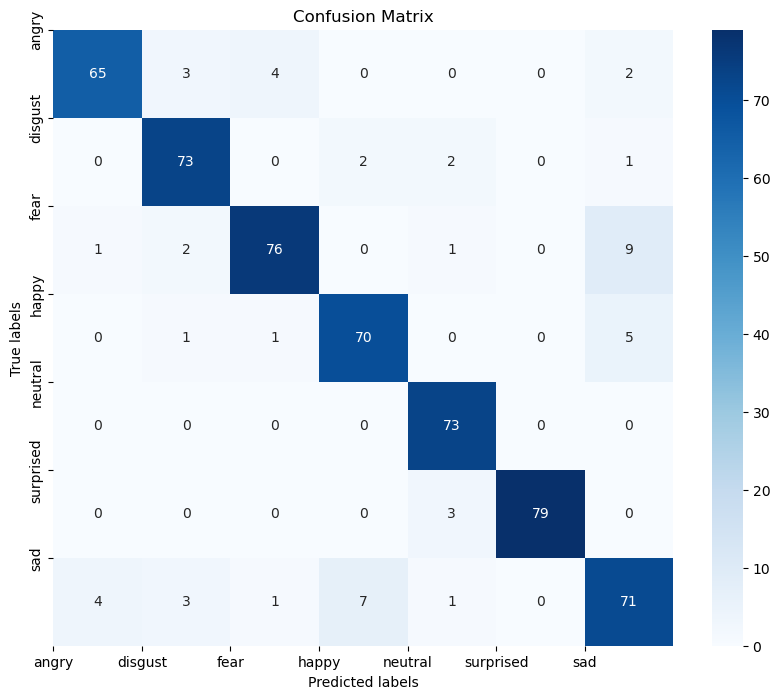

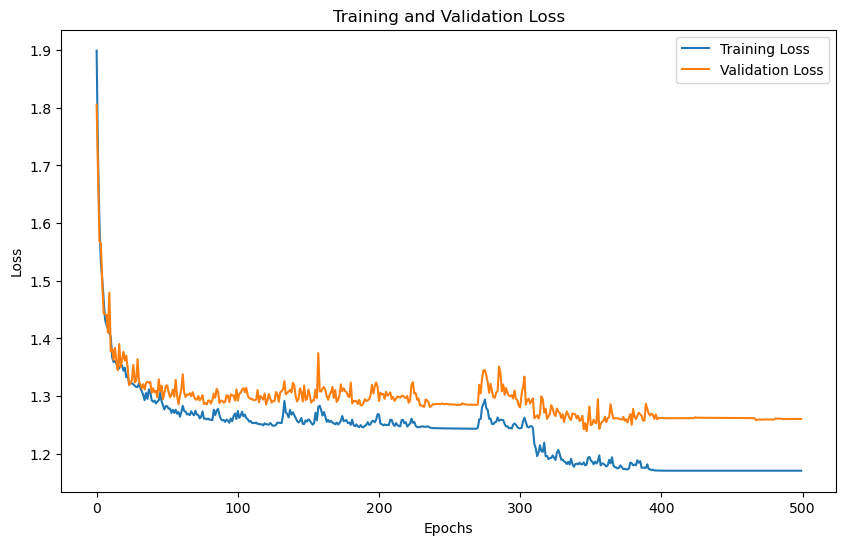

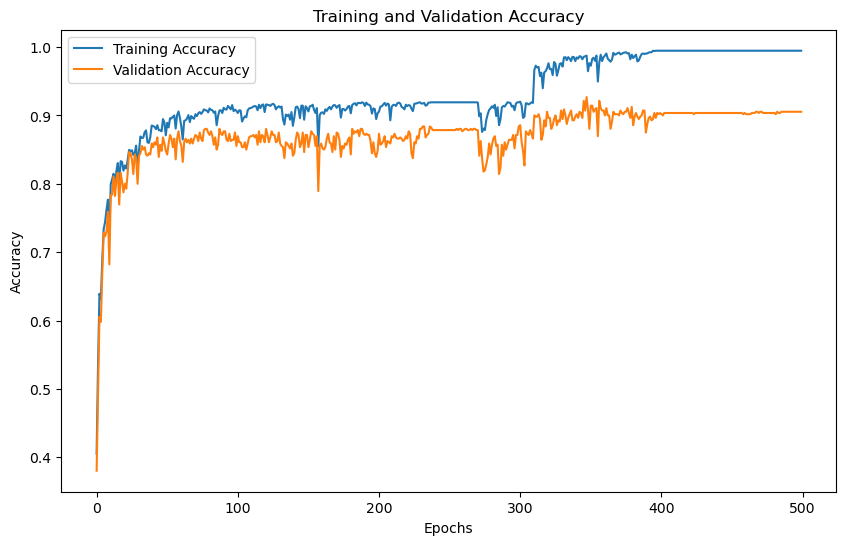

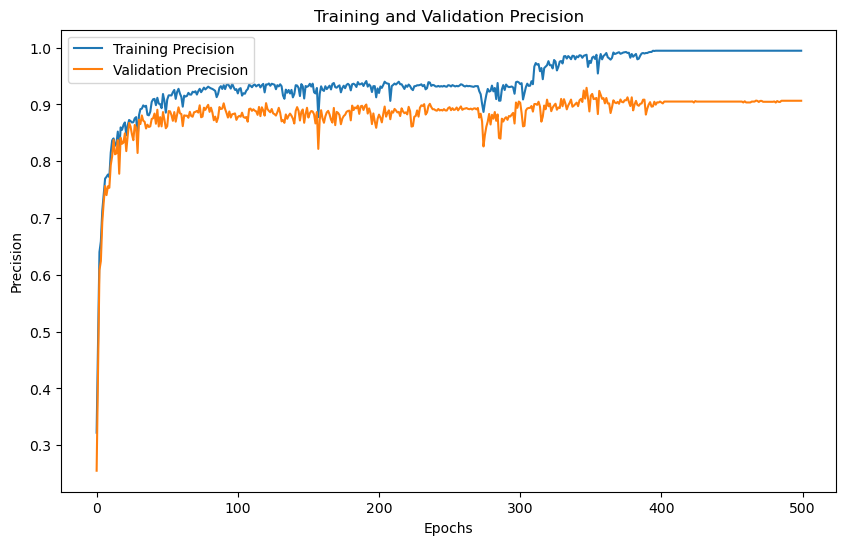

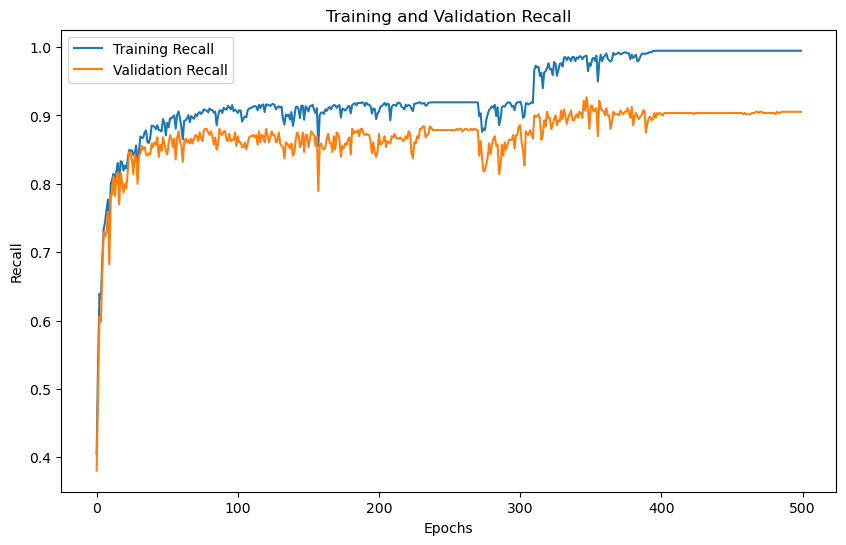

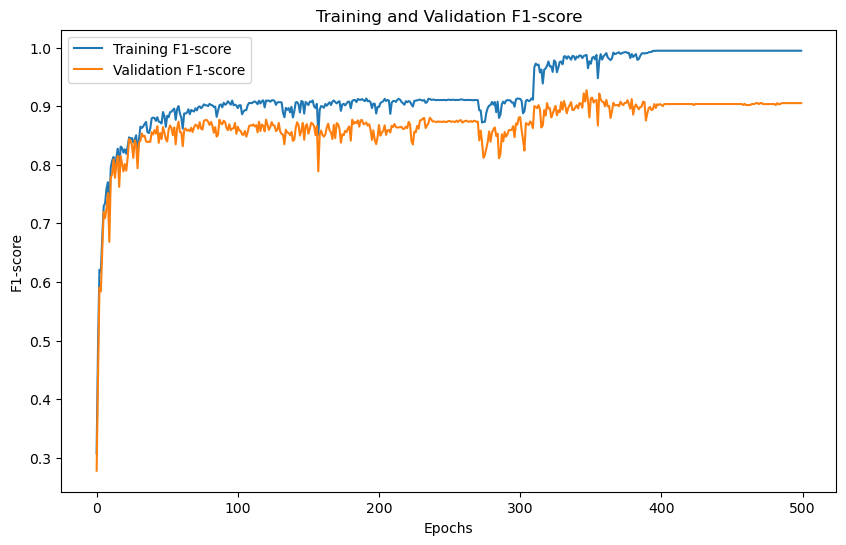

'Model Training and Evaluation Successfully completed'

In [30]:
train_model()

# N_MFCC 24

# 500 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  24
No. of classes 7
Training with N_MFCC: 24
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 24, 1)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.8094, Training Accuracy: 0.5138, Training Precision:0.4801,Training Recall:0.5138,Training F1-Score:0.4676
Validation Loss: 1.6183, Validation Accuracy: 0.5411, Validation Precision:0.4839,Validation Recall:0.5411,Validation F1-Score:0.4937
Epoch [2/500],
Training Loss: 1.5746, Training Accuracy: 0.6451, Training Precision:0.5826,Training Recall:0.6451,Training F1-Score:0.5889
Validation Loss: 1.5085, Validation Accuracy: 0.6518, Validation Precision:0.5996,Validation Recall:0.6518,Validation F1-Score:0.5960
Epoch [3/500],
Training Loss: 1.5225, Training Accuracy: 0.6674, Training Precision:0.6159,Training Recall:0.6674,Training F1-Score:0.6088
Validation Loss: 1.4839, Validation Accuracy: 0.6732, Validation Precision:0

Epoch [31/500],
Training Loss: 1.2041, Training Accuracy: 0.9746, Training Precision:0.9747,Training Recall:0.9746,Training F1-Score:0.9746
Validation Loss: 1.2175, Validation Accuracy: 0.9482, Validation Precision:0.9487,Validation Recall:0.9482,Validation F1-Score:0.9480
Epoch [32/500],
Training Loss: 1.1995, Training Accuracy: 0.9241, Training Precision:0.9340,Training Recall:0.9241,Training F1-Score:0.9230
Validation Loss: 1.2634, Validation Accuracy: 0.9036, Validation Precision:0.9137,Validation Recall:0.9036,Validation F1-Score:0.9014
Epoch [33/500],
Training Loss: 1.2140, Training Accuracy: 0.9571, Training Precision:0.9595,Training Recall:0.9571,Training F1-Score:0.9574
Validation Loss: 1.2548, Validation Accuracy: 0.9054, Validation Precision:0.9129,Validation Recall:0.9054,Validation F1-Score:0.9063
Epoch [34/500],
Training Loss: 1.2086, Training Accuracy: 0.9616, Training Precision:0.9620,Training Recall:0.9616,Training F1-Score:0.9615
Validation Loss: 1.2296, Validation Ac

Epoch [61/500],
Training Loss: 1.1984, Training Accuracy: 0.9679, Training Precision:0.9687,Training Recall:0.9679,Training F1-Score:0.9678
Validation Loss: 1.2461, Validation Accuracy: 0.9214, Validation Precision:0.9228,Validation Recall:0.9214,Validation F1-Score:0.9210
Epoch [62/500],
Training Loss: 1.1958, Training Accuracy: 0.9848, Training Precision:0.9849,Training Recall:0.9848,Training F1-Score:0.9848
Validation Loss: 1.2177, Validation Accuracy: 0.9482, Validation Precision:0.9487,Validation Recall:0.9482,Validation F1-Score:0.9482
Epoch [63/500],
Training Loss: 1.1840, Training Accuracy: 0.9808, Training Precision:0.9816,Training Recall:0.9808,Training F1-Score:0.9809
Validation Loss: 1.2216, Validation Accuracy: 0.9464, Validation Precision:0.9503,Validation Recall:0.9464,Validation F1-Score:0.9471
Epoch [64/500],
Training Loss: 1.1811, Training Accuracy: 0.9817, Training Precision:0.9825,Training Recall:0.9817,Training F1-Score:0.9817
Validation Loss: 1.2132, Validation Ac

Epoch [91/500],
Training Loss: 1.1890, Training Accuracy: 0.9768, Training Precision:0.9774,Training Recall:0.9768,Training F1-Score:0.9767
Validation Loss: 1.2222, Validation Accuracy: 0.9411, Validation Precision:0.9431,Validation Recall:0.9411,Validation F1-Score:0.9408
Epoch [92/500],
Training Loss: 1.1823, Training Accuracy: 0.9875, Training Precision:0.9875,Training Recall:0.9875,Training F1-Score:0.9875
Validation Loss: 1.2085, Validation Accuracy: 0.9571, Validation Precision:0.9577,Validation Recall:0.9571,Validation F1-Score:0.9571
Epoch [93/500],
Training Loss: 1.1804, Training Accuracy: 0.9839, Training Precision:0.9840,Training Recall:0.9839,Training F1-Score:0.9839
Validation Loss: 1.2163, Validation Accuracy: 0.9464, Validation Precision:0.9474,Validation Recall:0.9464,Validation F1-Score:0.9461
Epoch [94/500],
Training Loss: 1.1789, Training Accuracy: 0.9929, Training Precision:0.9929,Training Recall:0.9929,Training F1-Score:0.9929
Validation Loss: 1.2133, Validation Ac

Epoch [121/500],
Training Loss: 1.1772, Training Accuracy: 0.9808, Training Precision:0.9814,Training Recall:0.9808,Training F1-Score:0.9808
Validation Loss: 1.2204, Validation Accuracy: 0.9446, Validation Precision:0.9468,Validation Recall:0.9446,Validation F1-Score:0.9448
Epoch [122/500],
Training Loss: 1.1816, Training Accuracy: 0.9871, Training Precision:0.9872,Training Recall:0.9871,Training F1-Score:0.9870
Validation Loss: 1.2205, Validation Accuracy: 0.9429, Validation Precision:0.9448,Validation Recall:0.9429,Validation F1-Score:0.9428
Epoch [123/500],
Training Loss: 1.1759, Training Accuracy: 0.9875, Training Precision:0.9877,Training Recall:0.9875,Training F1-Score:0.9875
Validation Loss: 1.2119, Validation Accuracy: 0.9518, Validation Precision:0.9536,Validation Recall:0.9518,Validation F1-Score:0.9520
Epoch [124/500],
Training Loss: 1.1807, Training Accuracy: 0.9866, Training Precision:0.9866,Training Recall:0.9866,Training F1-Score:0.9866
Validation Loss: 1.2207, Validatio

...

Epoch [361/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2032, Validation Accuracy: 0.9607, Validation Precision:0.9612,Validation Recall:0.9607,Validation F1-Score:0.9606
Epoch [362/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2032, Validation Accuracy: 0.9607, Validation Precision:0.9612,Validation Recall:0.9607,Validation F1-Score:0.9606
Epoch [363/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2032, Validation Accuracy: 0.9607, Validation Precision:0.9612,Validation Recall:0.9607,Validation F1-Score:0.9606
Epoch [364/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2032, Validatio

Epoch [391/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2029, Validation Accuracy: 0.9625, Validation Precision:0.9630,Validation Recall:0.9625,Validation F1-Score:0.9623
Epoch [392/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2029, Validation Accuracy: 0.9625, Validation Precision:0.9630,Validation Recall:0.9625,Validation F1-Score:0.9623
Epoch [393/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2028, Validation Accuracy: 0.9625, Validation Precision:0.9630,Validation Recall:0.9625,Validation F1-Score:0.9623
Epoch [394/500],
Training Loss: 1.1677, Training Accuracy: 0.9978, Training Precision:0.9978,Training Recall:0.9978,Training F1-Score:0.9978
Validation Loss: 1.2028, Validatio

Epoch [421/500],
Training Loss: 1.1775, Training Accuracy: 0.9920, Training Precision:0.9920,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.2191, Validation Accuracy: 0.9446, Validation Precision:0.9464,Validation Recall:0.9446,Validation F1-Score:0.9450
Epoch [422/500],
Training Loss: 1.1819, Training Accuracy: 0.9487, Training Precision:0.9521,Training Recall:0.9487,Training F1-Score:0.9484
Validation Loss: 1.2554, Validation Accuracy: 0.9107, Validation Precision:0.9162,Validation Recall:0.9107,Validation F1-Score:0.9097
Epoch [423/500],
Training Loss: 1.1909, Training Accuracy: 0.9902, Training Precision:0.9902,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 1.2173, Validation Accuracy: 0.9482, Validation Precision:0.9485,Validation Recall:0.9482,Validation F1-Score:0.9481
Epoch [424/500],
Training Loss: 1.1736, Training Accuracy: 0.9933, Training Precision:0.9933,Training Recall:0.9933,Training F1-Score:0.9933
Validation Loss: 1.2146, Validatio

Epoch [451/500],
Training Loss: 1.1720, Training Accuracy: 0.9960, Training Precision:0.9960,Training Recall:0.9960,Training F1-Score:0.9960
Validation Loss: 1.2026, Validation Accuracy: 0.9625, Validation Precision:0.9638,Validation Recall:0.9625,Validation F1-Score:0.9626
Epoch [452/500],
Training Loss: 1.1694, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2087, Validation Accuracy: 0.9554, Validation Precision:0.9565,Validation Recall:0.9554,Validation F1-Score:0.9555
Epoch [453/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2085, Validation Accuracy: 0.9554, Validation Precision:0.9569,Validation Recall:0.9554,Validation F1-Score:0.9555
Epoch [454/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2086, Validatio

Epoch [481/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2089, Validation Accuracy: 0.9554, Validation Precision:0.9569,Validation Recall:0.9554,Validation F1-Score:0.9555
Epoch [482/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2089, Validation Accuracy: 0.9554, Validation Precision:0.9569,Validation Recall:0.9554,Validation F1-Score:0.9555
Epoch [483/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2089, Validation Accuracy: 0.9554, Validation Precision:0.9569,Validation Recall:0.9554,Validation F1-Score:0.9555
Epoch [484/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.2089, Validatio

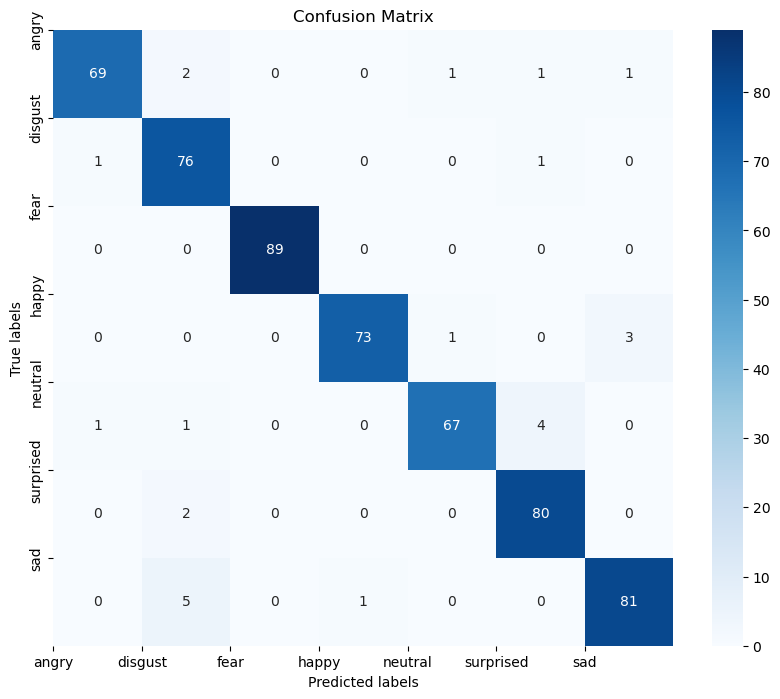

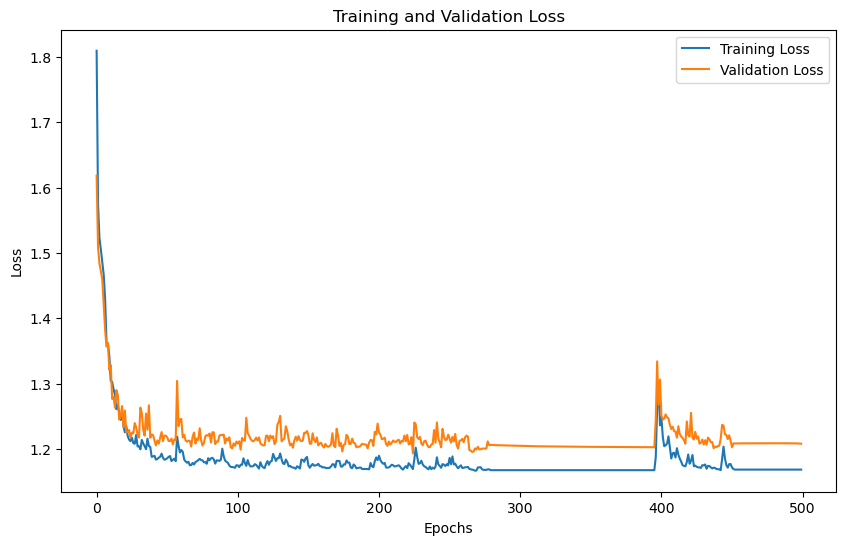

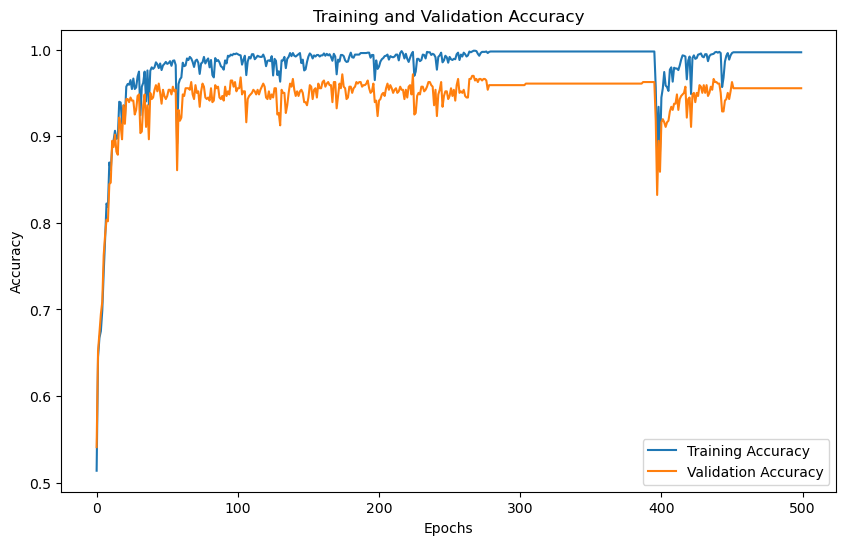

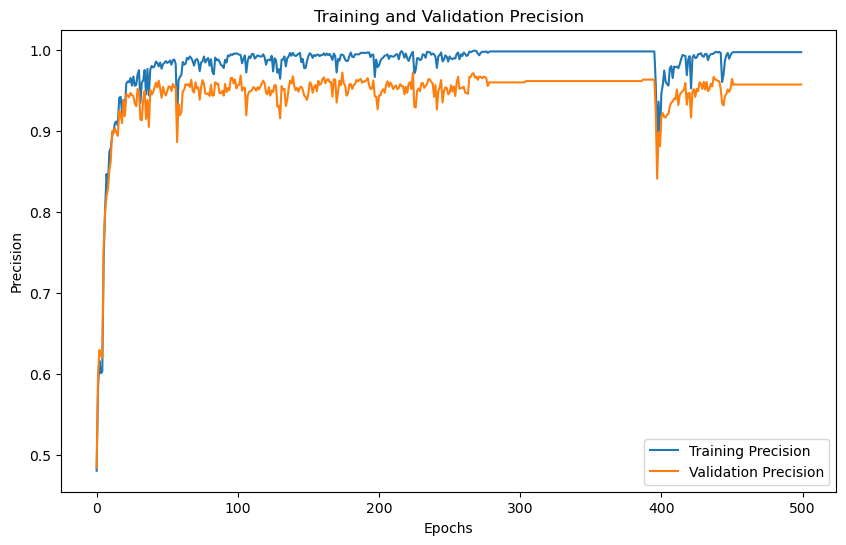

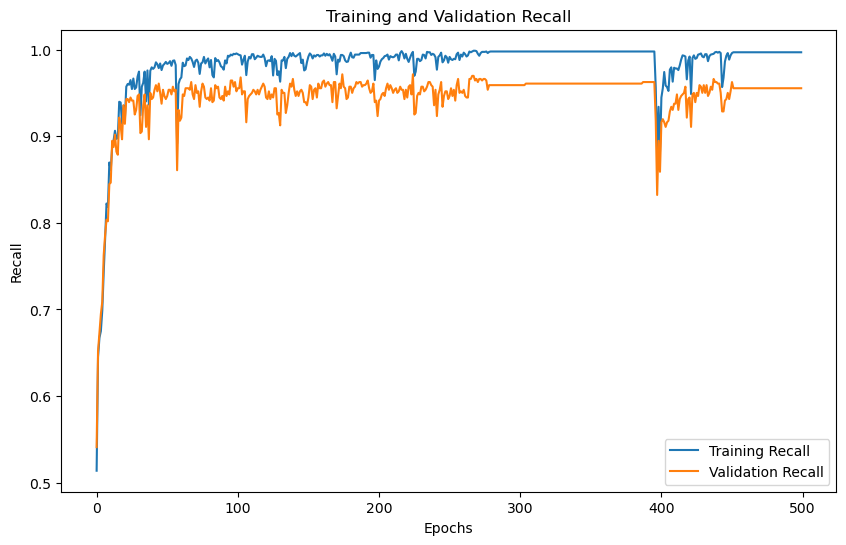

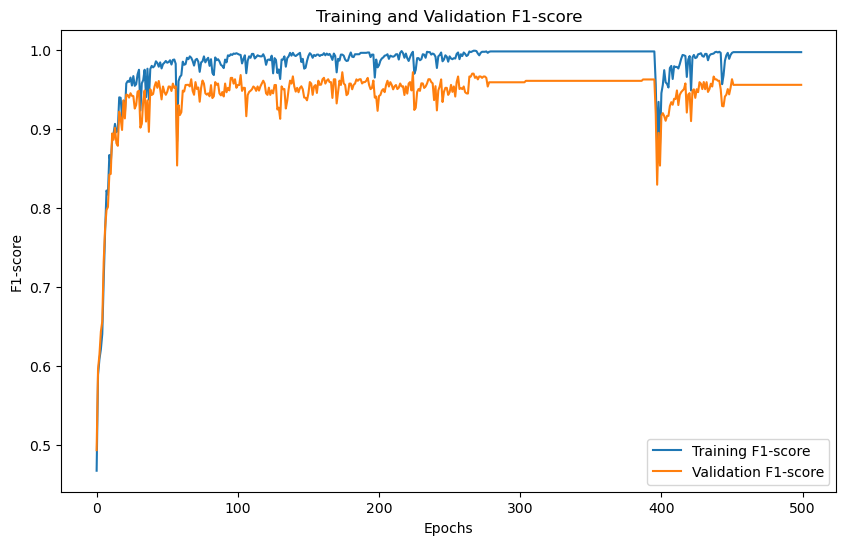

'Model Training and Evaluation Successfully completed'

In [31]:
train_model()

# N_MFCC 32

# 300 epoch

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  32
No. of classes 7
Training with N_MFCC: 32
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 32, 1)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7638, Training Accuracy: 0.6759, Training Precision:0.6059,Training Recall:0.6759,Training F1-Score:0.6279
Validation Loss: 1.5239, Validation Accuracy: 0.6821, Validation Precision:0.6027,Validation Recall:0.6821,Validation F1-Score:0.6262
Epoch [2/500],
Training Loss: 1.4413, Training Accuracy: 0.7826, Training Precision:0.8203,Training Recall:0.7826,Training F1-Score:0.7323
Validation Loss: 1.3932, Validation Accuracy: 0.7661, Validation Precision:0.8166,Validation Recall:0.7661,Validation F1-Score:0.7109
Epoch [3/500],
Training Loss: 1.3131, Training Accuracy: 0.8125, Training Precision:0.8673,Training Recall:0.8125,Training F1-Score:0.8170
Validation Loss: 1.3503, Validation Accuracy: 0.8107, Validation Precision:0

Epoch [31/500],
Training Loss: 1.2045, Training Accuracy: 0.9665, Training Precision:0.9665,Training Recall:0.9665,Training F1-Score:0.9664
Validation Loss: 1.2018, Validation Accuracy: 0.9679, Validation Precision:0.9681,Validation Recall:0.9679,Validation F1-Score:0.9675
Epoch [32/500],
Training Loss: 1.2129, Training Accuracy: 0.9647, Training Precision:0.9653,Training Recall:0.9647,Training F1-Score:0.9648
Validation Loss: 1.2097, Validation Accuracy: 0.9554, Validation Precision:0.9579,Validation Recall:0.9554,Validation F1-Score:0.9551
Epoch [33/500],
Training Loss: 1.2167, Training Accuracy: 0.9723, Training Precision:0.9728,Training Recall:0.9723,Training F1-Score:0.9724
Validation Loss: 1.2116, Validation Accuracy: 0.9518, Validation Precision:0.9526,Validation Recall:0.9518,Validation F1-Score:0.9517
Epoch [34/500],
Training Loss: 1.1938, Training Accuracy: 0.9768, Training Precision:0.9775,Training Recall:0.9768,Training F1-Score:0.9768
Validation Loss: 1.1930, Validation Ac

Epoch [61/500],
Training Loss: 1.2130, Training Accuracy: 0.9036, Training Precision:0.9091,Training Recall:0.9036,Training F1-Score:0.9032
Validation Loss: 1.2647, Validation Accuracy: 0.9018, Validation Precision:0.9062,Validation Recall:0.9018,Validation F1-Score:0.9007
Epoch [62/500],
Training Loss: 1.2077, Training Accuracy: 0.9710, Training Precision:0.9716,Training Recall:0.9710,Training F1-Score:0.9710
Validation Loss: 1.2018, Validation Accuracy: 0.9625, Validation Precision:0.9647,Validation Recall:0.9625,Validation F1-Score:0.9626
Epoch [63/500],
Training Loss: 1.2004, Training Accuracy: 0.9786, Training Precision:0.9790,Training Recall:0.9786,Training F1-Score:0.9786
Validation Loss: 1.2011, Validation Accuracy: 0.9643, Validation Precision:0.9649,Validation Recall:0.9643,Validation F1-Score:0.9643
Epoch [64/500],
Training Loss: 1.1937, Training Accuracy: 0.9589, Training Precision:0.9597,Training Recall:0.9589,Training F1-Score:0.9581
Validation Loss: 1.2212, Validation Ac

Epoch [91/500],
Training Loss: 1.1753, Training Accuracy: 0.9893, Training Precision:0.9894,Training Recall:0.9893,Training F1-Score:0.9893
Validation Loss: 1.1915, Validation Accuracy: 0.9732, Validation Precision:0.9738,Validation Recall:0.9732,Validation F1-Score:0.9732
Epoch [92/500],
Training Loss: 1.1777, Training Accuracy: 0.9902, Training Precision:0.9902,Training Recall:0.9902,Training F1-Score:0.9902
Validation Loss: 1.1908, Validation Accuracy: 0.9750, Validation Precision:0.9752,Validation Recall:0.9750,Validation F1-Score:0.9749
Epoch [93/500],
Training Loss: 1.1738, Training Accuracy: 0.9920, Training Precision:0.9921,Training Recall:0.9920,Training F1-Score:0.9920
Validation Loss: 1.1856, Validation Accuracy: 0.9786, Validation Precision:0.9786,Validation Recall:0.9786,Validation F1-Score:0.9786
Epoch [94/500],
Training Loss: 1.1813, Training Accuracy: 0.9857, Training Precision:0.9861,Training Recall:0.9857,Training F1-Score:0.9857
Validation Loss: 1.1946, Validation Ac

Epoch [121/500],
Training Loss: 1.1686, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1798, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9856
Epoch [122/500],
Training Loss: 1.1686, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1798, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9856
Epoch [123/500],
Training Loss: 1.1686, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1798, Validation Accuracy: 0.9857, Validation Precision:0.9859,Validation Recall:0.9857,Validation F1-Score:0.9856
Epoch [124/500],
Training Loss: 1.1686, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1797, Validatio

...

Epoch [361/500],
Training Loss: 1.1833, Training Accuracy: 0.9786, Training Precision:0.9793,Training Recall:0.9786,Training F1-Score:0.9786
Validation Loss: 1.2058, Validation Accuracy: 0.9589, Validation Precision:0.9599,Validation Recall:0.9589,Validation F1-Score:0.9589
Epoch [362/500],
Training Loss: 1.1856, Training Accuracy: 0.9839, Training Precision:0.9842,Training Recall:0.9839,Training F1-Score:0.9840
Validation Loss: 1.1970, Validation Accuracy: 0.9679, Validation Precision:0.9687,Validation Recall:0.9679,Validation F1-Score:0.9680
Epoch [363/500],
Training Loss: 1.1838, Training Accuracy: 0.9879, Training Precision:0.9880,Training Recall:0.9879,Training F1-Score:0.9879
Validation Loss: 1.2060, Validation Accuracy: 0.9589, Validation Precision:0.9592,Validation Recall:0.9589,Validation F1-Score:0.9588
Epoch [364/500],
Training Loss: 1.1810, Training Accuracy: 0.9799, Training Precision:0.9810,Training Recall:0.9799,Training F1-Score:0.9800
Validation Loss: 1.2166, Validatio

Epoch [391/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1948, Validation Accuracy: 0.9696, Validation Precision:0.9703,Validation Recall:0.9696,Validation F1-Score:0.9695
Epoch [392/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1949, Validation Accuracy: 0.9696, Validation Precision:0.9703,Validation Recall:0.9696,Validation F1-Score:0.9695
Epoch [393/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1950, Validation Accuracy: 0.9696, Validation Precision:0.9703,Validation Recall:0.9696,Validation F1-Score:0.9695
Epoch [394/500],
Training Loss: 1.1685, Training Accuracy: 0.9969, Training Precision:0.9969,Training Recall:0.9969,Training F1-Score:0.9969
Validation Loss: 1.1951, Validatio

Epoch [421/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1885, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [422/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1885, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [423/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1886, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [424/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1886, Validatio

Epoch [451/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1889, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [452/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1889, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [453/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1890, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [454/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1890, Validatio

Epoch [481/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1893, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [482/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1893, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [483/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1893, Validation Accuracy: 0.9750, Validation Precision:0.9753,Validation Recall:0.9750,Validation F1-Score:0.9748
Epoch [484/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1893, Validatio

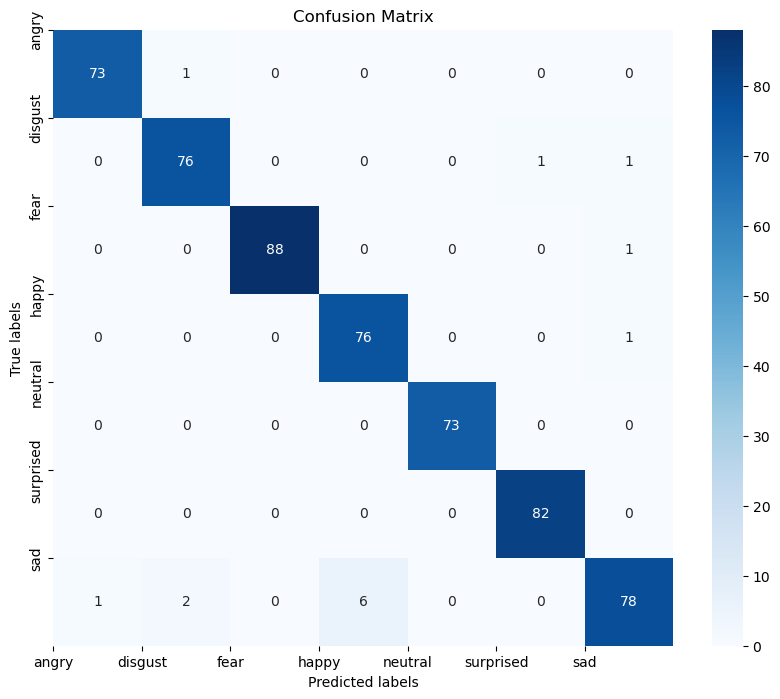

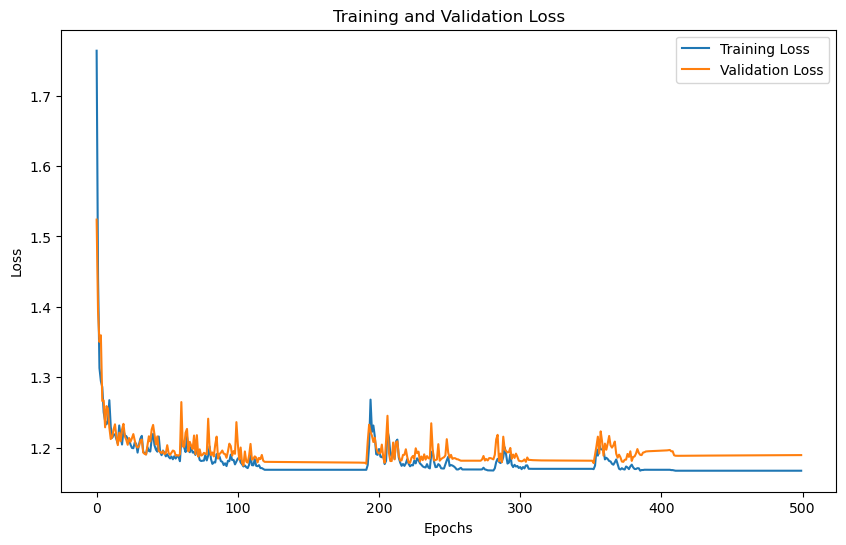

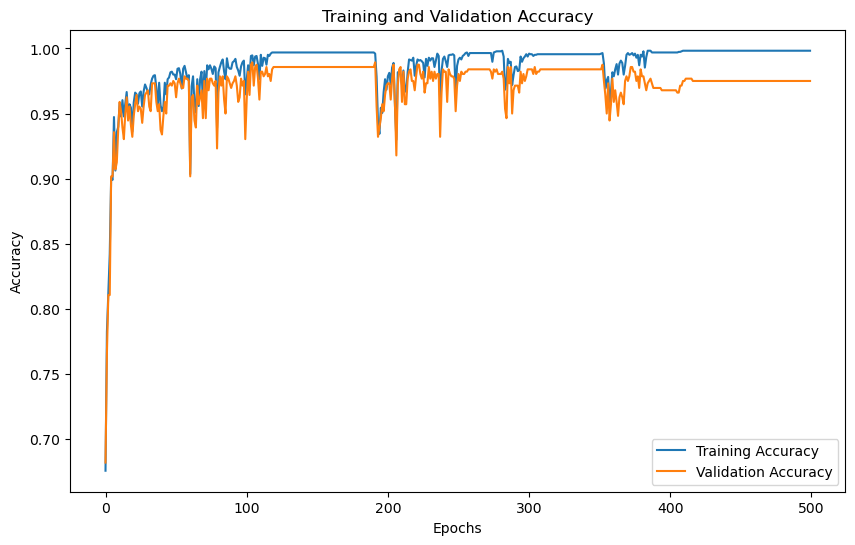

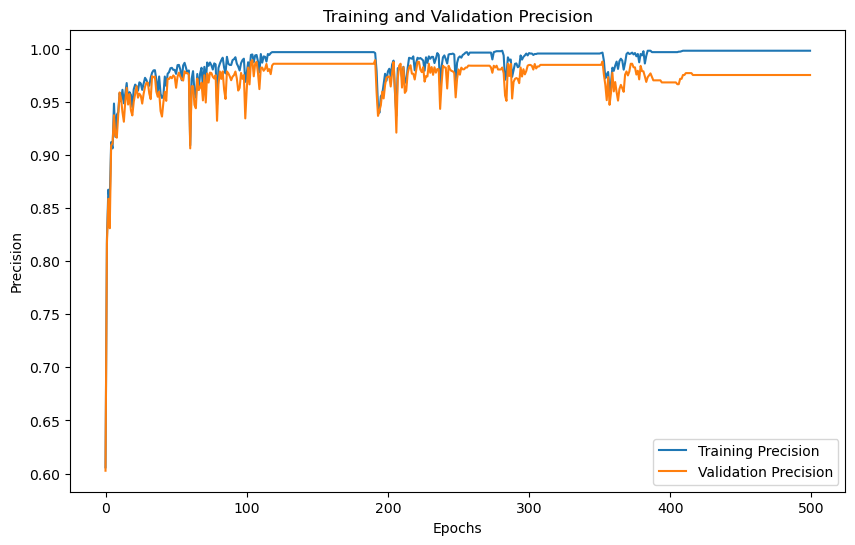

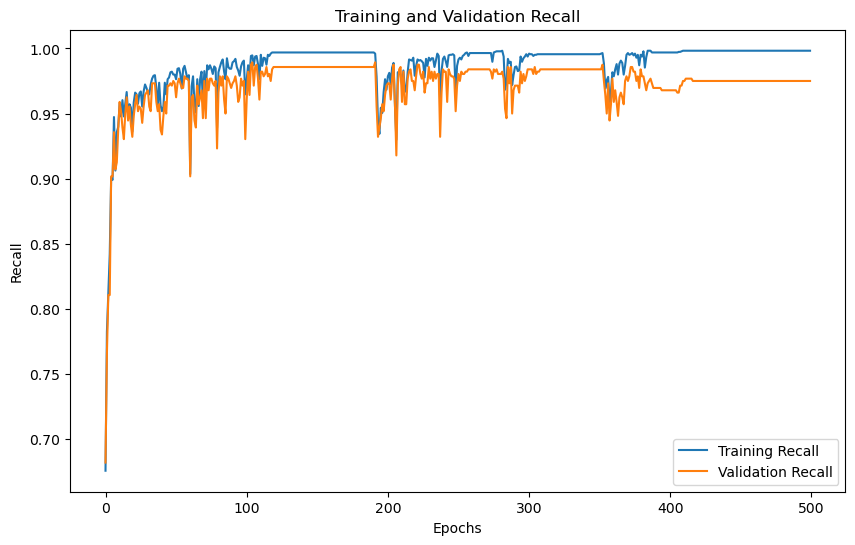

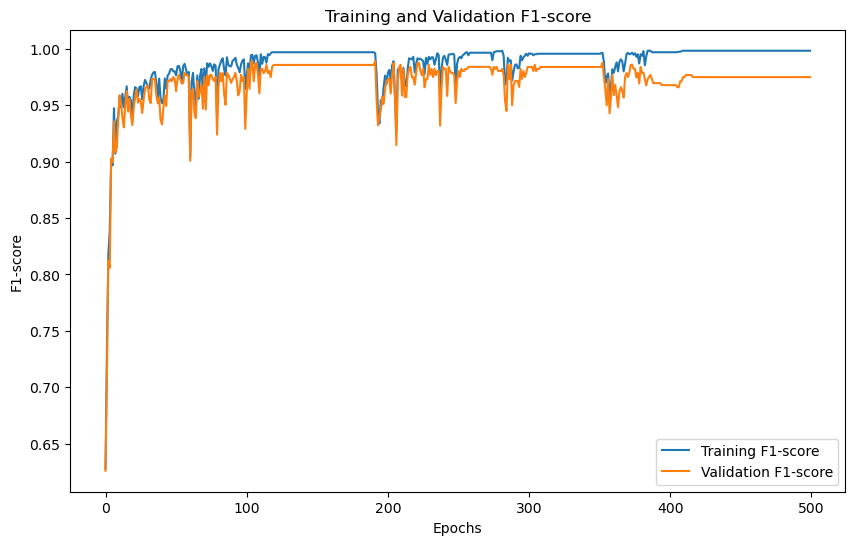

'Model Training and Evaluation Successfully completed'

In [11]:
train_model()

# N_MFCC 40

# 300 epochs

Enter dataset name:
tess, savee, crema, ravdess
 tess
Enter N_MFCC:  40
No. of classes 7
Training with N_MFCC: 40
Input size : 1
Hidden Size : 256
Model Name: LSTMModel

X Shape : (2800, 40, 1)
Y Shape : (2800, 7)

Enter no. of epochs 500
Epoch [1/500],
Training Loss: 1.7674, Training Accuracy: 0.6433, Training Precision:0.5090,Training Recall:0.6433,Training F1-Score:0.5548
Validation Loss: 1.5727, Validation Accuracy: 0.6518, Validation Precision:0.5060,Validation Recall:0.6518,Validation F1-Score:0.5580
Epoch [2/500],
Training Loss: 1.5380, Training Accuracy: 0.6937, Training Precision:0.6337,Training Recall:0.6937,Training F1-Score:0.6443
Validation Loss: 1.4838, Validation Accuracy: 0.6839, Validation Precision:0.6077,Validation Recall:0.6839,Validation F1-Score:0.6280
Epoch [3/500],
Training Loss: 1.4031, Training Accuracy: 0.7955, Training Precision:0.7006,Training Recall:0.7955,Training F1-Score:0.7404
Validation Loss: 1.3887, Validation Accuracy: 0.7804, Validation Precision:0

Epoch [31/500],
Training Loss: 1.1940, Training Accuracy: 0.9786, Training Precision:0.9790,Training Recall:0.9786,Training F1-Score:0.9785
Validation Loss: 1.1913, Validation Accuracy: 0.9750, Validation Precision:0.9762,Validation Recall:0.9750,Validation F1-Score:0.9749
Epoch [32/500],
Training Loss: 1.1930, Training Accuracy: 0.9821, Training Precision:0.9822,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 1.1887, Validation Accuracy: 0.9750, Validation Precision:0.9754,Validation Recall:0.9750,Validation F1-Score:0.9749
Epoch [33/500],
Training Loss: 1.1858, Training Accuracy: 0.9754, Training Precision:0.9759,Training Recall:0.9754,Training F1-Score:0.9755
Validation Loss: 1.1990, Validation Accuracy: 0.9679, Validation Precision:0.9687,Validation Recall:0.9679,Validation F1-Score:0.9681
Epoch [34/500],
Training Loss: 1.1916, Training Accuracy: 0.9652, Training Precision:0.9667,Training Recall:0.9652,Training F1-Score:0.9650
Validation Loss: 1.1969, Validation Ac

Epoch [61/500],
Training Loss: 1.1830, Training Accuracy: 0.9741, Training Precision:0.9752,Training Recall:0.9741,Training F1-Score:0.9740
Validation Loss: 1.1983, Validation Accuracy: 0.9679, Validation Precision:0.9694,Validation Recall:0.9679,Validation F1-Score:0.9681
Epoch [62/500],
Training Loss: 1.1850, Training Accuracy: 0.9835, Training Precision:0.9840,Training Recall:0.9835,Training F1-Score:0.9834
Validation Loss: 1.2025, Validation Accuracy: 0.9625, Validation Precision:0.9647,Validation Recall:0.9625,Validation F1-Score:0.9624
Epoch [63/500],
Training Loss: 1.1787, Training Accuracy: 0.9616, Training Precision:0.9630,Training Recall:0.9616,Training F1-Score:0.9608
Validation Loss: 1.2165, Validation Accuracy: 0.9500, Validation Precision:0.9529,Validation Recall:0.9500,Validation F1-Score:0.9491
Epoch [64/500],
Training Loss: 1.2089, Training Accuracy: 0.9737, Training Precision:0.9742,Training Recall:0.9737,Training F1-Score:0.9736
Validation Loss: 1.1928, Validation Ac

Epoch [91/500],
Training Loss: 1.1717, Training Accuracy: 0.9946, Training Precision:0.9946,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.1929, Validation Accuracy: 0.9714, Validation Precision:0.9714,Validation Recall:0.9714,Validation F1-Score:0.9712
Epoch [92/500],
Training Loss: 1.1728, Training Accuracy: 0.9911, Training Precision:0.9913,Training Recall:0.9911,Training F1-Score:0.9911
Validation Loss: 1.1897, Validation Accuracy: 0.9768, Validation Precision:0.9775,Validation Recall:0.9768,Validation F1-Score:0.9768
Epoch [93/500],
Training Loss: 1.1772, Training Accuracy: 0.9821, Training Precision:0.9825,Training Recall:0.9821,Training F1-Score:0.9821
Validation Loss: 1.1998, Validation Accuracy: 0.9661, Validation Precision:0.9669,Validation Recall:0.9661,Validation F1-Score:0.9658
Epoch [94/500],
Training Loss: 1.1993, Training Accuracy: 0.9799, Training Precision:0.9803,Training Recall:0.9799,Training F1-Score:0.9800
Validation Loss: 1.1931, Validation Ac

Epoch [121/500],
Training Loss: 1.1754, Training Accuracy: 0.9830, Training Precision:0.9834,Training Recall:0.9830,Training F1-Score:0.9830
Validation Loss: 1.1954, Validation Accuracy: 0.9696, Validation Precision:0.9707,Validation Recall:0.9696,Validation F1-Score:0.9695
Epoch [122/500],
Training Loss: 1.1845, Training Accuracy: 0.9835, Training Precision:0.9837,Training Recall:0.9835,Training F1-Score:0.9835
Validation Loss: 1.1951, Validation Accuracy: 0.9696, Validation Precision:0.9706,Validation Recall:0.9696,Validation F1-Score:0.9696
Epoch [123/500],
Training Loss: 1.1846, Training Accuracy: 0.9875, Training Precision:0.9879,Training Recall:0.9875,Training F1-Score:0.9874
Validation Loss: 1.1926, Validation Accuracy: 0.9714, Validation Precision:0.9725,Validation Recall:0.9714,Validation F1-Score:0.9711
Epoch [124/500],
Training Loss: 1.1760, Training Accuracy: 0.9946, Training Precision:0.9947,Training Recall:0.9946,Training F1-Score:0.9946
Validation Loss: 1.1851, Validatio

...

Epoch [361/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1770, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [362/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1770, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [363/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1770, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [364/500],
Training Loss: 1.1672, Training Accuracy: 0.9982, Training Precision:0.9982,Training Recall:0.9982,Training F1-Score:0.9982
Validation Loss: 1.1769, Validatio

Epoch [391/500],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1767, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [392/500],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1767, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [393/500],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1767, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [394/500],
Training Loss: 1.1668, Training Accuracy: 0.9987, Training Precision:0.9987,Training Recall:0.9987,Training F1-Score:0.9987
Validation Loss: 1.1767, Validatio

Epoch [421/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1780, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [422/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1779, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [423/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1779, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [424/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1779, Validatio

Epoch [451/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1774, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [452/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1774, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [453/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1774, Validation Accuracy: 0.9875, Validation Precision:0.9877,Validation Recall:0.9875,Validation F1-Score:0.9875
Epoch [454/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1774, Validatio

Epoch [481/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1770, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [482/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1770, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [483/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1770, Validation Accuracy: 0.9893, Validation Precision:0.9895,Validation Recall:0.9893,Validation F1-Score:0.9893
Epoch [484/500],
Training Loss: 1.1663, Training Accuracy: 0.9991, Training Precision:0.9991,Training Recall:0.9991,Training F1-Score:0.9991
Validation Loss: 1.1770, Validatio

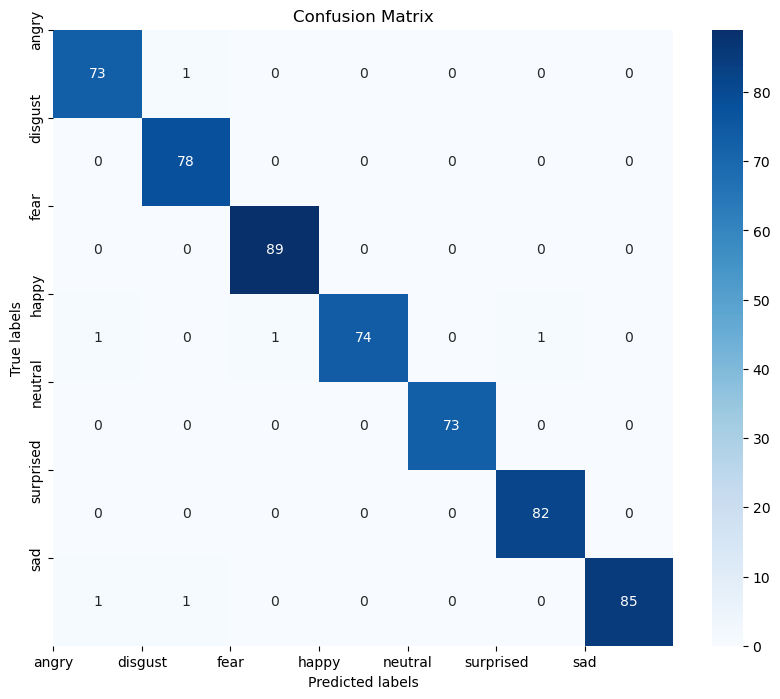

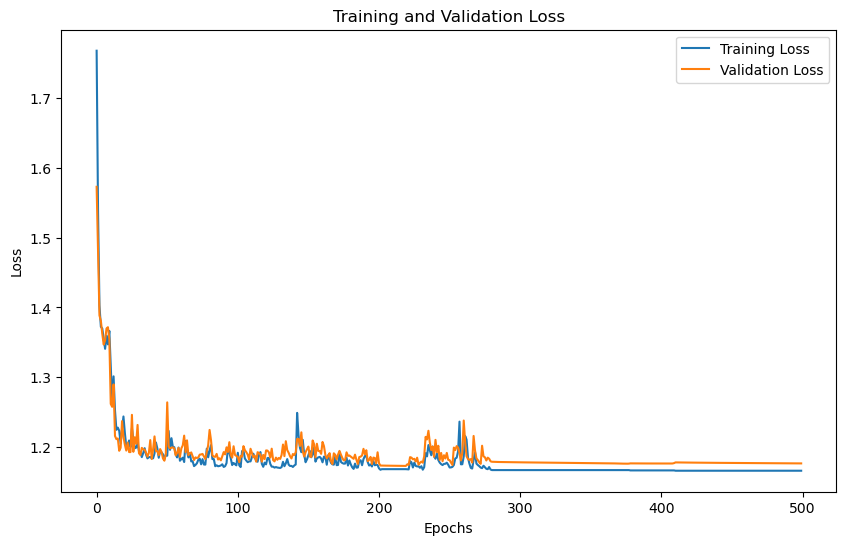

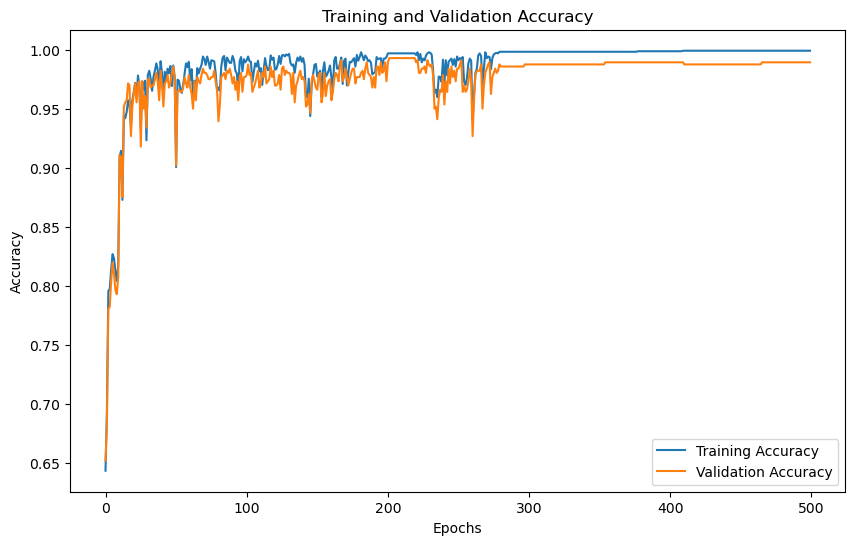

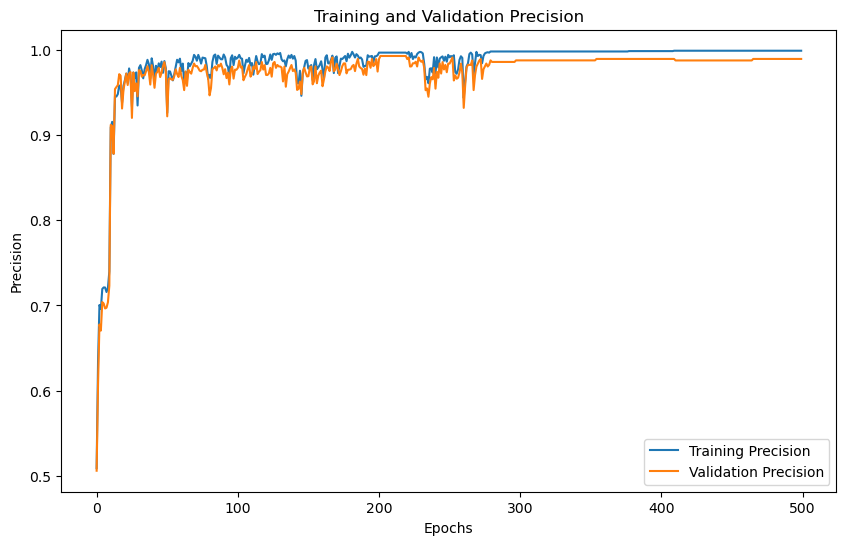

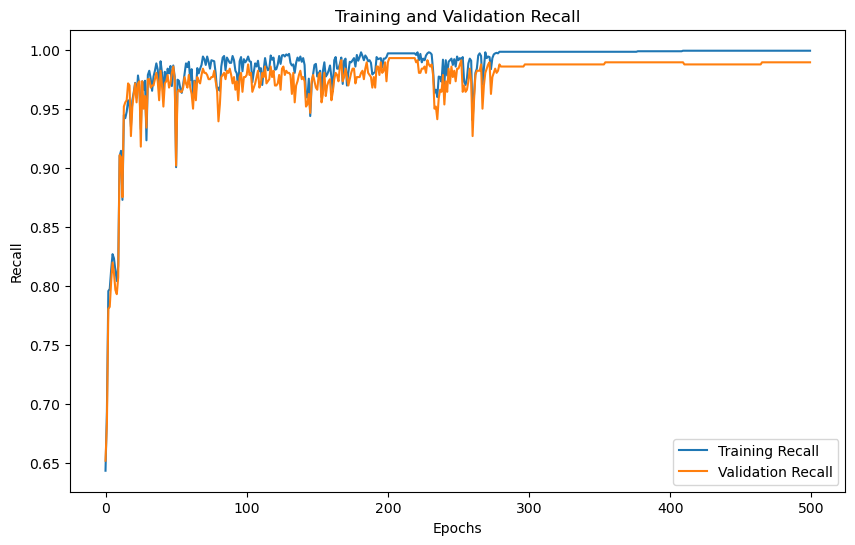

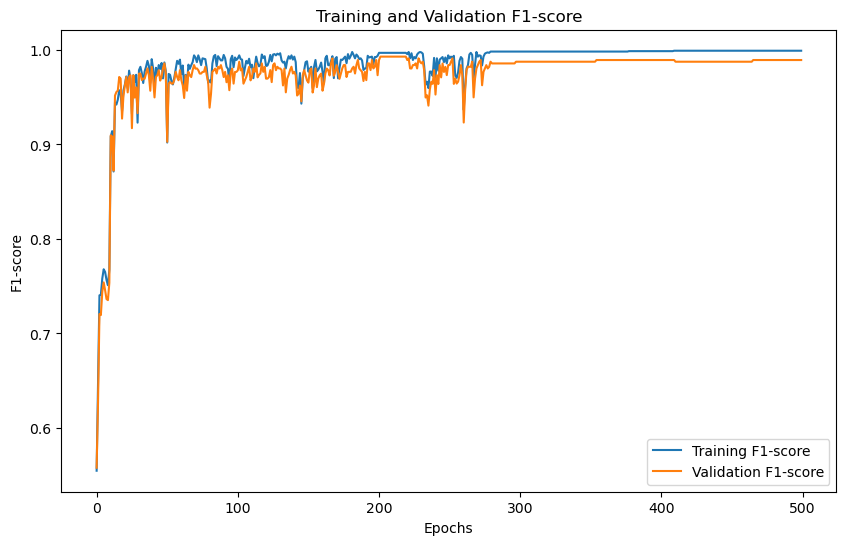

'Model Training and Evaluation Successfully completed'

In [12]:
train_model()